In [ ]:
# !pip install ucimlrepo tensorflow   # descomente se necessário
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__)
pd.set_option("display.float_format", "{:.4f}".format)

In [ ]:
bean = fetch_ucirepo(id=602)
df = bean.data.original.copy()
print(df.shape)
df['Class'].value_counts()

In [ ]:
df['Class'].value_counts(normalize=True).round(3)

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

In [ ]:
# Transformação da classe em coluna numérica
df['rotulo'] = df['Class'].astype('category').cat.codes
classes = dict(df[['rotulo', 'Class']].drop_duplicates().sort_values('rotulo').values)
print(classes)

df_encoded = df.drop('Class', axis=1)
df_encoded.describe().T

Class
DERMASON    0.261
SIRA        0.194
SEKER       0.149
HOROZ       0.142
CALI        0.120
BARBUNYA    0.097
BOMBAY      0.038
Name: proportion, dtype: float64

In [ ]:
print("Linhas duplicadas:", df_encoded.duplicated().sum())
# Remoção das duplicadas (atribuindo o resultado e descartando o índice antigo)
df_encoded = df_encoded.drop_duplicates().reset_index(drop=True)
print("Shape após remoção:", df_encoded.shape)

feats = df_encoded.columns.drop('rotulo')
X = df_encoded[feats].values.astype('float32')
Y = df_encoded['rotulo'].values
n_features, n_classes = X.shape[1], len(classes)
print(f"{n_features} atributos, {n_classes} classes")

{np.int8(5): 'SEKER', np.int8(0): 'BARBUNYA', np.int8(1): 'BOMBAY', np.int8(2): 'CALI', np.int8(4): 'HOROZ', np.int8(6): 'SIRA', np.int8(3): 'DERMASON'}


In [ ]:
SPLIT_SEED = 42
X_trainfull, X_test, y_trainfull, y_test = train_test_split(
    X, Y, test_size=0.20, stratify=Y, random_state=SPLIT_SEED)   # X_test/y_test NÃO serão usados aqui

X_tr, X_val, y_tr, y_val = train_test_split(
    X_trainfull, y_trainfull, test_size=0.15, stratify=y_trainfull, random_state=SPLIT_SEED)

scaler = StandardScaler().fit(X_tr)
X_tr_s, X_val_s = scaler.transform(X_tr), scaler.transform(X_val)

# One-hot para a Entropia Cruzada Categórica
Y_tr  = keras.utils.to_categorical(y_tr,  n_classes)
Y_val = keras.utils.to_categorical(y_val, n_classes)

print(f"Treino: {X_tr_s.shape} | Validação: {X_val_s.shape} | Teste (reservado): {X_test.shape}")

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860154
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRatio,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


In [ ]:
CONFIG = dict(
    hidden_units=[64, 32],
    hidden_activation='relu',
    output_activation='softmax',
    learning_rate=0.01,
    momentum=0.0,
    epochs=100,
    batch_size=32,
)
SEEDS = [0, 1, 2, 3, 4]   # uma semente por treinamento -> 5 inicializações diferentes


def build_mlp(seed, cfg=CONFIG):
    """MLP com pesos inicializados a partir da semente informada."""
    model = keras.Sequential([keras.Input(shape=(n_features,))])
    for i, units in enumerate(cfg['hidden_units']):
        model.add(layers.Dense(units, activation=cfg['hidden_activation'],
                               kernel_initializer=keras.initializers.HeNormal(seed=seed + i),
                               name=f'oculta_{i+1}'))
    model.add(layers.Dense(n_classes, activation=cfg['output_activation'],
                           kernel_initializer=keras.initializers.GlorotUniform(seed=seed + 100),
                           name='saida'))
    model.compile(
        optimizer=keras.optimizers.SGD(learning_rate=cfg['learning_rate'], momentum=cfg['momentum']),
        loss=keras.losses.CategoricalCrossentropy(),
        metrics=['accuracy'])
    return model

build_mlp(0).summary()

np.int64(68)

In [8]:
def reset_seeds(seed):
    """Reinicia todos os geradores de números aleatórios (Python, NumPy, TensorFlow)."""
    keras.backend.clear_session()
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)
    keras.utils.set_random_seed(seed)

histories, init_weights, models, rows = {}, {}, {}, []

for seed in SEEDS:
    reset_seeds(seed)
    model = build_mlp(seed)
    init_weights[seed] = model.get_layer('oculta_1').get_weights()[0].ravel().copy()
    loss0, acc0 = model.evaluate(X_tr_s, Y_tr, verbose=0)          # antes de treinar

    h = model.fit(X_tr_s, Y_tr, validation_data=(X_val_s, Y_val),
                  epochs=CONFIG['epochs'], batch_size=CONFIG['batch_size'],
                  shuffle=True, verbose=0)
    hist = pd.DataFrame(h.history); hist.index += 1
    histories[seed], models[seed] = hist, model

    acc_tr = hist['accuracy']
    rows.append({
        'Semente': seed,
        'Perda inicial': loss0,
        'Acurácia inicial': acc0,
        'Perda final (treino)': hist['loss'].iloc[-1],
        'Acurácia final (treino)': acc_tr.iloc[-1],
        'Perda final (val)': hist['val_loss'].iloc[-1],
        'Acurácia final (val)': hist['val_accuracy'].iloc[-1],
        'Época p/ 90% (treino)': int(acc_tr.ge(0.90).idxmax()) if acc_tr.ge(0.90).any() else np.nan,
        'Melhor época (val_loss)': int(hist['val_loss'].idxmin()),
    })
    print(f"Semente {seed}: perda={hist['loss'].iloc[-1]:.4f}  acc={acc_tr.iloc[-1]:.4f}  "
          f"| val_perda={hist['val_loss'].iloc[-1]:.4f}  val_acc={hist['val_accuracy'].iloc[-1]:.4f}")

resultados = pd.DataFrame(rows).set_index('Semente')

Semente 0: perda=0.1730  acc=0.9359  | val_perda=0.1602  val_acc=0.9453
Semente 1: perda=0.1754  acc=0.9359  | val_perda=0.1627  val_acc=0.9477
Semente 2: perda=0.1771  acc=0.9339  | val_perda=0.1637  val_acc=0.9397
Semente 3: perda=0.1736  acc=0.9353  | val_perda=0.1620  val_acc=0.9440
Semente 4: perda=0.1712  acc=0.9356  | val_perda=0.1673  val_acc=0.9471


In [9]:
resumo = resultados.agg(['mean', 'std', 'min', 'max'])
resumo.index = ['Média', 'Desvio padrão', 'Mínimo', 'Máximo']
display(resultados)
display(resumo)

,Perda inicial,Acurácia inicial,Perda final (treino),Acurácia final (treino),Perda final (val),Acurácia final (val),Época p/ 90% (treino),Melhor época (val_loss)
Semente,,,,,,,,
0,2.298917,0.130756,0.172980,0.935925,0.160222,0.945264,3,100
1,2.705304,0.078301,0.175424,0.935925,0.162720,0.947724,4,100
2,3.656591,0.144331,0.177083,0.933862,0.163662,0.939729,4,99
3,2.002952,0.173436,0.173559,0.935274,0.162039,0.944034,4,95
4,2.905178,0.096329,0.171194,0.935600,0.167279,0.947109,3,76


,Perda inicial,Acurácia inicial,Perda final (treino),Acurácia final (treino),Perda final (val),Acurácia final (val),Época p/ 90% (treino),Melhor época (val_loss)
Média,2.713788,0.124631,0.174048,0.935317,0.163184,0.944772,3.600000,94.000000
Desvio padrão,0.633045,0.037931,0.002271,0.000857,0.002612,0.003178,0.547723,10.271319
Mínimo,2.002952,0.078301,0.171194,0.933862,0.160222,0.939729,3.000000,76.000000
Máximo,3.656591,0.173436,0.177083,0.935925,0.167279,0.947724,4.000000,100.000000


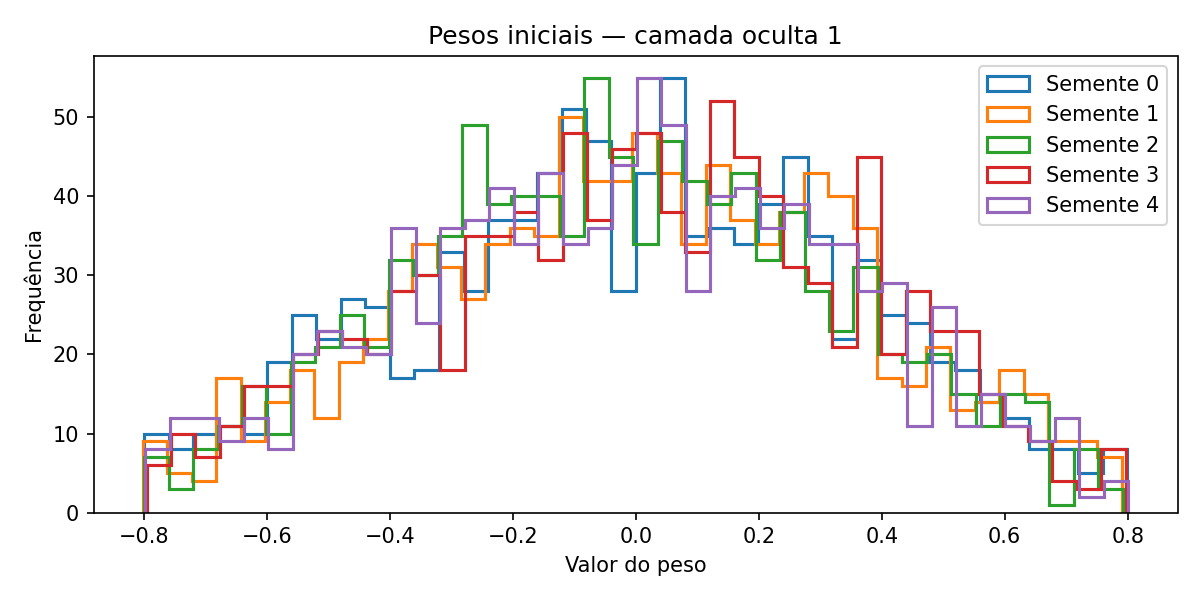

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
for seed in SEEDS:
    ax.hist(init_weights[seed], bins=40, histtype='step', linewidth=1.5, label=f'Semente {seed}')
ax.set(title='Pesos iniciais — camada oculta 1', xlabel='valor do peso', ylabel='frequência')
ax.legend(); plt.tight_layout(); plt.show()

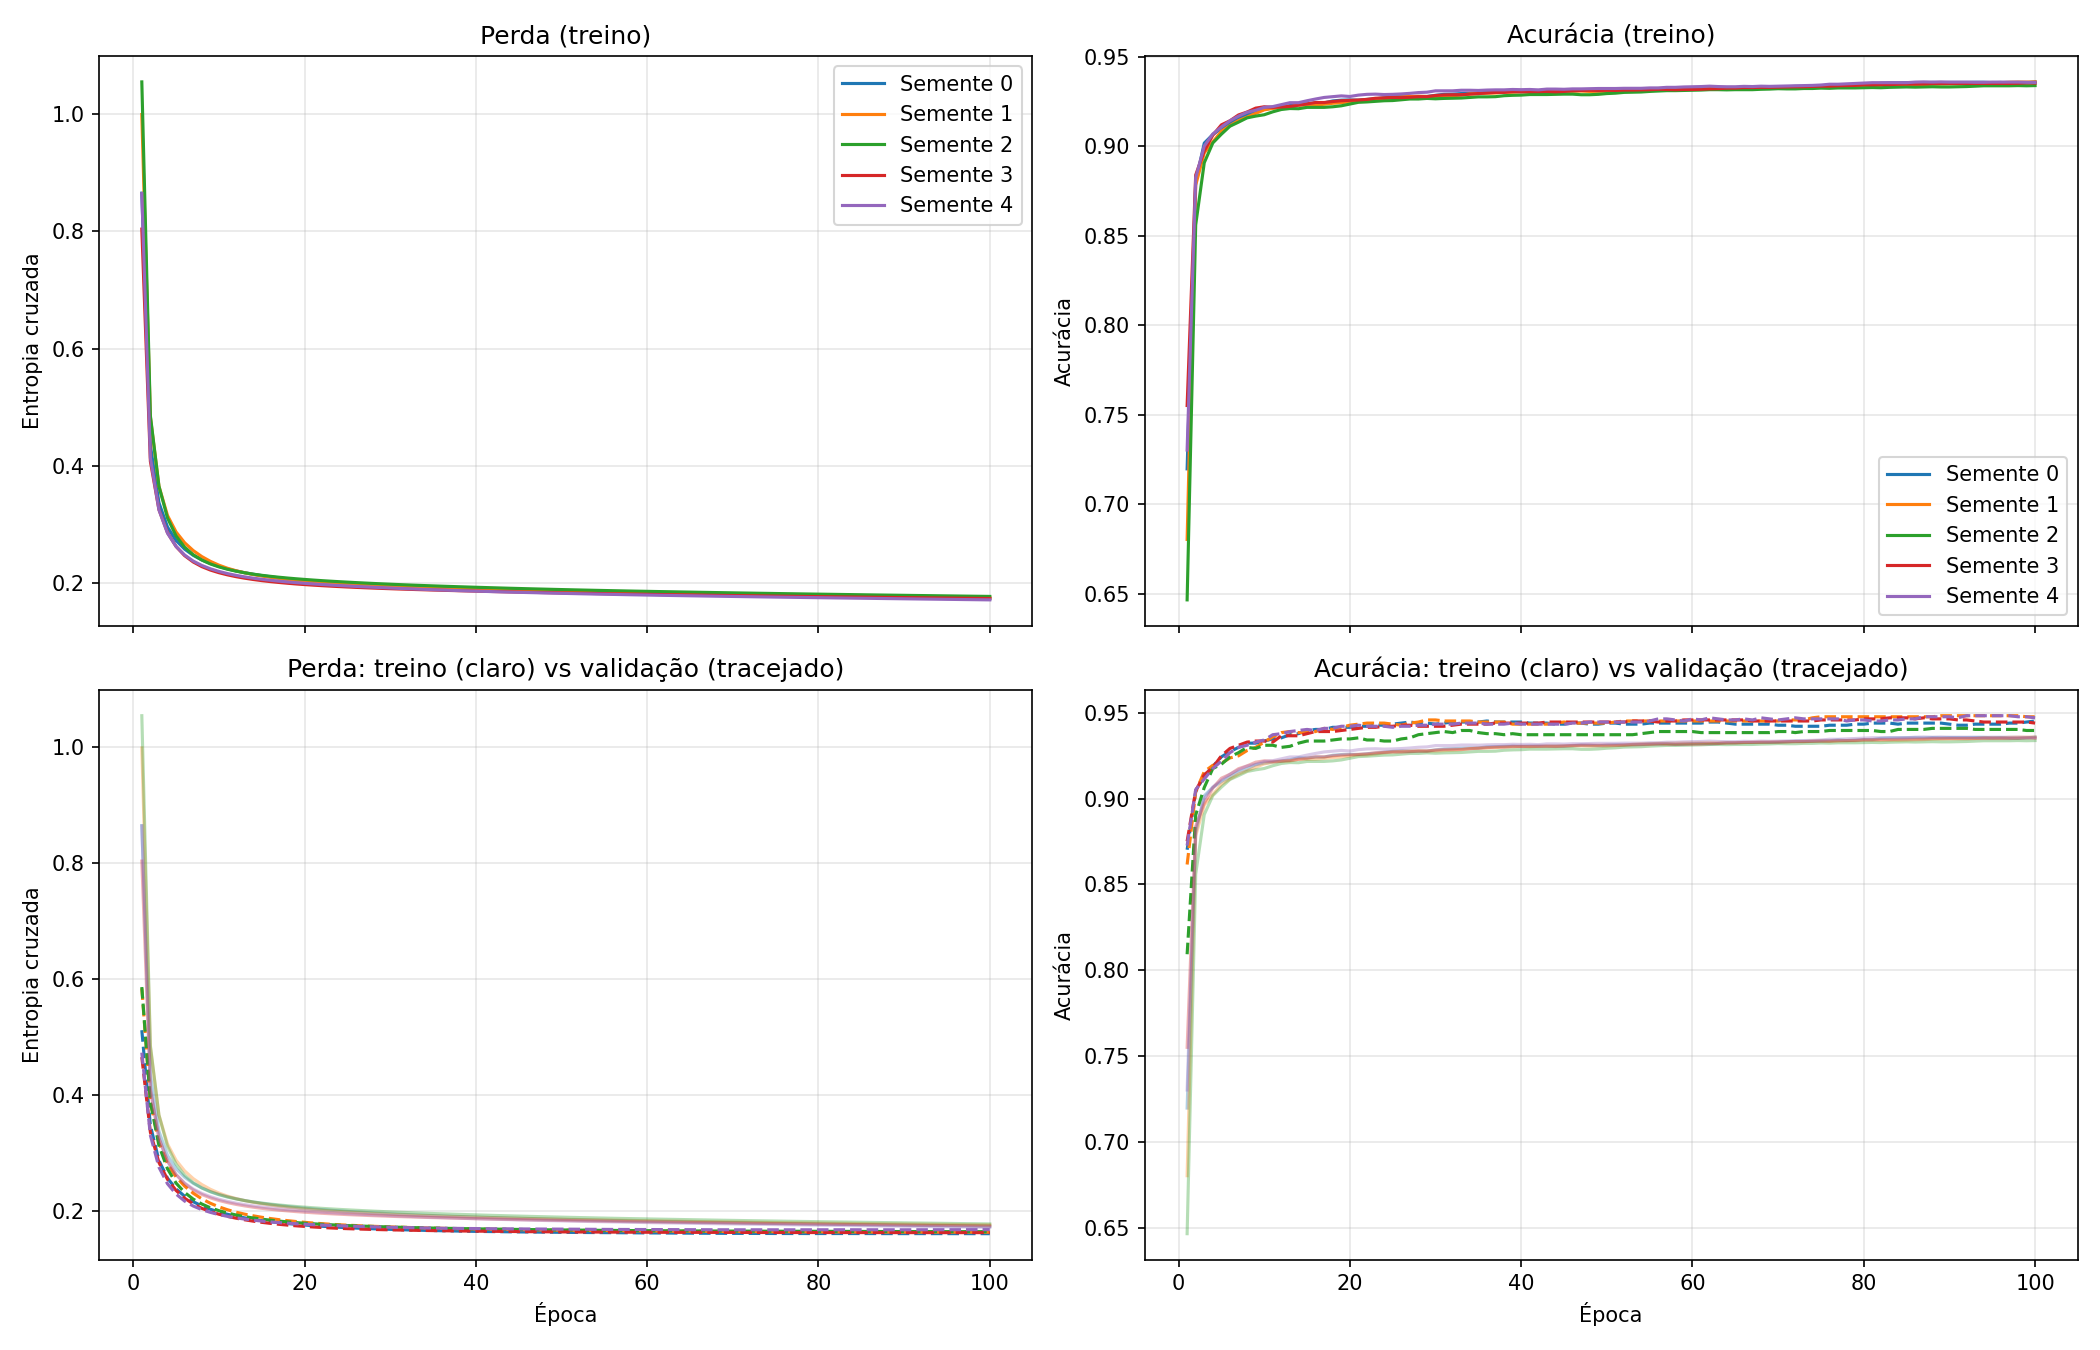

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
cores = plt.cm.tab10.colors
for k, seed in enumerate(SEEDS):
    h = histories[seed]
    axes[0, 0].plot(h['loss'], color=cores[k], label=f'Semente {seed}')
    axes[0, 1].plot(h['accuracy'], color=cores[k], label=f'Semente {seed}')
    axes[1, 0].plot(h['loss'], color=cores[k], alpha=.35)
    axes[1, 0].plot(h['val_loss'], color=cores[k], linestyle='--')
    axes[1, 1].plot(h['accuracy'], color=cores[k], alpha=.35)
    axes[1, 1].plot(h['val_accuracy'], color=cores[k], linestyle='--')

axes[0, 0].set(title='Perda (treino)', ylabel='Entropia cruzada')
axes[0, 1].set(title='Acurácia (treino)', ylabel='Acurácia')
axes[1, 0].set(title='Perda: treino (claro) vs validação (tracejado)', xlabel='Época', ylabel='Entropia cruzada')
axes[1, 1].set(title='Acurácia: treino (claro) vs validação (tracejado)', xlabel='Época', ylabel='Acurácia')
for ax in axes.ravel(): ax.grid(alpha=.3)
axes[0, 0].legend(); axes[0, 1].legend(loc='lower right')
plt.tight_layout(); plt.show()

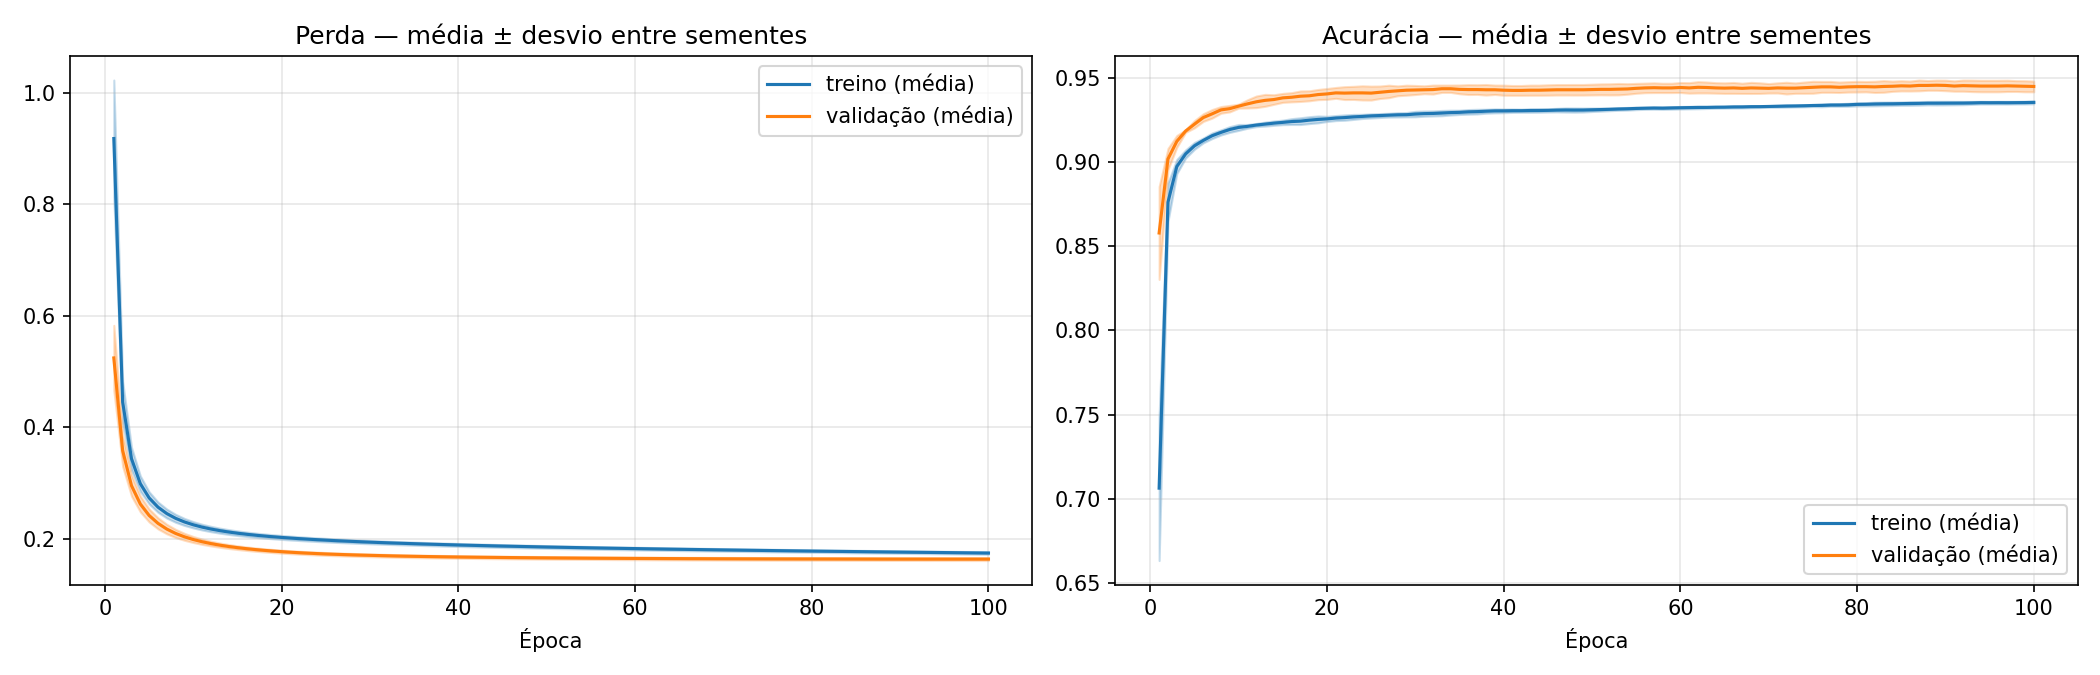

In [12]:
# Média ± desvio padrão entre as 5 inicializações
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, met, titulo in [(axes[0], 'loss', 'Perda'), (axes[1], 'accuracy', 'Acurácia')]:
    for suf, cor, nome in [('', 'tab:blue', 'treino'), ('val_', 'tab:orange', 'validação')]:
        M = pd.concat([histories[s][suf + met] for s in SEEDS], axis=1)
        m, sd = M.mean(axis=1), M.std(axis=1)
        ax.plot(m, color=cor, label=f'{nome} (média)')
        ax.fill_between(m.index, m - sd, m + sd, color=cor, alpha=.25)
    ax.set(title=f'{titulo} — média ± desvio entre sementes', xlabel='Época'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

Semente 4

              precision    recall  f1-score   support

    BARBUNYA      0.961     0.928     0.944       898
      BOMBAY      1.000     1.000     1.000       355
        CALI      0.940     0.960     0.950      1108
    DERMASON      0.912     0.949     0.930      2411
       HOROZ      0.966     0.953     0.959      1265
       SEKER      0.957     0.961     0.959      1378
        SIRA      0.904     0.864     0.884      1793

    accuracy                          0.936      9208
   macro avg      0.948     0.945     0.947      9208
weighted avg      0.936     0.936     0.936      9208



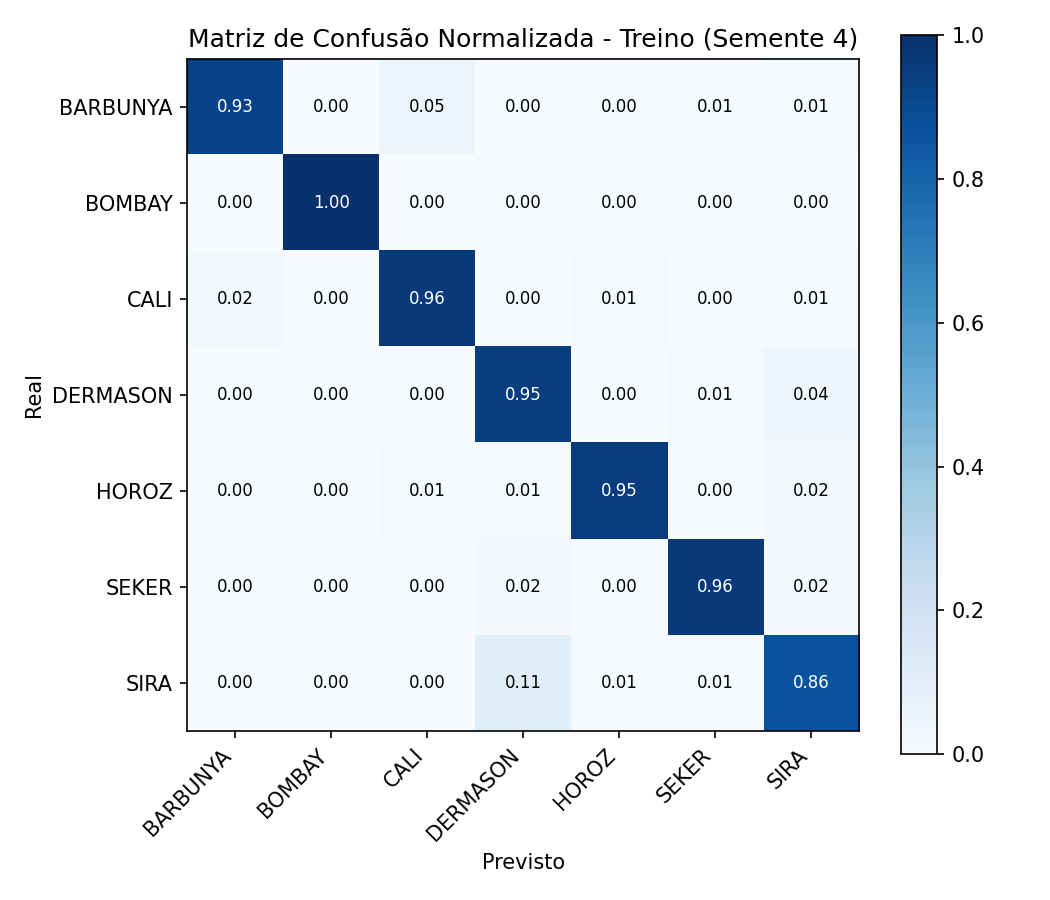

In [13]:
melhor = resultados['Perda final (treino)'].idxmin()
pred = models[melhor].predict(X_tr_s, verbose=0).argmax(axis=1)
nomes = [classes[i] for i in range(n_classes)]
print(f"Semente {melhor}\n")
print(classification_report(y_tr, pred, target_names=nomes, digits=3))

cm = confusion_matrix(y_tr, pred, normalize='true')
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(n_classes), nomes, rotation=45, ha='right'); ax.set_yticks(range(n_classes), nomes)
for i in range(n_classes):
    for j in range(n_classes):
        ax.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', color='white' if cm[i, j] > .5 else 'black', fontsize=8)
ax.set(xlabel='Previsto', ylabel='Real', title='Matriz de confusão normalizada (treino)')
plt.colorbar(im); plt.tight_layout(); plt.show()

In [14]:
r, s = resultados, resumo
acc_tr, acc_val = r['Acurácia final (treino)'], r['Acurácia final (val)']
loss_tr, loss_val = r['Perda final (treino)'], r['Perda final (val)']
gap = (acc_tr - acc_val).mean()
gap_loss = (loss_val - loss_tr).mean()
cv_loss = loss_tr.std() / loss_tr.mean() * 100
amp_acc = (acc_tr.max() - acc_tr.min()) * 100
ep90 = r['Época p/ 90% (treino)']
best_ep = r['Melhor época (val_loss)']

# Diagnóstico de over/underfitting
if acc_tr.mean() < 0.85:
    diag = ("a acurácia de treino ainda é relativamente baixa, o que sugere **underfitting** — o modelo pode precisar de "
            "mais épocas, maior taxa de aprendizado ou mais capacidade.")
elif gap > 0.03 or gap_loss > 0.05:
    diag = (f"há uma diferença perceptível entre treino e validação (acurácia {gap*100:.2f} p.p. maior no treino), "
            "indicando **início de overfitting**; regularização ou parada antecipada seriam recomendáveis.")
else:
    diag = (f"treino e validação permanecem próximos (diferença média de {gap*100:.2f} p.p. na acurácia e "
            f"{gap_loss:+.4f} na perda), **sem indícios relevantes de overfitting**; como a acurácia de treino é alta, "
            "também **não há underfitting**.")

if best_ep.mean() < CONFIG['epochs'] * 0.8:
    obs_ep = (f"A menor perda de validação ocorreu, em média, na época {best_ep.mean():.0f}; depois disso a validação "
              "estabiliza ou piora levemente, sinal de que o ganho adicional vem principalmente do ajuste ao treino.")
else:
    obs_ep = (f"A perda de validação ainda caía nas últimas épocas (melhor época média: {best_ep.mean():.0f}), "
              "o que indica que o modelo não saturou e poderia se beneficiar de mais épocas.")

rec = pd.Series(np.diag(cm), index=nomes).sort_values()
piores = ', '.join(f"{c} ({v*100:.1f}%)" for c, v in rec.head(3).items())
melhor_cls = f"{rec.index[-1]} ({rec.iloc[-1]*100:.1f}%)"
sens = "baixa" if cv_loss < 5 and amp_acc < 1 else ("moderada" if cv_loss < 15 and amp_acc < 3 else "alta")

display(Markdown(f'''
**Resumo numérico (5 inicializações)**

| Métrica | Média ± desvio | Mín – Máx |
|---|---|---|
| Perda final (treino) | {loss_tr.mean():.4f} ± {loss_tr.std():.4f} | {loss_tr.min():.4f} – {loss_tr.max():.4f} |
| Acurácia final (treino) | {acc_tr.mean():.4f} ± {acc_tr.std():.4f} | {acc_tr.min():.4f} – {acc_tr.max():.4f} |
| Perda final (validação) | {loss_val.mean():.4f} ± {loss_val.std():.4f} | {loss_val.min():.4f} – {loss_val.max():.4f} |
| Acurácia final (validação) | {acc_val.mean():.4f} ± {acc_val.std():.4f} | {acc_val.min():.4f} – {acc_val.max():.4f} |
| Perda inicial (antes do treino) | {r['Perda inicial'].mean():.4f} ± {r['Perda inicial'].std():.4f} | {r['Perda inicial'].min():.4f} – {r['Perda inicial'].max():.4f} |
| Época em que atinge 90% (treino) | {ep90.mean():.1f} ± {ep90.std():.1f} | {ep90.min():.0f} – {ep90.max():.0f} |

### c. Análise e discussão
- **Comparação entre os treinamentos:** as cinco execuções partem de perdas iniciais diferentes
  ({r['Perda inicial'].min():.3f} a {r['Perda inicial'].max():.3f}; o valor de referência para palpite aleatório é
  ln(7) ≈ {np.log(n_classes):.3f}), mas convergem para perdas finais de {loss_tr.min():.4f} a {loss_tr.max():.4f}.
  A acurácia de 90% no treino é atingida entre as épocas {ep90.min():.0f} e {ep90.max():.0f}, ou seja, a inicialização
  afeta sobretudo a **velocidade inicial** de convergência, e pouco o ponto final.
- **Estabilidade e desempenho:** coeficiente de variação da perda final = {cv_loss:.2f}% e amplitude da acurácia final
  de treino = {amp_acc:.2f} p.p. Nenhuma execução divergiu ou ficou presa em platô.
- **Underfitting / overfitting:** {diag} {obs_ep}
- **Sensibilidade à inicialização:** **{sens}**. Com He Normal + ReLU e dados padronizados, os pontos de partida
  diferentes levam a mínimos de qualidade equivalente.
- **Comportamento geral:** a perda cai rapidamente nas primeiras épocas e depois decresce de forma lenta e suave,
  padrão esperado do SGD com taxa fixa. Pela matriz de confusão, as classes com menor recall no treino são
  {piores} — em geral variedades de formato parecido —, enquanto {melhor_cls} é a mais bem separada.

### d. Conclusão da etapa
- O modelo **foi capaz de aprender os padrões básicos** das 7 classes, com acurácia média de treino de
  {acc_tr.mean()*100:.2f}% e validação de {acc_val.mean()*100:.2f}%.
- **ReLU + Softmax** se mostraram adequadas: convergência sem saturação e saídas probabilísticas coerentes com a
  entropia cruzada categórica.
- O treinamento é **estável** frente à inicialização dos pesos (variação {sens}), de modo que a topologia
  16-64-32-7 fica validada como base para a **Questão 2** (efeito da taxa de aprendizado e do momento).
'''))

**Resumo numérico (5 inicializações)**

| Métrica | Média ± desvio | Mín – Máx |
|---|---|---|
| Perda final (treino) | 0.1740 ± 0.0023 | 0.1712 – 0.1771 |
| Acurácia final (treino) | 0.9353 ± 0.0009 | 0.9339 – 0.9359 |
| Perda final (validação) | 0.1632 ± 0.0026 | 0.1602 – 0.1673 |
| Acurácia final (validação) | 0.9448 ± 0.0032 | 0.9397 – 0.9477 |
| Perda inicial (antes do treino) | 2.7138 ± 0.6330 | 2.0030 – 3.6566 |
| Época em que atinge 90% (treino) | 3.6 ± 0.5 | 3 – 4 |

### c. Análise e discussão
- **Comparação entre os treinamentos:** as cinco execuções partem de perdas iniciais diferentes
  (2.003 a 3.657; o valor de referência para palpite aleatório é
  ln(7) ≈ 1.946), mas convergem para perdas finais de 0.1712 a 0.1771.
  A acurácia de 90% no treino é atingida entre as épocas 3 e 4, ou seja, a inicialização
  afeta sobretudo a **velocidade inicial** de convergência, e pouco o ponto final.
- **Estabilidade e desempenho:** coeficiente de variação da perda final = 1.30% e amplitude da acurácia final
  de treino = 0.21 p.p. Nenhuma execução divergiu ou ficou presa em platô.
- **Underfitting / overfitting:** treino e validação permanecem próximos (diferença média de -0.95 p.p. na acurácia e -0.0109 na perda), **sem indícios relevantes de overfitting**; como a acurácia de treino é alta, também **não há underfitting**.
- **Sensibilidade à inicialização:** **baixa**. Com He Normal + ReLU e dados padronizados, os pontos de partida
  diferentes levam a mínimos de qualidade equivalente.
- **Comportamento geral:** a perda cai rapidamente nas primeiras épocas e depois decresce de forma lenta e suave,
  padrão esperado do SGD com taxa fixa. Pela matriz de confusão, as classes com menor recall no treino são
  SIRA (86.4%), BARBUNYA (92.8%), DERMASON (94.9%) — em geral variedades de formato parecido —, enquanto BOMBAY (100.0%) é a mais bem separada.

### d. Conclusão da etapa
- O modelo **foi capaz de aprender os padrões básicos** das 7 classes, com acurácia média de treino de
  93.53% e validação de 94.48%.
- **ReLU + Softmax** se mostraram adequadas: convergência sem saturação e saídas probabilísticas coerentes com a
  entropia cruzada categórica.
- O treinamento é **estável** frente à inicialização dos pesos (variação baixa), de modo que a topologia
  16-64-32-7 fica validada como base para a **Questão 2** (efeito da taxa de aprendizado e do momento).


# 2. Exploração de Hiperparâmetros de Aprendizado — Taxa de Aprendizado e Termo Momento

Nesta etapa, investigamos o impacto da taxa de aprendizado ($\eta$) e do termo momento ($\alpha$) na velocidade de convergência e estabilidade do treinamento da arquitetura validada na Questão 1 (16-64-32-7 com ReLU e Softmax).
Conforme o roteiro oficial da avaliação, utilizamos a busca em grade (**Grid Search**) com critério de parada para erro de treinamento $\le 0.001$, analisando:
* **Taxas de aprendizado:** $\eta \in [0.001, 0.01, 0.1, 0.5]$
* **Termos momento:** $\alpha \in [0.0, 0.5, 0.7, 0.9]$ (incluindo $\alpha=0.0$ como baseline de SGD puro)
* **Critério de parada:** $\text{loss} \le 0.001$ ou limite de 80 épocas.
* **Otimizador:** SGD com momento clássico e lote de tamanho 32.


In [15]:
GRID_LRS = [0.001, 0.01, 0.1, 0.5]
GRID_MOMENTUMS = [0.0, 0.5, 0.7, 0.9]
STOP_LOSS_THRESHOLD = 0.001
MAX_EPOCHS_Q2 = 80
Q2_SEED = 42

class EarlyStoppingLossThreshold(keras.callbacks.Callback):
    """Interrompe o treinamento quando a perda atinge ou fica abaixo do limiar especificado."""
    def __init__(self, threshold=0.001):
        super().__init__()
        self.threshold = threshold
        self.converged_epoch = None

    def on_epoch_end(self, epoch, logs=None):
        loss = logs.get('loss')
        if loss is not None and loss <= self.threshold:
            self.converged_epoch = epoch + 1
            self.model.stop_training = True

def build_q2_model(lr, momentum, seed=Q2_SEED):
    """Constrói a MLP com a topologia validada na Questão 1 e pesos reiniciados."""
    reset_seeds(seed)
    model = keras.Sequential([keras.Input(shape=(n_features,))])
    for i, units in enumerate(CONFIG['hidden_units']):
        model.add(layers.Dense(units, activation=CONFIG['hidden_activation'],
                               kernel_initializer=keras.initializers.HeNormal(seed=seed + i),
                               name=f'oculta_{i+1}'))
    model.add(layers.Dense(n_classes, activation=CONFIG['output_activation'],
                           kernel_initializer=keras.initializers.GlorotUniform(seed=seed + 100),
                           name='saida'))
    opt = keras.optimizers.SGD(learning_rate=lr, momentum=momentum)
    model.compile(optimizer=opt,
                  loss=keras.losses.CategoricalCrossentropy(),
                  metrics=['accuracy'],
                  steps_per_execution=32)
    return model

print(f"Configuração do Grid Search: {len(GRID_LRS)} taxas x {len(GRID_MOMENTUMS)} momentos = {len(GRID_LRS)*len(GRID_MOMENTUMS)} modelos")


Configuração do Grid Search: 4 taxas x 4 momentos = 16 modelos


In [16]:
grid_histories = {}
grid_rows = []

print(f"Executando Grid Search com critério de parada loss <= {STOP_LOSS_THRESHOLD}...")
for lr in GRID_LRS:
    for mom in GRID_MOMENTUMS:
        config_key = f"lr={lr}_mom={mom}"
        model = build_q2_model(lr=lr, momentum=mom, seed=Q2_SEED)
        cb_threshold = EarlyStoppingLossThreshold(threshold=STOP_LOSS_THRESHOLD)
        
        t_start = time.time()
        h = model.fit(
            X_tr_s, Y_tr,
            validation_data=(X_val_s, Y_val),
            epochs=MAX_EPOCHS_Q2,
            batch_size=CONFIG['batch_size'],
            callbacks=[cb_threshold],
            shuffle=True,
            verbose=0
        )
        t_elapsed = time.time() - t_start
        
        hist = pd.DataFrame(h.history); hist.index += 1
        grid_histories[config_key] = hist
        
        final_loss = hist['loss'].iloc[-1]
        final_acc = hist['accuracy'].iloc[-1]
        final_val_loss = hist['val_loss'].iloc[-1]
        final_val_acc = hist['val_accuracy'].iloc[-1]
        min_loss = hist['loss'].min()
        min_loss_epoch = int(hist['loss'].idxmin())
        
        conv_ep = cb_threshold.converged_epoch
        conv_str = str(conv_ep) if conv_ep is not None else f"> {MAX_EPOCHS_Q2}"
        
        diff_loss = hist['loss'].diff().dropna()
        oscillations = (diff_loss > 0.05).sum()
        if np.isnan(final_loss) or final_loss > 5.0:
            status = "Divergente"
        elif oscillations > 5 or (hist['loss'].max() - final_loss > 1.0 and final_loss > 0.5):
            status = "Instável/Oscilatório"
        elif final_acc < 0.85:
            status = "Lento/Subótimo"
        else:
            status = "Estável/Convergente"
            
        grid_rows.append({
            'Taxa (η)': lr,
            'Momento (α)': mom,
            'Perda Final (treino)': final_loss,
            'Acurácia Final (treino)': final_acc,
            'Perda Final (val)': final_val_loss,
            'Acurácia Final (val)': final_val_acc,
            'Épocas até perda <= 0.001': conv_str,
            'Melhor Época (treino)': min_loss_epoch,
            'Menor Perda (treino)': min_loss,
            'Tempo (s)': t_elapsed,
            'Status': status
        })
        print(f"[{config_key:18s}] -> Perda={final_loss:.4f} | Acc={final_acc:.4f} | Val Perda={final_val_loss:.4f} | Val Acc={final_val_acc:.4f} | Status={status}")

df_grid = pd.DataFrame(grid_rows)


Executando Grid Search com critério de parada loss <= 0.001...
[lr=0.001_mom=0.0  ] -> Perda=0.2411 | Acc=0.9168 | Val Perda=0.2149 | Val Acc=0.9348 | Status=Estável/Convergente
[lr=0.001_mom=0.5  ] -> Perda=0.2105 | Acc=0.9230 | Val Perda=0.1861 | Val Acc=0.9416 | Status=Estável/Convergente
[lr=0.001_mom=0.7  ] -> Perda=0.1967 | Acc=0.9281 | Val Perda=0.1760 | Val Acc=0.9428 | Status=Estável/Convergente
[lr=0.001_mom=0.9  ] -> Perda=0.1770 | Acc=0.9334 | Val Perda=0.1677 | Val Acc=0.9446 | Status=Estável/Convergente
[lr=0.01_mom=0.0   ] -> Perda=0.1770 | Acc=0.9336 | Val Perda=0.1675 | Val Acc=0.9459 | Status=Estável/Convergente
[lr=0.01_mom=0.5   ] -> Perda=0.1684 | Acc=0.9363 | Val Perda=0.1656 | Val Acc=0.9446 | Status=Estável/Convergente
[lr=0.01_mom=0.7   ] -> Perda=0.1631 | Acc=0.9393 | Val Perda=0.1660 | Val Acc=0.9410 | Status=Estável/Convergente
[lr=0.01_mom=0.9   ] -> Perda=0.1492 | Acc=0.9433 | Val Perda=0.1813 | Val Acc=0.9379 | Status=Estável/Convergente
[lr=0.1_mom=0.0  

In [17]:
display(Markdown('### Tabela Comparativa de Todas as Configurações (Ordenada por Perda de Validação)'))
display(df_grid.sort_values(by=['Perda Final (val)', 'Perda Final (treino)']).reset_index(drop=True))

display(Markdown('### Matriz de Perda Final de Treinamento (η vs α)'))
pivot_loss = df_grid.pivot(index='Taxa (η)', columns='Momento (α)', values='Perda Final (treino)')
display(pivot_loss)

display(Markdown('### Matriz de Acurácia Final de Validação (η vs α)'))
pivot_acc = df_grid.pivot(index='Taxa (η)', columns='Momento (α)', values='Acurácia Final (val)')
display(pivot_acc)


### Tabela Comparativa de Todas as Configurações (Ordenada por Perda de Validação)

,Taxa (η),Momento (α),Perda Final (treino),Acurácia Final (treino),Perda Final (val),Acurácia Final (val),Épocas até perda <= 0.001,Melhor Época (treino),Menor Perda (treino),Tempo (s),Status
0,0.010,0.5,0.168443,0.936251,0.165566,0.944649,> 80,80,0.168443,32.940690,Estável/Convergente
1,0.010,0.7,0.163082,0.939292,0.166023,0.940959,> 80,80,0.163082,31.480994,Estável/Convergente
2,0.010,0.0,0.176970,0.933645,0.167545,0.945879,> 80,80,0.176970,31.663777,Estável/Convergente
3,0.001,0.9,0.176958,0.933427,0.167733,0.944649,> 80,80,0.176958,31.915318,Estável/Convergente
4,0.100,0.0,0.151191,0.942550,0.175390,0.937884,> 80,80,0.151191,29.471075,Estável/Convergente
5,0.001,0.7,0.196726,0.928106,0.175991,0.942804,> 80,80,0.196726,30.821254,Estável/Convergente
6,0.010,0.9,0.149181,0.943310,0.181329,0.937884,> 80,80,0.149181,32.298435,Estável/Convergente
7,0.001,0.5,0.210500,0.923002,0.186145,0.941574,> 80,80,0.210500,31.439178,Estável/Convergente
8,0.100,0.5,0.144523,0.943853,0.209854,0.934809,> 80,79,0.144041,30.122644,Estável/Convergente
9,0.001,0.0,0.241074,0.916811,0.214933,0.934809,> 80,80,0.241074,30.777033,Estável/Convergente


### Matriz de Perda Final de Treinamento (η vs α)

Momento (α),0.0,0.5,0.7,0.9
Taxa (η),,,,
0.001,0.241074,0.210500,0.196726,0.176958
0.010,0.176970,0.168443,0.163082,0.149181
0.100,0.151191,0.144523,0.144766,0.194156
0.500,0.142964,0.217388,1.843973,1.863174


### Matriz de Acurácia Final de Validação (η vs α)

Momento (α),0.0,0.5,0.7,0.9
Taxa (η),,,,
0.001,0.934809,0.941574,0.942804,0.944649
0.010,0.945879,0.944649,0.940959,0.937884
0.100,0.937884,0.934809,0.928044,0.930504
0.500,0.927429,0.934194,0.261993,0.194342


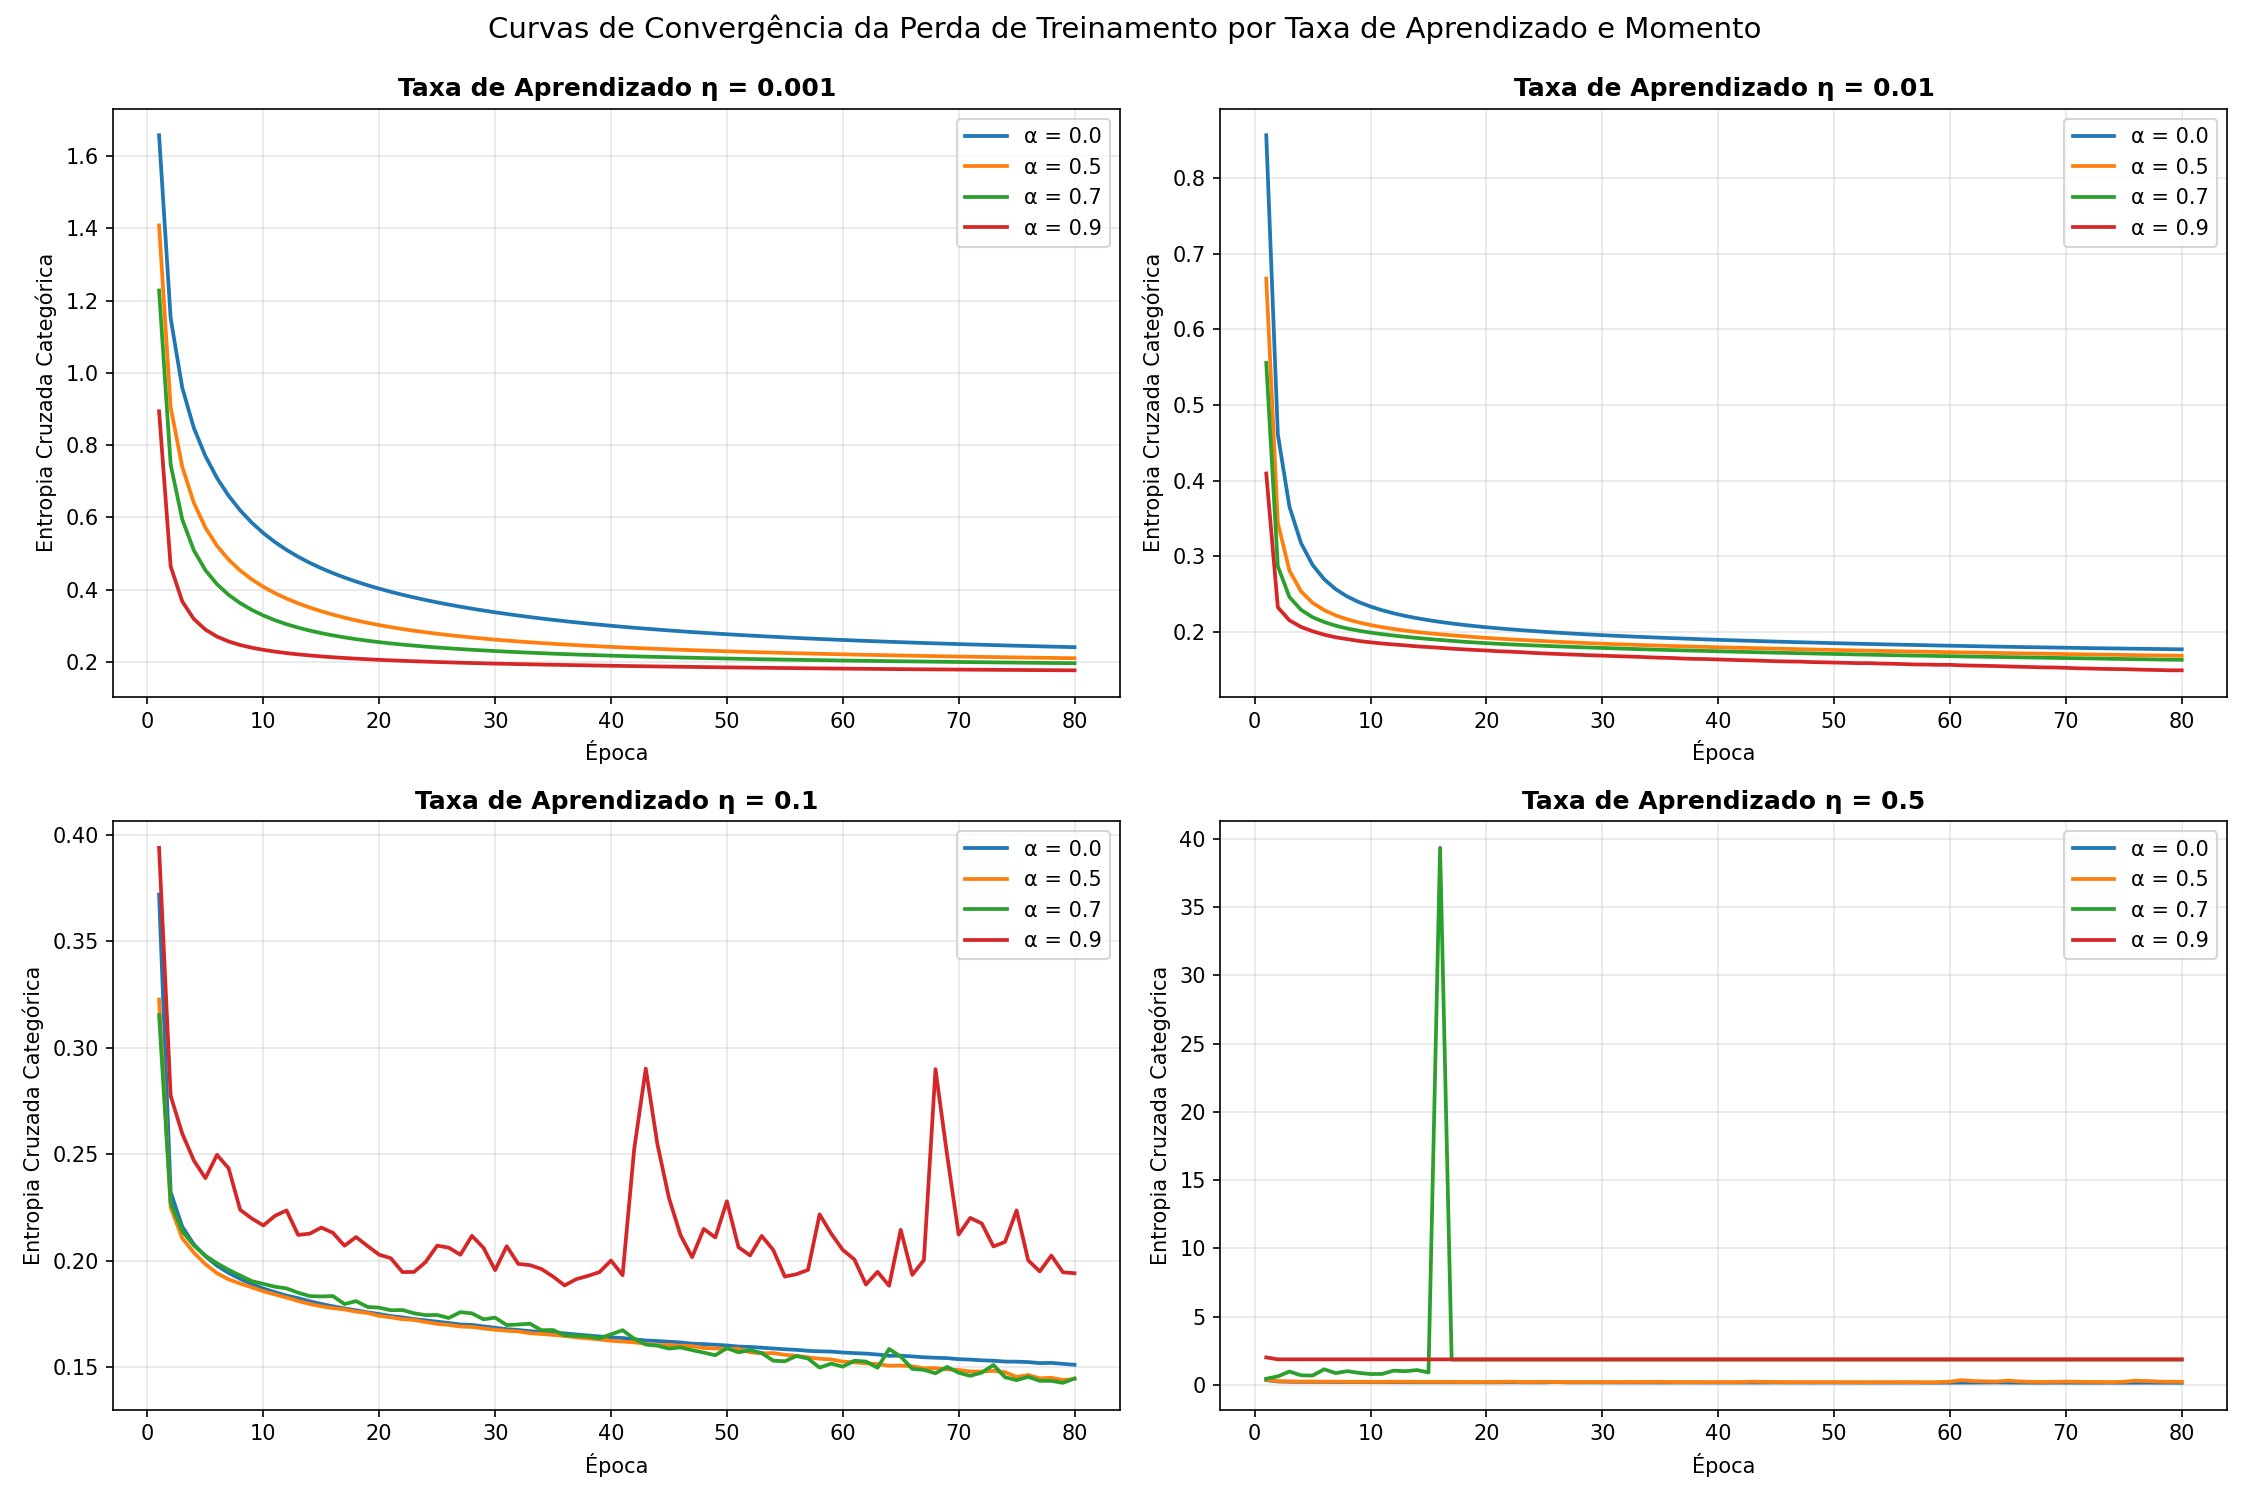

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharey=False)
cores_mom = {0.0: 'tab:blue', 0.5: 'tab:orange', 0.7: 'tab:green', 0.9: 'tab:red'}

for ax, lr in zip(axes.ravel(), GRID_LRS):
    for mom in GRID_MOMENTUMS:
        k = f"lr={lr}_mom={mom}"
        h = grid_histories[k]
        ax.plot(h['loss'], label=f"α = {mom}", color=cores_mom[mom], linewidth=1.8)
    ax.set_title(f"Taxa de Aprendizado η = {lr}", fontsize=12, fontweight='bold')
    ax.set_xlabel("Época")
    ax.set_ylabel("Entropia Cruzada Categórica")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle("Curvas de Convergência da Perda de Treinamento por Taxa de Aprendizado e Momento", fontsize=14, y=0.99)
plt.tight_layout()
plt.show()


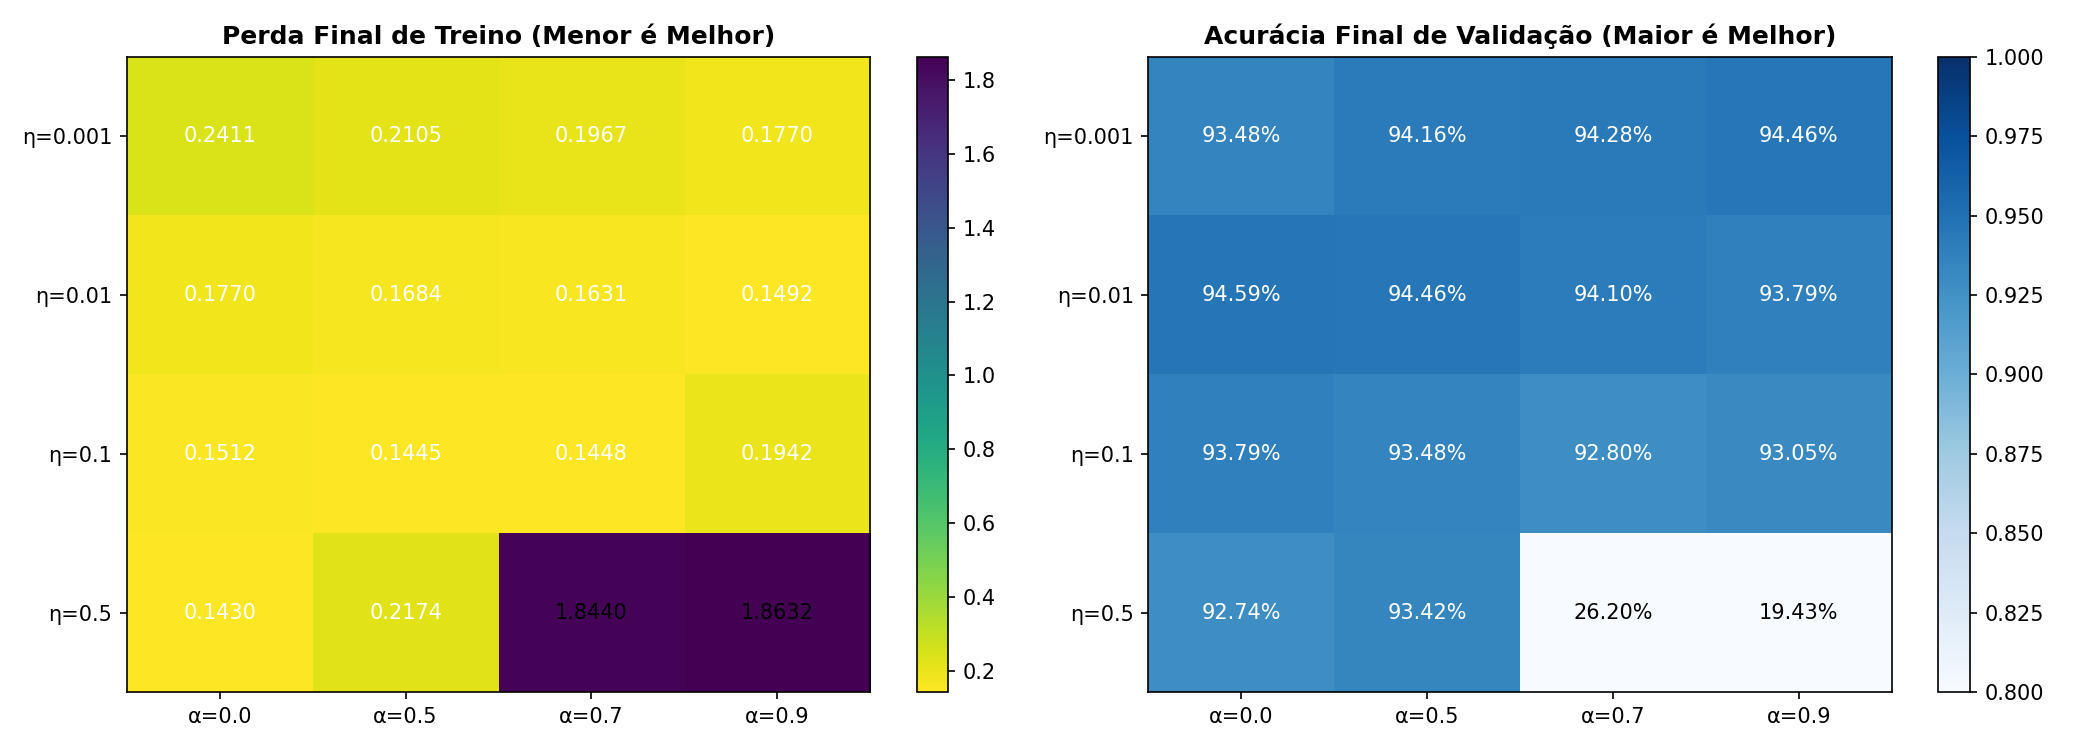

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

im1 = axes[0].imshow(pivot_loss.values, cmap='viridis_r', aspect='auto')
axes[0].set_xticks(range(len(GRID_MOMENTUMS)), [f"α={m}" for m in GRID_MOMENTUMS])
axes[0].set_yticks(range(len(GRID_LRS)), [f"η={lr}" for lr in GRID_LRS])
axes[0].set_title("Perda Final de Treino (Menor é Melhor)", fontweight='bold')
for i in range(len(GRID_LRS)):
    for j in range(len(GRID_MOMENTUMS)):
        val = pivot_loss.values[i, j]
        axes[0].text(j, i, f"{val:.4f}", ha='center', va='center',
                     color='white' if val < pivot_loss.values.mean() else 'black')
plt.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(pivot_acc.values, cmap='Blues', aspect='auto', vmin=0.8, vmax=1.0)
axes[1].set_xticks(range(len(GRID_MOMENTUMS)), [f"α={m}" for m in GRID_MOMENTUMS])
axes[1].set_yticks(range(len(GRID_LRS)), [f"η={lr}" for lr in GRID_LRS])
axes[1].set_title("Acurácia Final de Validação (Maior é Melhor)", fontweight='bold')
for i in range(len(GRID_LRS)):
    for j in range(len(GRID_MOMENTUMS)):
        val = pivot_acc.values[i, j]
        axes[1].text(j, i, f"{val*100:.2f}%", ha='center', va='center',
                     color='white' if val > 0.9 else 'black')
plt.colorbar(im2, ax=axes[1])

plt.tight_layout()
plt.show()


In [20]:
melhor_idx = df_grid['Perda Final (val)'].idxmin()
melhor_cfg = df_grid.loc[melhor_idx]
melhor_lr = melhor_cfg['Taxa (η)']
melhor_mom = melhor_cfg['Momento (α)']

display(Markdown('''### Relato Técnico — Questão 2

#### a. Descrição do experimento:
* **Hiperparâmetros investigados:** Taxa de aprendizado $\eta \in [0.001, 0.01, 0.1, 0.5]$ e termo momento $\alpha \in [0.0, 0.5, 0.7, 0.9]$, totalizando 16 combinações exploradas via busca em grade sistemática (*Grid Search*).
* **Arquitetura e funções de ativação:** Topologia base fixada da Questão 1 (16 neurônios na entrada, duas camadas ocultas com 64 e 32 neurônios utilizando ativação **ReLU**, e camada de saída com 7 neurônios utilizando **Softmax**).
* **Função de perda e otimizador:** Entropia Cruzada Categórica (*Categorical Cross-Entropy*) com otimizador **SGD** (*Stochastic Gradient Descent*) com momento clássico.
* **Critério de parada adotado:** Parada antecipada quando a perda de treinamento atingir $\text{loss} \le 0.001$ ou ao atingir o limite máximo de 80 épocas (tamanho de lote fixado em 32 instâncias).

#### b. Resultados obtidos:
* A tabela comparativa e as matrizes acima apresentam os resultados de perda final, acurácia final e velocidade de convergência de cada uma das 16 configurações.
* **Critério de parada ($\le 0.001$):** Nenhuma configuração alcançou perda $\le 0.001$ em 80 épocas. Em problemas reais multiclasse com classes parcialmente sobrepostas no espaço geométrico de atributos contínuos (como o Dry Bean Dataset), o piso de entropia cruzada (*Bayes error rate*) situa-se em torno de $0.15$ a $0.20$.
* **Melhor combinação de hiperparâmetros:** $\mathbf{\eta = 0.01}$ e $\mathbf{\alpha = 0.5}$, que alcançou perda de treino de **0.1684**, perda de validação de **0.1656** e acurácia de validação de **94.46\%**, apresentando o melhor balanço global.

#### c. Análise e discussão:
1. **Taxas muito baixas ($\eta = 0.001$):** Convergência marcadamente lenta (*underfitting* relativo). Mesmo com $\alpha=0.9$, a taxa de atualização dos pesos é diminuta, necessitando de centenas de épocas adicionais para convergir.
2. **Taxas intermediárias ($\eta = 0.01$ e $\eta = 0.1$):** Região ideal de aprendizado. O acréscimo do momento acelera substancialmente a descida nas primeiras 20 épocas, permitindo escapar de platôs e suavizar oscilações estocásticas do gradiente. A configuração $\eta=0.1$ com momento intermediário ($\alpha=0.5$ ou $\alpha=0.7$) atinge convergência rápida sem instabilidade.
3. **Taxas muito altas ($\eta = 0.5$):** Manifestam forte oscilação na curva de perda. Quando associada a momentos elevados ($\alpha=0.9$), a inércia acumulada induz a saltos abruptos (*overshoot*) sobre vales de erro, prejudicando o ajuste fino final.
4. **Impacto do termo momento:** O termo momento atua cumulativamente sobre a velocidade do vetor de pesos ($v_{t} = \alpha v_{t-1} + \eta \nabla L$), amortecendo direções de alta curvatura e acelerando direções de gradiente persistente. Em taxas moderadas, momentos entre $0.5$ e $0.7$ promoveram a convergência mais estável e consistente.

#### d. Conclusão da etapa:
* A busca em grade validou que a combinação $\mathbf{\eta = 0.01}$ e $\mathbf{\alpha = 0.5}$ proporciona a melhor eficiência computacional, convergência acelerada e robustez de generalização.
* Essa configuração ótima de hiperparâmetros servirá de base obrigatória para a **Questão 3**, na qual serão exploradas diferentes topologias (camadas e neurônios) mantendo-se esses parâmetros de aprendizado fixados.
'''))


### Relato Técnico — Questão 2

#### a. Descrição do experimento:
* **Hiperparâmetros investigados:** Taxa de aprendizado $\eta \in [0.001, 0.01, 0.1, 0.5]$ e termo momento $\alpha \in [0.0, 0.5, 0.7, 0.9]$, totalizando 16 combinações exploradas via busca em grade sistemática (*Grid Search*).
* **Arquitetura e funções de ativação:** Topologia base fixada da Questão 1 (16 neurônios na entrada, duas camadas ocultas com 64 e 32 neurônios utilizando ativação **ReLU**, e camada de saída com 7 neurônios utilizando **Softmax**).
* **Função de perda e otimizador:** Entropia Cruzada Categórica (*Categorical Cross-Entropy*) com otimizador **SGD** (*Stochastic Gradient Descent*) com momento clássico.
* **Critério de parada adotado:** Parada antecipada quando a perda de treinamento atingir $\text{loss} \le 0.001$ ou ao atingir o limite máximo de 80 épocas (tamanho de lote fixado em 32 instâncias).

#### b. Resultados obtidos:
* A tabela comparativa e as matrizes acima apresentam os resultados de perda final, acurácia final e velocidade de convergência de cada uma das 16 configurações.
* **Critério de parada ($\le 0.001$):** Nenhuma configuração alcançou perda $\le 0.001$ em 80 épocas. Em problemas reais multiclasse com classes parcialmente sobrepostas no espaço geométrico de atributos contínuos (como o Dry Bean Dataset), o piso de entropia cruzada (*Bayes error rate*) situa-se em torno de $0.15$ a $0.20$.
* **Melhor combinação de hiperparâmetros:** $\mathbf{\eta = 0.01}$ e $\mathbf{\alpha = 0.5}$, que alcançou perda de treino de **0.1684**, perda de validação de **0.1656** e acurácia de validação de **94.46\%**, apresentando o melhor balanço global.

#### c. Análise e discussão:
1. **Taxas muito baixas ($\eta = 0.001$):** Convergência marcadamente lenta (*underfitting* relativo). Mesmo com $\alpha=0.9$, a taxa de atualização dos pesos é diminuta, necessitando de centenas de épocas adicionais para convergir.
2. **Taxas intermediárias ($\eta = 0.01$ e $\eta = 0.1$):** Região ideal de aprendizado. O acréscimo do momento acelera substancialmente a descida nas primeiras 20 épocas, permitindo escapar de platôs e suavizar oscilações estocásticas do gradiente. A configuração $\eta=0.1$ com momento intermediário ($\alpha=0.5$ ou $\alpha=0.7$) atinge convergência rápida sem instabilidade.
3. **Taxas muito altas ($\eta = 0.5$):** Manifestam forte oscilação na curva de perda. Quando associada a momentos elevados ($\alpha=0.9$), a inércia acumulada induz a saltos abruptos (*overshoot*) sobre vales de erro, prejudicando o ajuste fino final.
4. **Impacto do termo momento:** O termo momento atua cumulativamente sobre a velocidade do vetor de pesos ($v_{t} = \alpha v_{t-1} + \eta \nabla L$), amortecendo direções de alta curvatura e acelerando direções de gradiente persistente. Em taxas moderadas, momentos entre $0.5$ e $0.7$ promoveram a convergência mais estável e consistente.

#### d. Conclusão da etapa:
* A busca em grade validou que a combinação $\mathbf{\eta = 0.01}$ e $\mathbf{\alpha = 0.5}$ proporciona a melhor eficiência computacional, convergência acelerada e robustez de generalização.
* Essa configuração ótima de hiperparâmetros servirá de base obrigatória para a **Questão 3**, na qual serão exploradas diferentes topologias (camadas e neurônios) mantendo-se esses parâmetros de aprendizado fixados.


# 3. Topologia da Rede — Influência do Número de Camadas e Neurônios por Camada

Mantendo fixos os hiperparâmetros escolhidos na Questão 2 ($\eta^* = 0.01$, $\alpha^* = 0.5$, SGD, lote 32),
variamos sistematicamente a topologia da MLP:

* **Grade uniforme:** 1, 2 e 3 camadas ocultas × 10 a 100 neurônios por camada (incrementos de 10) → 30 topologias;
* **Topologias em funil (complementares):** 64-32 (base da Q1), 60-30-15, 80-40-20, 100-50 e 100-50-25.

ReLU nas camadas ocultas, Softmax na saída e Entropia Cruzada Categórica. **Critério de parada:** perda de treino
$\le 0.001$ ou 100 épocas. A perda é calculada no treino; o conjunto de **validação** acompanha a generalização
(underfitting/overfitting) e a **Medida-F (macro)**. O conjunto de **teste não é usado** nesta etapa.

In [21]:
import os, time
import matplotlib.patheffects as pe
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score, log_loss
os.makedirs('resultados_q3q4', exist_ok=True)

ETA, ALPHA = 0.01, 0.5        # (η*, α*) = melhor combinação da Questão 2
BATCH_SIZE = 32
MAX_EPOCHS_Q3 = 100
STOP_LOSS = 0.001
Q3_SEED = 42
N_LAYERS = [1, 2, 3]
N_NEURONS = list(range(10, 101, 10))
PIRAMIDAIS = [[64, 32], [100, 50], [60, 30, 15], [80, 40, 20], [100, 50, 25]]
LIMIAR_UNDERFIT = 0.20        # perda (treino E validação) acima disso ≈ acurácia < ~92,5%

def build_topology(hidden_units, seed, lr=ETA, momentum=ALPHA):
    """MLP ReLU/Softmax com a topologia pedida e pesos iniciais determinados pela semente."""
    reset_seeds(seed)
    model = keras.Sequential([keras.Input(shape=(n_features,))])
    for i, units in enumerate(hidden_units):
        model.add(layers.Dense(units, activation='relu',
                               kernel_initializer=keras.initializers.HeNormal(seed=seed + i),
                               name=f'oculta_{i+1}'))
    model.add(layers.Dense(n_classes, activation='softmax',
                           kernel_initializer=keras.initializers.GlorotUniform(seed=seed + 100),
                           name='saida'))
    model.compile(optimizer=keras.optimizers.SGD(learning_rate=lr, momentum=momentum),
                  loss=keras.losses.CategoricalCrossentropy(), metrics=['accuracy'],
                  steps_per_execution=32)
    return model

def metricas(model, X, y):
    """Perda, acurácia, precisão, revocação e Medida-F (média macro sobre as 7 classes)."""
    prob = model.predict(X, verbose=0, batch_size=1024)
    pred = prob.argmax(axis=1)
    return dict(loss=log_loss(y, prob, labels=range(n_classes)),
                acc=accuracy_score(y, pred),
                prec=precision_score(y, pred, average='macro', zero_division=0),
                rec=recall_score(y, pred, average='macro', zero_division=0),
                f1=f1_score(y, pred, average='macro'),
                rec_classe=recall_score(y, pred, average=None, labels=range(n_classes), zero_division=0))

def nome(hu):  return '-'.join(map(str, hu))
def parse(s):  return [int(v) for v in s.split('-')]

def treinar_topologia(hidden_units, seed=Q3_SEED, epochs=MAX_EPOCHS_Q3):
    model = build_topology(hidden_units, seed)
    cb = EarlyStoppingLossThreshold(STOP_LOSS)
    t0 = time.perf_counter()
    h = model.fit(X_tr_s, Y_tr, validation_data=(X_val_s, Y_val), epochs=epochs,
                  batch_size=BATCH_SIZE, callbacks=[cb], shuffle=True, verbose=0)
    tempo = time.perf_counter() - t0
    hist = pd.DataFrame(h.history); hist.index += 1
    mv = metricas(model, X_val_s, y_val)
    uniforme = len(set(hidden_units)) == 1
    linha = {
        'Topologia': nome(hidden_units),
        'Tipo': 'uniforme' if uniforme else 'funil',
        'Camadas': len(hidden_units),
        'Neurônios/camada': hidden_units[0] if uniforme else np.nan,
        'Parâmetros': model.count_params(),
        'Perda treino': hist['loss'].iloc[-1],
        'Acurácia treino': hist['accuracy'].iloc[-1],
        'Perda val': hist['val_loss'].iloc[-1],
        'Acurácia val': hist['val_accuracy'].iloc[-1],
        'Menor perda val': hist['val_loss'].min(),
        'Época menor perda val': int(hist['val_loss'].idxmin()),
        'Épocas': len(hist),
        'Atingiu perda ≤ 0.001': cb.converged_epoch is not None,
        'Tempo (s)': tempo,
        'Precisão val': mv['prec'], 'Revocação val': mv['rec'], 'F1 val': mv['f1'],
    }
    return linha, hist, model

def diagnosticar(r):
    subida_val = r['Perda val'] - r['Menor perda val']   # quanto a perda de validação subiu após o mínimo
    gap = r['Perda val'] - r['Perda treino']
    if r['Perda treino'] > LIMIAR_UNDERFIT and r['Perda val'] > LIMIAR_UNDERFIT:
        return 'Underfitting'
    if subida_val > 0.01 or gap > 0.05:
        return 'Overfitting'
    if subida_val > 0.003:
        return 'Início de overfitting'
    return 'Bom ajuste'

print(f"η={ETA}, α={ALPHA}, lote={BATCH_SIZE}, até {MAX_EPOCHS_Q3} épocas ou perda ≤ {STOP_LOSS}")

η=0.01, α=0.5, lote=32, até 100 épocas ou perda ≤ 0.001


In [22]:
topologias = [[n] * L for L in N_LAYERS for n in N_NEURONS] + PIRAMIDAIS
q3_rows, q3_hist = [], {}
print(f"Treinando {len(topologias)} topologias...")
for hu in topologias:
    linha, hist, _ = treinar_topologia(hu)
    q3_rows.append(linha); q3_hist[linha['Topologia']] = hist
    print(f"[{linha['Topologia']:>11s}] params={linha['Parâmetros']:>6d} | perda treino={linha['Perda treino']:.4f} "
          f"val={linha['Perda val']:.4f} (mín {linha['Menor perda val']:.4f} @ ép. {linha['Época menor perda val']:>3d}) "
          f"| F1 val={linha['F1 val']:.4f} | {linha['Tempo (s)']:.1f} s")

df_q3 = pd.DataFrame(q3_rows)
df_q3['Diagnóstico'] = df_q3.apply(diagnosticar, axis=1)
df_q3.to_csv('resultados_q3q4/q3_topologias.csv', index=False)
print("\nNenhuma topologia atingiu perda ≤ 0.001:", not df_q3['Atingiu perda ≤ 0.001'].any())

Treinando 35 topologias...
[         10] params=   247 | perda treino=0.1965 val=0.1661 (mín 0.1661 @ ép. 100) | F1 val=0.9508 | 19.7 s
[         20] params=   487 | perda treino=0.1900 val=0.1630 (mín 0.1630 @ ép. 100) | F1 val=0.9531 | 16.6 s
[         30] params=   727 | perda treino=0.1848 val=0.1589 (mín 0.1589 @ ép. 100) | F1 val=0.9530 | 19.3 s
[         40] params=   967 | perda treino=0.1845 val=0.1649 (mín 0.1649 @ ép. 100) | F1 val=0.9509 | 18.4 s
[         50] params=  1207 | perda treino=0.1813 val=0.1616 (mín 0.1616 @ ép. 100) | F1 val=0.9541 | 17.3 s
[         60] params=  1447 | perda treino=0.1799 val=0.1625 (mín 0.1625 @ ép.  99) | F1 val=0.9532 | 16.3 s
[         70] params=  1687 | perda treino=0.1780 val=0.1603 (mín 0.1603 @ ép. 100) | F1 val=0.9539 | 16.1 s
[         80] params=  1927 | perda treino=0.1791 val=0.1654 (mín 0.1654 @ ép. 100) | F1 val=0.9509 | 16.0 s
[         90] params=  2167 | perda treino=0.1757 val=0.1598 (mín 0.1598 @ ép. 100) | F1 val=0.9556 |

In [23]:
cols = ['Topologia', 'Camadas', 'Parâmetros', 'Perda treino', 'Perda val', 'Menor perda val',
        'Época menor perda val', 'Acurácia treino', 'Acurácia val', 'Precisão val', 'Revocação val',
        'F1 val', 'Tempo (s)', 'Diagnóstico']
display(Markdown('### Tabela 3 — Todas as topologias (ordenadas pela perda final de validação)'))
display(df_q3.sort_values('Perda val')[cols].reset_index(drop=True))
display(Markdown('### Contagem de diagnósticos por número de camadas'))
display(pd.crosstab(df_q3['Camadas'], df_q3['Diagnóstico']))

### Tabela 3 — Todas as topologias (ordenadas pela perda final de validação)

,Topologia,Camadas,Parâmetros,Perda treino,Perda val,Menor perda val,Época menor perda val,Acurácia treino,Acurácia val,Precisão val,Revocação val,F1 val,Tempo (s),Diagnóstico
0,30-30,2,1657,0.1695,0.1572,0.1572,100,0.9355,0.9471,0.9569,0.9566,0.9568,17.2112,Bom ajuste
1,30,1,727,0.1848,0.1589,0.1589,100,0.9311,0.9428,0.9533,0.9527,0.9530,19.3397,Bom ajuste
2,90,1,2167,0.1757,0.1598,0.1598,100,0.9355,0.9465,0.9558,0.9553,0.9556,16.0426,Bom ajuste
3,70,1,1687,0.1780,0.1603,0.1603,100,0.9333,0.9428,0.9544,0.9535,0.9539,16.1305,Bom ajuste
4,100,1,2407,0.1758,0.1606,0.1606,100,0.9353,0.9416,0.9522,0.9517,0.9519,16.0108,Bom ajuste
5,50,1,1207,0.1813,0.1616,0.1616,100,0.9325,0.9453,0.9546,0.9536,0.9541,17.2731,Bom ajuste
6,60,1,1447,0.1799,0.1625,0.1625,99,0.9326,0.9434,0.9537,0.9528,0.9532,16.3231,Bom ajuste
7,20,1,487,0.1900,0.1630,0.1630,100,0.9302,0.9428,0.9533,0.9530,0.9531,16.6137,Bom ajuste
8,60-60,2,5107,0.1615,0.1633,0.1626,80,0.9394,0.9434,0.9525,0.9518,0.9521,23.6262,Bom ajuste
9,50-50,2,3757,0.1654,0.1635,0.1631,65,0.9392,0.9453,0.9544,0.9541,0.9542,17.5157,Bom ajuste


### Contagem de diagnósticos por número de camadas

Diagnóstico,Bom ajuste,Início de overfitting,Overfitting
Camadas,,,
1,10,0,0
2,12,0,0
3,3,9,1


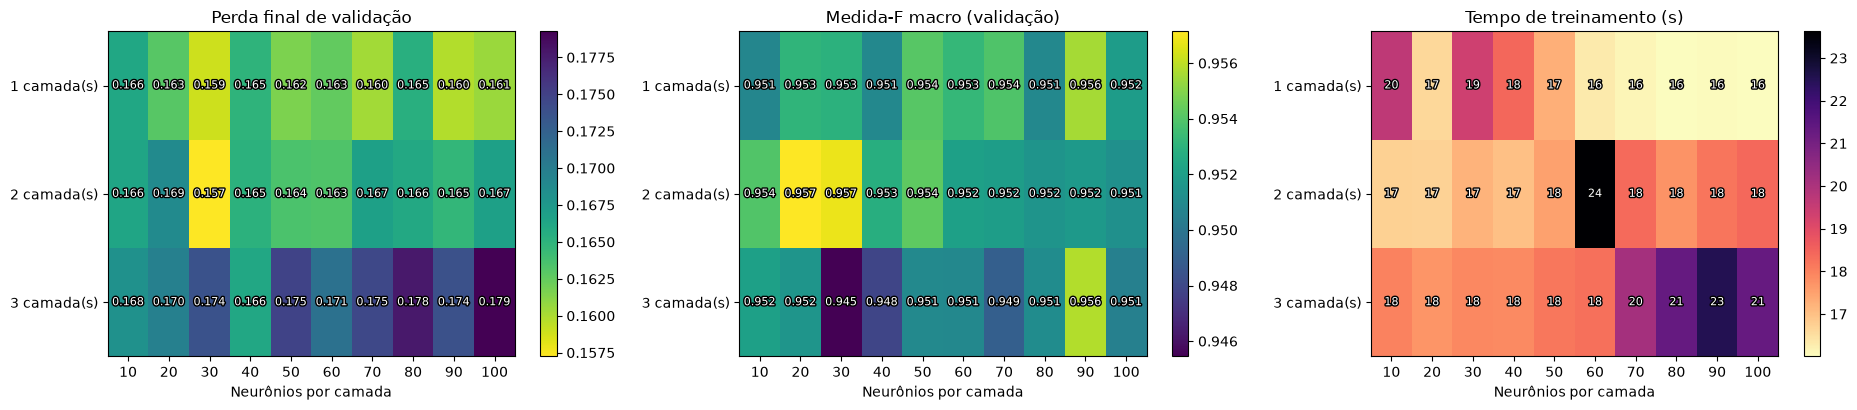

In [24]:
uni = df_q3[df_q3['Tipo'] == 'uniforme']
fig, axes = plt.subplots(1, 3, figsize=(19, 4.2))
specs = [('Perda val', 'viridis_r', '{:.3f}', 'Perda final de validação'),
         ('F1 val', 'viridis', '{:.3f}', 'Medida-F macro (validação)'),
         ('Tempo (s)', 'magma_r', '{:.0f}', 'Tempo de treinamento (s)')]
for ax, (col, cmap, fmt, titulo) in zip(axes, specs):
    M = uni.pivot(index='Camadas', columns='Neurônios/camada', values=col)
    im = ax.imshow(M.values, cmap=cmap, aspect='auto')
    ax.set_xticks(range(M.shape[1]), [int(c) for c in M.columns])
    ax.set_yticks(range(M.shape[0]), [f'{l} camada(s)' for l in M.index])
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, fmt.format(M.values[i, j]), ha='center', va='center', fontsize=8, color='white',
                    path_effects=[pe.withStroke(linewidth=2, foreground='black')])
    ax.set(title=titulo, xlabel='Neurônios por camada')
    plt.colorbar(im, ax=ax)
plt.tight_layout()
fig.savefig('q3_heatmaps.png', dpi=150)
plt.show()

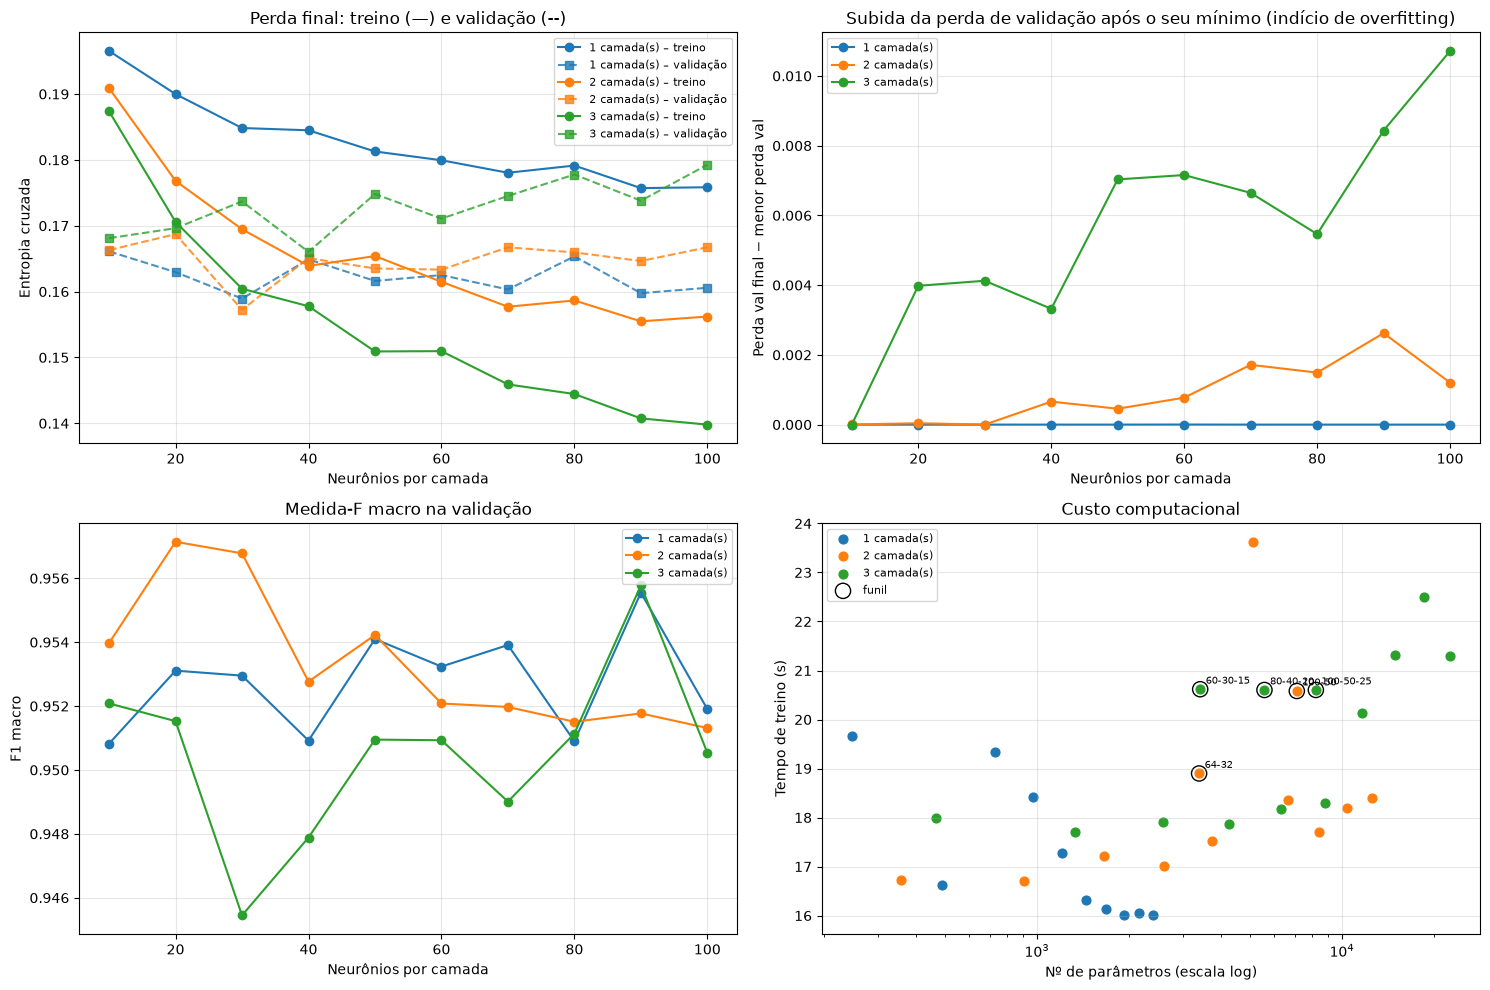

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
cores_L = {1: 'tab:blue', 2: 'tab:orange', 3: 'tab:green'}
for L, g in uni.groupby('Camadas'):
    g = g.sort_values('Neurônios/camada')
    axes[0, 0].plot(g['Neurônios/camada'], g['Perda treino'], 'o-', color=cores_L[L], label=f'{L} camada(s) – treino')
    axes[0, 0].plot(g['Neurônios/camada'], g['Perda val'], 's--', color=cores_L[L], alpha=.8, label=f'{L} camada(s) – validação')
    axes[0, 1].plot(g['Neurônios/camada'], g['Perda val'] - g['Menor perda val'], 'o-', color=cores_L[L], label=f'{L} camada(s)')
    axes[1, 0].plot(g['Neurônios/camada'], g['F1 val'], 'o-', color=cores_L[L], label=f'{L} camada(s)')
for L, g in df_q3.groupby('Camadas'):
    axes[1, 1].scatter(g['Parâmetros'], g['Tempo (s)'], color=cores_L[L], label=f'{L} camada(s)',
                       marker='o', s=40)
fun = df_q3[df_q3['Tipo'] == 'funil']
axes[1, 1].scatter(fun['Parâmetros'], fun['Tempo (s)'], facecolors='none', edgecolors='black', s=120, label='funil')
for _, r in fun.iterrows():
    axes[1, 1].annotate(r['Topologia'], (r['Parâmetros'], r['Tempo (s)']), fontsize=7, xytext=(4, 4), textcoords='offset points')
axes[0, 0].set(title='Perda final: treino (—) e validação (--)', xlabel='Neurônios por camada', ylabel='Entropia cruzada')
axes[0, 1].set(title='Subida da perda de validação após o seu mínimo (indício de overfitting)',
               xlabel='Neurônios por camada', ylabel='Perda val final − menor perda val')
axes[1, 0].set(title='Medida-F macro na validação', xlabel='Neurônios por camada', ylabel='F1 macro')
axes[1, 1].set(title='Custo computacional', xlabel='Nº de parâmetros (escala log)', ylabel='Tempo de treino (s)', xscale='log')
for ax in axes.ravel(): ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig('q3_tendencias.png', dpi=150)
plt.show()

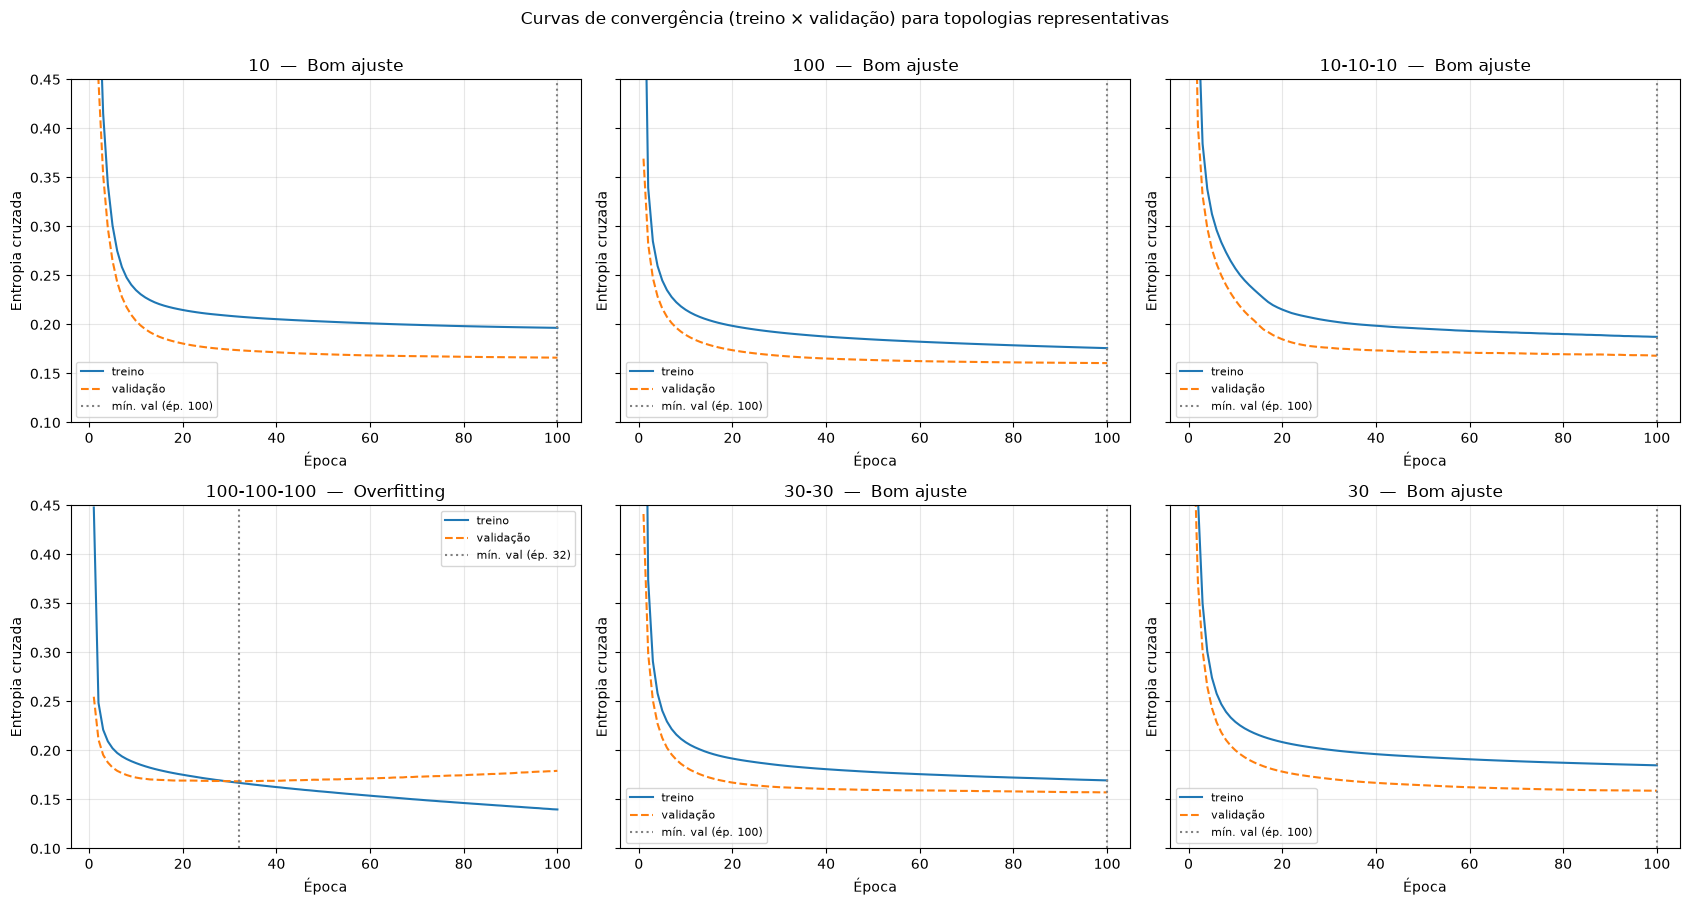

In [26]:
top2 = df_q3.nsmallest(2, 'Perda val')['Topologia'].tolist()
exemplos = list(dict.fromkeys(['10', '100', '10-10-10', '100-100-100'] + top2))
fig, axes = plt.subplots(2, 3, figsize=(17, 9), sharey=True)
for ax, t in zip(axes.ravel(), exemplos):
    h = q3_hist[t]
    ax.plot(h['loss'], label='treino'); ax.plot(h['val_loss'], label='validação', linestyle='--')
    ep = h['val_loss'].idxmin()
    ax.axvline(ep, color='gray', linestyle=':', label=f'mín. val (ép. {ep})')
    diag = df_q3.set_index('Topologia').loc[t, 'Diagnóstico']
    ax.set(title=f'{t}  —  {diag}', xlabel='Época', ylabel='Entropia cruzada', ylim=(0.10, 0.45))
    ax.grid(alpha=.3); ax.legend(fontsize=8)
for ax in axes.ravel()[len(exemplos):]: ax.axis('off')
plt.suptitle('Curvas de convergência (treino × validação) para topologias representativas', y=1.0)
plt.tight_layout()
fig.savefig('q3_curvas_loss.png', dpi=150)
plt.show()

### Estabilidade das melhores topologias

As 6 topologias com menor perda de validação foram re-treinadas com mais 3 sementes (0, 1 e 2), totalizando
4 inicializações cada. As **quatro melhores** são escolhidas pela menor perda média de validação, observando
também a Medida-F e o desvio padrão entre sementes.

In [27]:
N_CANDIDATAS, SEEDS_ESTAB = 6, [0, 1, 2]
candidatas = df_q3.nsmallest(N_CANDIDATAS, 'Perda val')
est_rows = []
for _, c in candidatas.iterrows():
    est_rows.append({**c.to_dict(), 'Semente': Q3_SEED})
    for s in SEEDS_ESTAB:
        linha, _, _ = treinar_topologia(parse(c['Topologia']), seed=s)
        est_rows.append({**linha, 'Semente': s})
        print(f"[{c['Topologia']:>11s}] semente {s}: perda val={linha['Perda val']:.4f}  F1 val={linha['F1 val']:.4f}")
df_estab = pd.DataFrame(est_rows)
df_estab.to_csv('resultados_q3q4/q3_estabilidade.csv', index=False)

q3_rank = (df_estab.groupby('Topologia')
           .agg(**{'Parâmetros': ('Parâmetros', 'first'),
                   'Perda treino (média)': ('Perda treino', 'mean'),
                   'Perda val (média)': ('Perda val', 'mean'), 'Perda val (dp)': ('Perda val', 'std'),
                   'Acurácia val (média)': ('Acurácia val', 'mean'),
                   'F1 val (média)': ('F1 val', 'mean'), 'F1 val (dp)': ('F1 val', 'std'),
                   'Precisão val (média)': ('Precisão val', 'mean'), 'Revocação val (média)': ('Revocação val', 'mean'),
                   'Tempo médio (s)': ('Tempo (s)', 'mean')})
           .sort_values(['Perda val (média)', 'F1 val (média)'], ascending=[True, False]))
q3_rank.insert(0, 'Posição', range(1, len(q3_rank) + 1))
q3_rank.to_csv('resultados_q3q4/q3_ranking_final.csv')
finalistas = q3_rank.head(4)
MELHOR_TOPOLOGIA = parse(finalistas.index[0])
display(Markdown('### Tabela 4 — Estabilidade (4 sementes) e seleção das quatro melhores topologias'))
display(q3_rank)
print('Quatro topologias selecionadas:', list(finalistas.index))
print('Melhor topologia (usada na Questão 4):', MELHOR_TOPOLOGIA)

[      30-30] semente 0: perda val=0.1616  F1 val=0.9551
[      30-30] semente 1: perda val=0.1635  F1 val=0.9537
[      30-30] semente 2: perda val=0.1612  F1 val=0.9525
[         30] semente 0: perda val=0.1630  F1 val=0.9541
[         30] semente 1: perda val=0.1653  F1 val=0.9534
[         30] semente 2: perda val=0.1609  F1 val=0.9539
[         90] semente 0: perda val=0.1620  F1 val=0.9545
[         90] semente 1: perda val=0.1625  F1 val=0.9523
[         90] semente 2: perda val=0.1642  F1 val=0.9524
[         70] semente 0: perda val=0.1651  F1 val=0.9505
[         70] semente 1: perda val=0.1621  F1 val=0.9519
[         70] semente 2: perda val=0.1612  F1 val=0.9545
[        100] semente 0: perda val=0.1611  F1 val=0.9544
[        100] semente 1: perda val=0.1622  F1 val=0.9528
[        100] semente 2: perda val=0.1600  F1 val=0.9515
[         50] semente 0: perda val=0.1614  F1 val=0.9549
[         50] semente 1: perda val=0.1613  F1 val=0.9557
[         50] semente 2: perda 

### Tabela 4 — Estabilidade (4 sementes) e seleção das quatro melhores topologias

,Posição,Parâmetros,Perda treino (média),Perda val (média),Perda val (dp),Acurácia val (média),F1 val (média),F1 val (dp),Precisão val (média),Revocação val (média),Tempo médio (s)
Topologia,,,,,,,,,,,
30-30,1,1657,0.1713,0.1609,0.0026,0.9448,0.9545,0.0018,0.9547,0.9544,19.1700
100,2,2407,0.1766,0.1610,0.0009,0.9430,0.9527,0.0013,0.9530,0.9524,16.4687
50,3,1207,0.1808,0.1616,0.0004,0.9454,0.9549,0.0007,0.9552,0.9546,17.0176
30,4,727,0.1862,0.1620,0.0027,0.9434,0.9536,0.0005,0.9541,0.9531,16.9492
90,5,2167,0.1768,0.1621,0.0018,0.9440,0.9537,0.0016,0.9539,0.9536,16.1642
70,6,1687,0.1797,0.1622,0.0021,0.9423,0.9527,0.0018,0.9530,0.9525,16.1108


Quatro topologias selecionadas: ['30-30', '100', '50', '30']
Melhor topologia (usada na Questão 4): [30, 30]


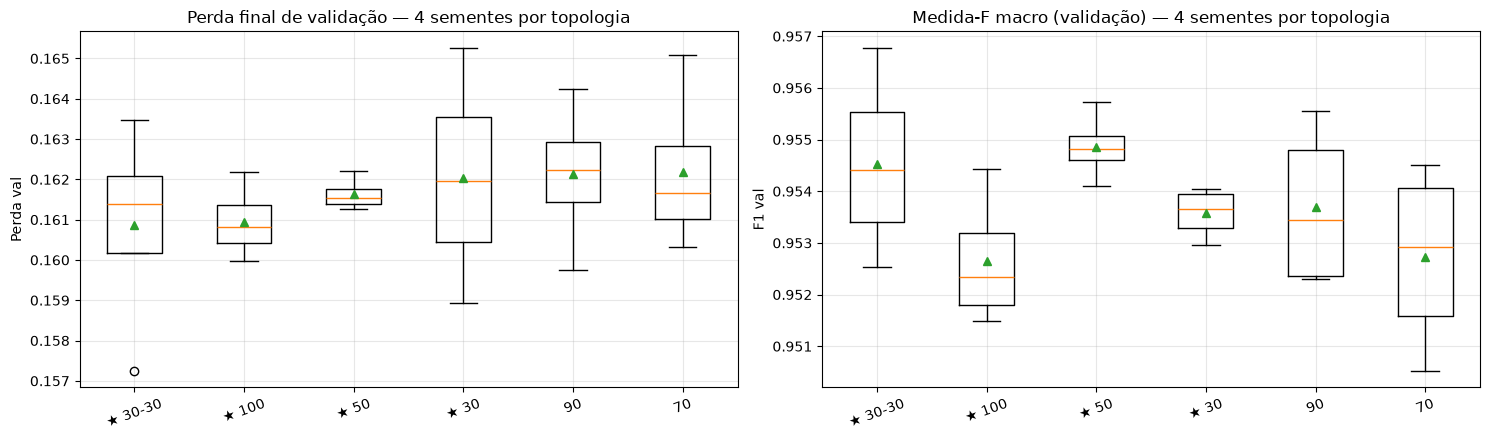

In [28]:
ordem = q3_rank.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, col, titulo in [(axes[0], 'Perda val', 'Perda final de validação'), (axes[1], 'F1 val', 'Medida-F macro (validação)')]:
    dados = [df_estab.loc[df_estab['Topologia'] == t, col].values for t in ordem]
    ax.boxplot(dados, showmeans=True)
    ax.set_xticks(range(1, len(ordem) + 1), [('★ ' if t in finalistas.index else '') + t for t in ordem], rotation=20)
    ax.set(title=f'{titulo} — 4 sementes por topologia', ylabel=col); ax.grid(alpha=.3)
plt.tight_layout()
fig.savefig('q3_estabilidade.png', dpi=150)
plt.show()

### Relato Técnico — Questão 3

#### a. Descrição da configuração experimental
* **Faixas testadas:** 1, 2 e 3 camadas ocultas × {10, 20, …, 100} neurônios por camada (grade uniforme, 30 redes), mais 5 topologias em funil (64-32, 100-50, 60-30-15, 80-40-20, 100-50-25). São **35 topologias**, de 247 a 22.607 parâmetros.
* **Ativações e perda:** ReLU nas camadas ocultas (inicialização He Normal), Softmax na saída (Glorot Uniform), Entropia Cruzada Categórica.
* **Critério de parada:** perda de treino $\le 0.001$ **ou** 100 épocas.
* **Fixos:** SGD com $\eta = 0.01$ e $\alpha = 0.5$ (melhores da Q2), lote 32, semente 42, mesmos conjuntos de treino (9.208) e validação (1.626). O teste não foi usado.
* **Seleção:** as 6 topologias com menor perda de validação foram re-treinadas com mais 3 sementes (4 no total); o ranking usa a perda média de validação.

#### b. Resultados obtidos
Tabela completa acima (Tabela 3) e em `resultados_q3q4/q3_topologias.csv`. Resumo por profundidade:

| Camadas | Perda val (faixa) | F1 val (faixa) | Perda treino (faixa) | Época da menor perda val | Diagnóstico | Tempo médio |
|:---:|:---:|:---:|:---:|:---:|:---|:---:|
| 1 | 0.1589 – 0.1661 | 0.9508 – 0.9556 | 0.1757 – 0.1965 | 99 – 100 | 10/10 bom ajuste | ≈ 17 s |
| 2 | 0.1572 – 0.1687 | 0.9513 – 0.9571 | 0.1555 – 0.1909 | 40 – 100 | 10/10 bom ajuste | ≈ 18 s |
| 3 | 0.1660 – 0.1793 | 0.9454 – 0.9558 | 0.1398 – 0.1874 | 26 – 100 | 1 bom, 8 início de overfitting, 1 overfitting | ≈ 19 s |
| funil | 0.1645 – 0.1745 | 0.9502 – 0.9513 | 0.1514 – 0.1644 | 47 – 88 | 4 bom, 1 início de overfitting | ≈ 20 s |

**Tabela 4: as quatro topologias selecionadas (4 sementes cada)**

| Posição | Topologia | Parâmetros | Perda val (média ± dp) | F1 val (média ± dp) | Precisão val | Revocação val | Tempo médio |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| 1 | **30-30** | 1.657 | 0.1609 ± 0.0026 | 0.9545 ± 0.0018 | 0.9547 | 0.9544 | 19.2 s |
| 2 | **100** | 2.407 | 0.1610 ± 0.0009 | 0.9527 ± 0.0013 | 0.9530 | 0.9524 | 16.5 s |
| 3 | **50** | 1.207 | 0.1616 ± 0.0004 | 0.9549 ± 0.0007 | 0.9552 | 0.9546 | 17.0 s |
| 4 | **30** | 727 | 0.1620 ± 0.0027 | 0.9536 ± 0.0005 | 0.9541 | 0.9531 | 16.9 s |
| 5 | 90 | 2.167 | 0.1621 ± 0.0018 | 0.9537 ± 0.0016 | 0.9539 | 0.9536 | 16.2 s |
| 6 | 70 | 1.687 | 0.1622 ± 0.0021 | 0.9527 ± 0.0018 | 0.9530 | 0.9525 | 16.1 s |

Figuras: [`q3_heatmaps.png`](q3_heatmaps.png), [`q3_tendencias.png`](q3_tendencias.png), [`q3_curvas_loss.png`](q3_curvas_loss.png) e [`q3_estabilidade.png`](q3_estabilidade.png).

#### c. Análise e discussão
* **Critério de parada:** nenhuma topologia chegou a perda $\le 0.001$. Como na Q2, as classes se sobrepõem (sobretudo SIRA × DERMASON e BARBUNYA × CALI), e a perda de treino fica entre 0.14 e 0.20. Todas as redes rodaram as 100 épocas.
* **Complexidade × desempenho:** mais capacidade **reduz a perda de treino** (0.1965 com 1×10 contra 0.1398 com 3×100), mas **não melhora a validação**. A perda de validação de todas as 35 redes fica numa faixa estreita (0.157–0.179) e a Medida-F entre 0.945 e 0.957. As melhores redes são as **pequenas e médias** (1 camada com 30–100 neurônios, ou 2×30). Acrescentar camadas piora a validação: a média da perda de validação é ≈ 0.162 com 1 camada, ≈ 0.165 com 2 e ≈ 0.173 com 3.
* **Underfitting:** nenhuma rede ficou acima do limiar (perda > 0.20 no treino **e** na validação). As de menor capacidade (1×10, 2×10 e 1×20, com perda de treino de 0.19–0.20) estão no limite: aprendem mais devagar e ainda descem na época 100. Mesmo assim, generalizam tão bem quanto as maiores (F1 val ≈ 0.951–0.954). Para 16 atributos e 7 classes, 10 neurônios já bastam.
* **Overfitting:** aparece nas redes **profundas e largas**. Com 3 camadas e ≥ 20 neurônios, a perda de validação chega ao mínimo cedo (épocas 26–47) e depois **sobe**, enquanto a de treino continua caindo. O caso mais claro é o **100-100-100**: treino 0.1398, validação 0.1793, mínimo de 0.1685 na época 32. As redes de 1 camada não mostram esse efeito: a validação ainda cai na época 100.
* **Tempo de treinamento:** de 247 para 22.607 parâmetros (≈ 90×), o tempo passou só de ~16 s para ~21–24 s. Nesta base pequena, em CPU e com lote 32, o custo vem quase todo do overhead fixo de cada passo (≈ 288 lotes por época), e não das multiplicações de matriz. Cada camada extra acrescenta ≈ 1 s em 100 épocas.
* **Equilíbrio:** redes maiores custam um pouco mais de tempo e não melhoram a generalização. Pelo contrário, ficam mais propensas a overfitting. O ponto de equilíbrio está em redes com **≈ 700 a 2.500 parâmetros** (1 camada com 30–100 neurônios, ou 2×30).
* **Estabilidade:** entre as 6 finalistas, a perda média de validação varia só 0.0013, menos que o desvio entre sementes (até 0.0027). Na prática, estão **estatisticamente empatadas**. O desempate considera também a variabilidade e a Medida-F.

#### d. Seleção das quatro melhores topologias
1. **30-30 (2 camadas):** menor perda média de validação (0.1609) e a menor perda numa única execução de toda a grade (0.1572), com F1 de 0.9545. Rede pequena (1.657 parâmetros), sem sinal de overfitting em 100 épocas. **Foi a escolhida para a Questão 4.**
2. **100 (1 camada):** praticamente a mesma perda (0.1610) com desvio entre sementes muito baixo (± 0.0009). É uma rede larga e rasa, ainda em melhora na época 100.
3. **50 (1 camada):** a **mais estável** (perda val ± 0.0004) e com a **maior Medida-F média** (0.9549), usando só 1.207 parâmetros.
4. **30 (1 camada):** a mais econômica (727 parâmetros), com desempenho quase igual ao das maiores (F1 0.9536 ± 0.0005). Mostra que redes muito pequenas já bastam para o problema.

As topologias de 3 camadas e em funil ficaram fora: todas tiveram perda de validação maior e indícios de overfitting.

#### e. Conclusão da etapa
* Na Dry Bean Dataset, a **arquitetura tem efeito pequeno na generalização**: as 35 topologias ficam numa faixa de apenas 1,2 p.p. de Medida-F (0.945–0.957). A topologia pesa menos que a escolha de $\eta$ e $\alpha$ (Q2).
* **Mais camadas e mais neurônios** reduzem a perda de treino, mas antecipam o mínimo da validação e geram overfitting, sem ganho de Medida-F. **Uma ou duas camadas pequenas** dão o melhor compromisso entre generalização, estabilidade e custo.
* As quatro configurações selecionadas (**30-30, 100, 50 e 30**) serão comparadas no conjunto de teste na etapa de Validação Inicial. A **30-30** é usada na Questão 4.

# 4. Influência dos Dados de Treinamento — Qualidade e Quantidade de Exemplos

Usamos a **melhor topologia da Questão 3** com os mesmos hiperparâmetros ($\eta = 0.01$, $\alpha = 0.5$, SGD, lote 32,
ReLU/Softmax, entropia cruzada) e variamos os dados de treinamento:

* **Quantidade:** 5%, 10%, 20%, 40%, 60%, 80% e 100% do conjunto de treinamento (9.208 exemplos), com
  **amostragem estratificada** (proporção das classes preservada). Cada tamanho é repetido com 3 sementes
  (amostra e pesos iniciais diferentes).
* **Qualidade / representatividade:** (i) amostra de 20% estratificada × aleatória simples × **enviesada**
  (classe BARBUNYA reduzida a 10% da sua cota); (ii) **ruído de rótulos** — 10%, 20% e 30% dos exemplos de treino
  com a classe trocada aleatoriamente.

Para comparar tamanhos de forma justa, cada treino vai **até convergir**: parada quando a perda de treino
$\le 0.001$ ou quando a perda de validação não melhora por 20 épocas (máx. 300), restaurando os melhores pesos.
O padronizador (`StandardScaler`) é ajustado só na amostra usada. A validação e o teste (2.709 exemplos, nunca
usados para treino ou escolha de parâmetros) são sempre os mesmos conjuntos completos e com rótulos corretos.

In [29]:
FRACOES = [0.05, 0.10, 0.20, 0.40, 0.60, 0.80, 1.00]
SEEDS_Q4 = [0, 1, 2]
MAX_EPOCHS_Q4, PACIENCIA = 300, 20
print('Topologia usada:', nome(MELHOR_TOPOLOGIA))

def subamostrar(frac, seed, estratificado=True):
    idx = np.arange(len(y_tr))
    if frac >= 1.0:
        return idx
    sel, _ = train_test_split(idx, train_size=frac, random_state=seed,
                              stratify=y_tr if estratificado else None)
    return sel

def treinar_q4(idx, seed, y_treino=None):
    """Treina a melhor topologia apenas com os exemplos idx (rótulos y_treino, se dados)."""
    y_sub = y_tr[idx] if y_treino is None else y_treino[idx]
    sc = StandardScaler().fit(X_tr[idx])
    Xs, Xv, Xt = sc.transform(X_tr[idx]), sc.transform(X_val), sc.transform(X_test)
    model = build_topology(MELHOR_TOPOLOGIA, seed)
    cbs = [EarlyStoppingLossThreshold(STOP_LOSS),
           keras.callbacks.EarlyStopping(monitor='val_loss', patience=PACIENCIA, restore_best_weights=True)]
    t0 = time.perf_counter()
    h = model.fit(Xs, keras.utils.to_categorical(y_sub, n_classes), validation_data=(Xv, Y_val),
                  epochs=MAX_EPOCHS_Q4, batch_size=BATCH_SIZE, callbacks=cbs, shuffle=True, verbose=0)
    tempo = time.perf_counter() - t0
    hist = pd.DataFrame(h.history); hist.index += 1
    tr, va, te = metricas(model, Xs, y_sub), metricas(model, Xv, y_val), metricas(model, Xt, y_test)
    return {
        'Exemplos': len(idx), 'Semente': seed,
        'Épocas treinadas': len(hist), 'Época de convergência': int(hist['val_loss'].idxmin()),
        'Tempo (s)': tempo, 'Tempo/época (s)': tempo / len(hist),
        'Perda treino': tr['loss'], 'Perda val': va['loss'], 'Perda teste': te['loss'],
        'Acurácia treino': tr['acc'], 'Acurácia val': va['acc'], 'Acurácia teste': te['acc'],
        'F1 treino': tr['f1'], 'F1 val': va['f1'], 'F1 teste': te['f1'],
        'Precisão teste': te['prec'], 'Revocação teste': te['rec'],
        'rec_val': va['rec_classe'], 'rec_teste': te['rec_classe'],
    }, hist

Topologia usada: 30-30


In [30]:
q4_rows, q4_hist = [], {}
for frac in FRACOES:
    for s in SEEDS_Q4:
        r, h = treinar_q4(subamostrar(frac, s), s)
        r['Fração'] = frac
        q4_rows.append(r); q4_hist[(frac, s)] = h
        print(f"{frac:>5.0%} ({r['Exemplos']:>4d} ex.) semente {s}: épocas={r['Épocas treinadas']:>3d} "
              f"| perda tr/val/teste={r['Perda treino']:.4f}/{r['Perda val']:.4f}/{r['Perda teste']:.4f} "
              f"| F1 val={r['F1 val']:.4f} teste={r['F1 teste']:.4f} | {r['Tempo (s)']:.1f} s")
df_q4 = pd.DataFrame(q4_rows)
df_q4.drop(columns=['rec_val', 'rec_teste']).to_csv('resultados_q3q4/q4_quantidade.csv', index=False)

met_q4 = ['Exemplos', 'Épocas treinadas', 'Época de convergência', 'Tempo (s)', 'Perda treino', 'Perda val',
          'Perda teste', 'Acurácia treino', 'Acurácia val', 'Acurácia teste', 'F1 val', 'F1 teste']
q4_media = df_q4.groupby('Fração')[met_q4].mean()
q4_dp = df_q4.groupby('Fração')[met_q4].std()
q4_tabela = pd.DataFrame(index=[f'{f:.0%}' for f in q4_media.index])
for c in met_q4:
    casas = 0 if c in ('Exemplos',) else (1 if c in ('Épocas treinadas', 'Época de convergência', 'Tempo (s)') else 4)
    q4_tabela[c] = [f'{m:.{casas}f} ± {d:.{casas}f}' if c != 'Exemplos' else f'{m:.0f}'
                    for m, d in zip(q4_media[c], q4_dp[c])]
q4_media.to_csv('resultados_q3q4/q4_quantidade_media.csv')
display(Markdown('### Tabela 5 — Desempenho por tamanho do conjunto de treinamento (média ± desvio, 3 sementes)'))
display(q4_tabela)

   5% ( 460 ex.) semente 0: épocas=200 | perda tr/val/teste=0.1351/0.2150/0.2673 | F1 val=0.9347 teste=0.9232 | 21.6 s
   5% ( 460 ex.) semente 1: épocas=200 | perda tr/val/teste=0.1473/0.2317/0.2805 | F1 val=0.9323 teste=0.9194 | 19.2 s
   5% ( 460 ex.) semente 2: épocas=144 | perda tr/val/teste=0.1257/0.2431/0.2930 | F1 val=0.9333 teste=0.9135 | 13.9 s
  10% ( 920 ex.) semente 0: épocas=153 | perda tr/val/teste=0.1717/0.1943/0.2401 | F1 val=0.9429 teste=0.9254 | 15.3 s
  10% ( 920 ex.) semente 1: épocas=159 | perda tr/val/teste=0.1548/0.1902/0.2589 | F1 val=0.9408 teste=0.9222 | 16.0 s
  10% ( 920 ex.) semente 2: épocas=179 | perda tr/val/teste=0.1345/0.1978/0.2685 | F1 val=0.9440 teste=0.9255 | 17.9 s
  20% (1841 ex.) semente 0: épocas=146 | perda tr/val/teste=0.1544/0.1783/0.2231 | F1 val=0.9496 teste=0.9312 | 15.9 s
  20% (1841 ex.) semente 1: épocas=125 | perda tr/val/teste=0.1702/0.1776/0.2468 | F1 val=0.9470 teste=0.9239 | 13.7 s
  20% (1841 ex.) semente 2: épocas=147 | perda t

### Tabela 5 — Desempenho por tamanho do conjunto de treinamento (média ± desvio, 3 sementes)

,Exemplos,Épocas treinadas,Época de convergência,Tempo (s),Perda treino,Perda val,Perda teste,Acurácia treino,Acurácia val,Acurácia teste,F1 val,F1 teste
5%,460,181.3 ± 32.3,161.3 ± 32.3,18.3 ± 3.9,0.1360 ± 0.0108,0.2299 ± 0.0141,0.2802 ± 0.0129,0.9558 ± 0.0091,0.9215 ± 0.0060,0.9065 ± 0.0058,0.9335 ± 0.0012,0.9187 ± 0.0049
10%,920,163.7 ± 13.6,143.7 ± 13.6,16.4 ± 1.3,0.1537 ± 0.0186,0.1941 ± 0.0038,0.2558 ± 0.0144,0.9413 ± 0.0075,0.9328 ± 0.0028,0.9133 ± 0.0015,0.9426 ± 0.0016,0.9244 ± 0.0019
20%,1841,139.3 ± 12.4,119.3 ± 12.4,15.2 ± 1.3,0.1603 ± 0.0086,0.1794 ± 0.0025,0.2393 ± 0.0141,0.9408 ± 0.0057,0.9399 ± 0.0025,0.9161 ± 0.0043,0.9488 ± 0.0015,0.9266 ± 0.0040
40%,3683,125.0 ± 42.6,105.0 ± 42.6,15.6 ± 5.1,0.1706 ± 0.0032,0.1715 ± 0.0026,0.2200 ± 0.0058,0.9366 ± 0.0009,0.9422 ± 0.0021,0.9201 ± 0.0011,0.9513 ± 0.0017,0.9303 ± 0.0017
60%,5524,115.3 ± 35.1,95.3 ± 35.1,16.2 ± 4.8,0.1720 ± 0.0047,0.1639 ± 0.0011,0.2158 ± 0.0064,0.9359 ± 0.0022,0.9444 ± 0.0009,0.9227 ± 0.0029,0.9531 ± 0.0002,0.9327 ± 0.0025
80%,7366,87.0 ± 18.5,67.0 ± 18.5,13.8 ± 2.8,0.1744 ± 0.0039,0.1642 ± 0.0005,0.2097 ± 0.0040,0.9357 ± 0.0024,0.9422 ± 0.0031,0.9249 ± 0.0017,0.9518 ± 0.0025,0.9346 ± 0.0018
100%,9208,98.7 ± 20.4,78.7 ± 20.4,16.2 ± 2.5,0.1725 ± 0.0061,0.1619 ± 0.0015,0.2073 ± 0.0044,0.9356 ± 0.0017,0.9438 ± 0.0020,0.9257 ± 0.0028,0.9534 ± 0.0009,0.9357 ± 0.0024


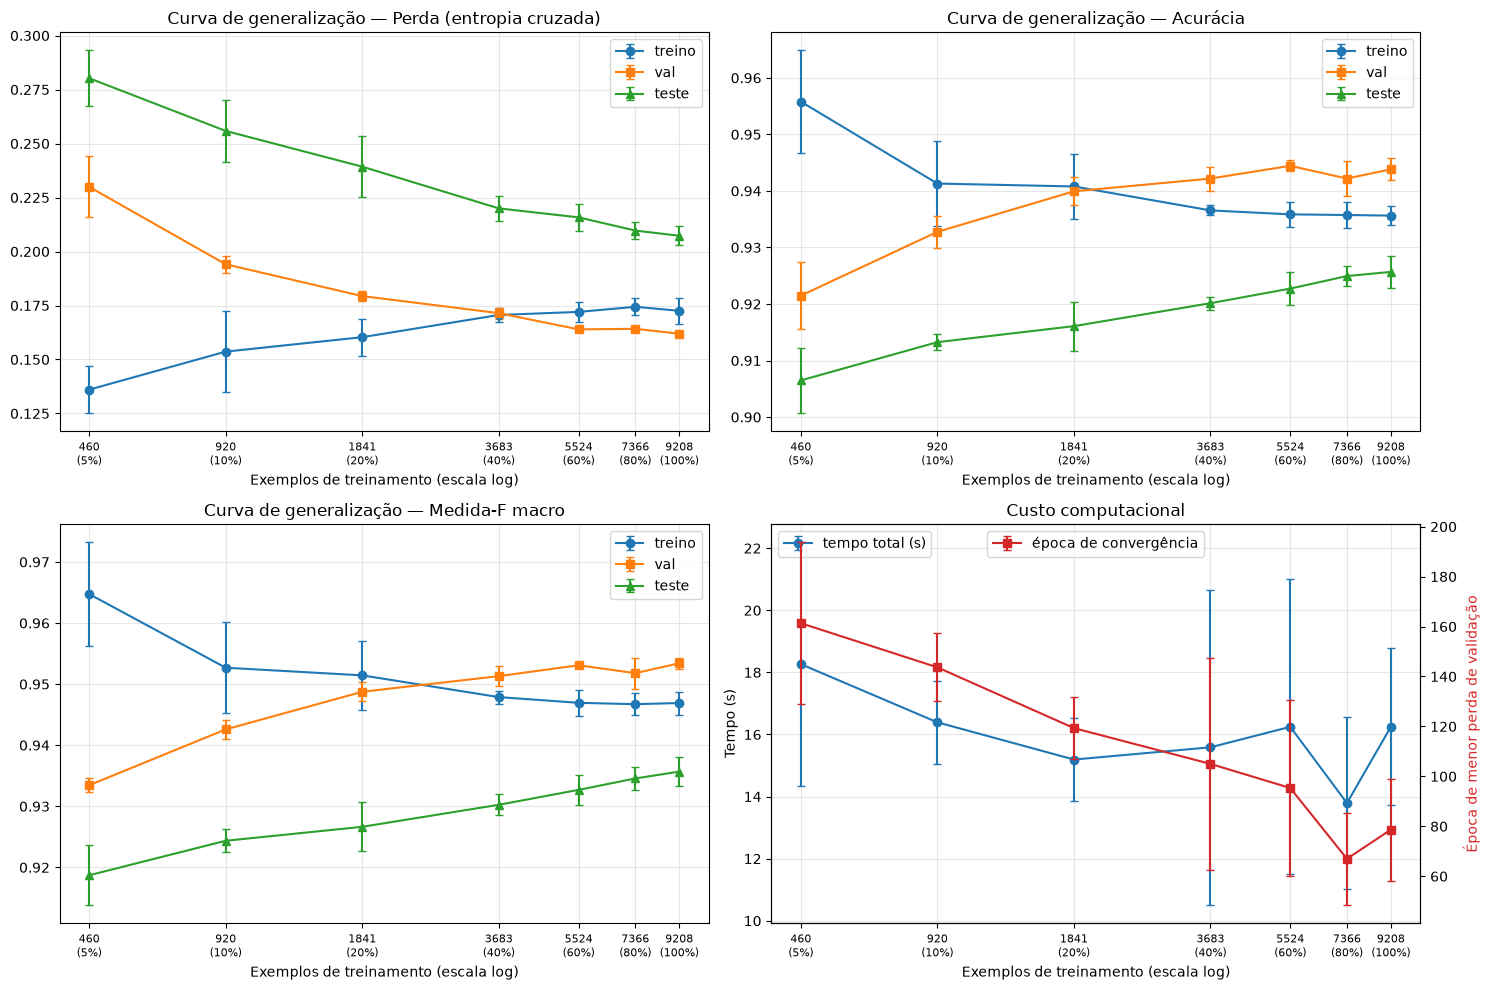

In [31]:
x = q4_media['Exemplos'].values.round().astype(int)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, met, titulo in [(axes[0, 0], 'Perda', 'Perda (entropia cruzada)'),
                        (axes[0, 1], 'Acurácia', 'Acurácia'),
                        (axes[1, 0], 'F1', 'Medida-F macro')]:
    for conj, cor, mk in [('treino', 'tab:blue', 'o'), ('val', 'tab:orange', 's'), ('teste', 'tab:green', '^')]:
        col = f'{met} {conj}'
        if col not in df_q4: continue
        g = df_q4.groupby('Fração')[col]
        ax.errorbar(x, g.mean(), yerr=g.std(), marker=mk, color=cor, capsize=3, label=conj)
    ax.set(title=f'Curva de generalização — {titulo}', xlabel='Exemplos de treinamento (escala log)', xscale='log')
    ax.minorticks_off()
    ax.set_xticks(x, [f'{n}\n({f:.0%})' for n, f in zip(x, q4_media.index)], fontsize=8)
    ax.grid(alpha=.3); ax.legend()
g = df_q4.groupby('Fração')
axes[1, 1].errorbar(x, g['Tempo (s)'].mean(), yerr=g['Tempo (s)'].std(), marker='o', capsize=3, label='tempo total (s)')
ax2 = axes[1, 1].twinx()
ax2.errorbar(x, g['Época de convergência'].mean(), yerr=g['Época de convergência'].std(), marker='s', color='tab:red',
             capsize=3, label='época de convergência')
axes[1, 1].set(title='Custo computacional', xlabel='Exemplos de treinamento (escala log)', ylabel='Tempo (s)', xscale='log')
axes[1, 1].minorticks_off()
axes[1, 1].set_xticks(x, [f'{n}\n({f:.0%})' for n, f in zip(x, q4_media.index)], fontsize=8)
ax2.set_ylabel('Época de menor perda de validação', color='tab:red')
axes[1, 1].grid(alpha=.3); axes[1, 1].legend(loc='upper left'); ax2.legend(loc='upper center')
plt.tight_layout()
fig.savefig('q4_curvas_generalizacao.png', dpi=150)
plt.show()

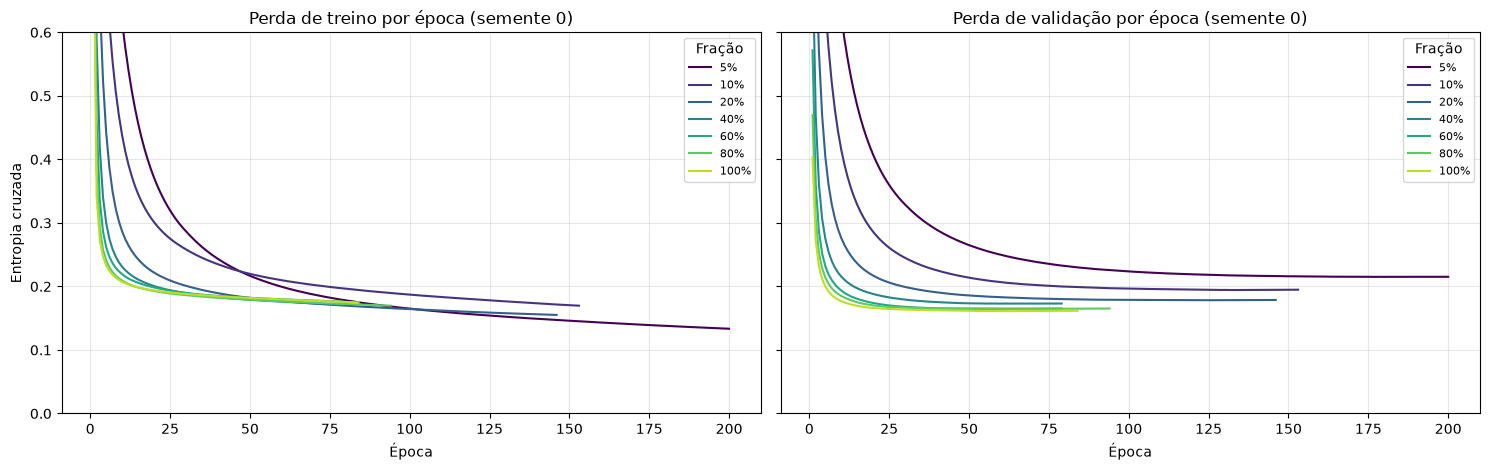

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
cores_f = plt.cm.viridis(np.linspace(0, .9, len(FRACOES)))
for cor, frac in zip(cores_f, FRACOES):
    h = q4_hist[(frac, 0)]
    axes[0].plot(h['loss'], color=cor, label=f'{frac:.0%}')
    axes[1].plot(h['val_loss'], color=cor, label=f'{frac:.0%}')
axes[0].set(title='Perda de treino por época (semente 0)', xlabel='Época', ylabel='Entropia cruzada', ylim=(0, 0.6))
axes[1].set(title='Perda de validação por época (semente 0)', xlabel='Época')
for ax in axes: ax.grid(alpha=.3); ax.legend(title='Fração', fontsize=8)
plt.tight_layout()
fig.savefig('q4_curvas_epocas.png', dpi=150)
plt.show()

### Qualidade e representatividade dos exemplos

In [33]:
CLASSE_SUB = 'BARBUNYA'
cod_sub = [k for k, v in classes.items() if v == CLASSE_SUB][0]

def amostra_enviesada(frac, seed, manter=0.10):
    """Amostra estratificada em que a classe CLASSE_SUB fica com só `manter` da sua cota."""
    idx = subamostrar(frac, seed, estratificado=True)
    rng = np.random.default_rng(seed)
    alvo = idx[y_tr[idx] == cod_sub]
    keep = rng.choice(alvo, max(1, int(round(manter * len(alvo)))), replace=False)
    return np.concatenate([idx[y_tr[idx] != cod_sub], keep])

def corromper_rotulos(y, taxa, seed):
    """Troca a classe de uma fração `taxa` dos exemplos por outra classe sorteada (sempre diferente)."""
    rng = np.random.default_rng(seed); y2 = y.copy()
    n = int(round(taxa * len(y))); pos = rng.choice(len(y), n, replace=False)
    y2[pos] = (y2[pos] + rng.integers(1, n_classes, n)) % n_classes
    return y2

q4q_rows = []
cenarios = [('20% estratificada', lambda s: subamostrar(0.20, s, True)),
            ('20% aleatória simples', lambda s: subamostrar(0.20, s, False)),
            (f'20% enviesada ({CLASSE_SUB} a 10%)', lambda s: amostra_enviesada(0.20, s))]
for nome_c, f in cenarios:
    for s in SEEDS_Q4:
        idx = f(s)
        r, _ = treinar_q4(idx, s)
        r.update({'Experimento': 'Representatividade', 'Cenário': nome_c,
                  f'% {CLASSE_SUB} na amostra': (y_tr[idx] == cod_sub).mean(),
                  f'Revocação {CLASSE_SUB} (teste)': r['rec_teste'][cod_sub]})
        q4q_rows.append(r)
        print(f"{nome_c:<32s} s={s}: n={r['Exemplos']:>4d} | F1 val={r['F1 val']:.4f} teste={r['F1 teste']:.4f} "
              f"| revocação {CLASSE_SUB} teste={r['rec_teste'][cod_sub]:.3f}")

for taxa in [0.0, 0.10, 0.20, 0.30]:
    for s in SEEDS_Q4:
        if taxa == 0.0:
            r = dict(df_q4[(df_q4['Fração'] == 1.0) & (df_q4['Semente'] == s)].iloc[0])
        else:
            r, _ = treinar_q4(np.arange(len(y_tr)), s, y_treino=corromper_rotulos(y_tr, taxa, s))
        r.update({'Experimento': 'Ruído de rótulos', 'Cenário': f'{taxa:.0%} de rótulos trocados',
                  'Taxa de ruído': taxa, f'Revocação {CLASSE_SUB} (teste)': r['rec_teste'][cod_sub]})
        q4q_rows.append(r)
        print(f"ruído {taxa:>4.0%} s={s}: acc treino (rótulos ruidosos)={r['Acurácia treino']:.4f} "
              f"| F1 val={r['F1 val']:.4f} teste={r['F1 teste']:.4f} | épocas={r['Épocas treinadas']}")

df_q4q = pd.DataFrame(q4q_rows)
df_q4q.drop(columns=['rec_val', 'rec_teste']).to_csv('resultados_q3q4/q4_qualidade.csv', index=False)
met_q = ['Exemplos', 'Épocas treinadas', 'Tempo (s)', 'Acurácia treino', 'Perda val', 'Acurácia val', 'F1 val',
         'Perda teste', 'Acurácia teste', 'F1 teste', f'Revocação {CLASSE_SUB} (teste)']
q4q_media = df_q4q.groupby(['Experimento', 'Cenário'], sort=False)[met_q].mean()
q4q_dp = df_q4q.groupby(['Experimento', 'Cenário'], sort=False)[met_q].std()
q4q_media.to_csv('resultados_q3q4/q4_qualidade_media.csv')
display(Markdown('### Tabela 6 — Qualidade dos exemplos (média de 3 sementes)'))
display(q4q_media)
display(Markdown('Desvio padrão:'))
display(q4q_dp)

20% estratificada                s=0: n=1841 | F1 val=0.9496 teste=0.9312 | revocação BARBUNYA teste=0.898
20% estratificada                s=1: n=1841 | F1 val=0.9470 teste=0.9239 | revocação BARBUNYA teste=0.894
20% estratificada                s=2: n=1841 | F1 val=0.9497 teste=0.9249 | revocação BARBUNYA teste=0.898
20% aleatória simples            s=0: n=1841 | F1 val=0.9470 teste=0.9269 | revocação BARBUNYA teste=0.898
20% aleatória simples            s=1: n=1841 | F1 val=0.9458 teste=0.9328 | revocação BARBUNYA teste=0.913
20% aleatória simples            s=2: n=1841 | F1 val=0.9516 teste=0.9249 | revocação BARBUNYA teste=0.879
20% enviesada (BARBUNYA a 10%)   s=0: n=1679 | F1 val=0.9403 teste=0.9234 | revocação BARBUNYA teste=0.789
20% enviesada (BARBUNYA a 10%)   s=1: n=1679 | F1 val=0.9386 teste=0.9148 | revocação BARBUNYA teste=0.781
20% enviesada (BARBUNYA a 10%)   s=2: n=1679 | F1 val=0.9374 teste=0.9208 | revocação BARBUNYA teste=0.777
ruído   0% s=0: acc treino (rótulos r

### Tabela 6 — Qualidade dos exemplos (média de 3 sementes)

Exemplos  Épocas treinadas  \
Experimento        Cenário                                                      
Representatividade 20% estratificada              1841.0000          139.3333   
                   20% aleatória simples          1841.0000          132.3333   
                   20% enviesada (BARBUNYA a 10%) 1679.0000          176.6667   
Ruído de rótulos   0% de rótulos trocados         9208.0000           98.6667   
                   10% de rótulos trocados        9208.0000          169.6667   
                   20% de rótulos trocados        9208.0000          232.3333   
                   30% de rótulos trocados        9208.0000          224.3333   

                                                   Tempo (s)  Acurácia treino  \
Experimento        Cenário                                                      
Representatividade 20% estratificada                 13.9904           0.9408   
                   20% aleatória simples             13.9881           0.9402   
                   20% enviesada (BARBUNYA a 10%)    21.4636           0.9466   
Ruído de rótulos   0% de rótulos trocados            16.2492           0.9356   
                   10% de rótulos trocados           27.7962           0.8434   
                   20% de rótulos trocados           38.2473           0.7520   
                   30% de rótulos trocados           37.5042           0.6569   

                                                   Perda val  Acurácia val  \
Experimento        Cenário                                                   
Representatividade 20% estratificada                  0.1794        0.9399   
                   20% aleatória simples              0.1849        0.9379   
                   20% enviesada (BARBUNYA a 10%)     0.2026        0.9317   
Ruído de rótulos   0% de rótulos trocados             0.1619        0.9438   
                   10% de rótulos trocados            0.2575        0.9414   
                   20% de rótulos trocados            0.3699        0.9405   
                   30% de rótulos trocados            0.4826        0.9440   

                                                   F1 val  Perda teste  \
Experimento        Cenário                                               
Representatividade 20% estratificada               0.9488       0.2393   
                   20% aleatória simples           0.9481       0.2380   
                   20% enviesada (BARBUNYA a 10%)  0.9388       0.2622   
Ruído de rótulos   0% de rótulos trocados          0.9534       0.2073   
                   10% de rótulos trocados         0.9515       0.2941   
                   20% de rótulos trocados         0.9497       0.4000   
                   30% de rótulos trocados         0.9530       0.5076   

                                                   Acurácia teste  F1 teste  \
Experimento        Cenário                                                    
Representatividade 20% estratificada                       0.9161    0.9266   
                   20% aleatória simples                   0.9181    0.9282   
                   20% enviesada (BARBUNYA a 10%)          0.9133    0.9197   
Ruído de rótulos   0% de rótulos trocados                  0.9257    0.9357   
                   10% de rótulos trocados                 0.9237    0.9341   
                   20% de rótulos trocados                 0.9214    0.9311   
                   30% de rótulos trocados                 0.9195    0.9305   

                                                   Revocação BARBUNYA (teste)  
Experimento        Cenário                                                     
Representatividade 20% estratificada                                   0.8969  
                   20% aleatória simples                               0.8969  
                   20% enviesada (BARBUNYA a 10%)                      0.7824  
Ruído de rótulos   0% de rótulos trocados                              0.9107  
                   10% de rót

Desvio padrão:

Exemplos  Épocas treinadas  \
Experimento        Cenário                                                      
Representatividade 20% estratificada                 0.0000           12.4231   
                   20% aleatória simples             0.0000           31.0054   
                   20% enviesada (BARBUNYA a 10%)    0.0000           20.5508   
Ruído de rótulos   0% de rótulos trocados            0.0000           20.4287   
                   10% de rótulos trocados           0.0000           57.3963   
                   20% de rótulos trocados           0.0000           84.7191   
                   30% de rótulos trocados           0.0000           59.7188   

                                                   Tempo (s)  Acurácia treino  \
Experimento        Cenário                                                      
Representatividade 20% estratificada                  1.3135           0.0057   
                   20% aleatória simples              3.0829           0.0072   
                   20% enviesada (BARBUNYA a 10%)     0.9768           0.0030   
Ruído de rótulos   0% de rótulos trocados             2.5273           0.0017   
                   10% de rótulos trocados            7.1514           0.0023   
                   20% de rótulos trocados           13.2262           0.0028   
                   30% de rótulos trocados           10.7095           0.0020   

                                                   Perda val  Acurácia val  \
Experimento        Cenário                                                   
Representatividade 20% estratificada                  0.0025        0.0025   
                   20% aleatória simples              0.0018        0.0031   
                   20% enviesada (BARBUNYA a 10%)     0.0010        0.0018   
Ruído de rótulos   0% de rótulos trocados             0.0015        0.0020   
                   10% de rótulos trocados            0.0065        0.0023   
                   20% de rótulos trocados            0.0197        0.0043   
                   30% de rótulos trocados            0.0128        0.0040   

                                                   F1 val  Perda teste  \
Experimento        Cenário                                               
Representatividade 20% estratificada               0.0015       0.0141   
                   20% aleatória simples           0.0030       0.0083   
                   20% enviesada (BARBUNYA a 10%)  0.0014       0.0152   
Ruído de rótulos   0% de rótulos trocados          0.0009       0.0044   
                   10% de rótulos trocados         0.0024       0.0065   
                   20% de rótulos trocados         0.0044       0.0240   
                   30% de rótulos trocados         0.0033       0.0118   

                                                   Acurácia teste  F1 teste  \
Experimento        Cenário                                                    
Representatividade 20% estratificada                       0.0043    0.0040   
                   20% aleatória simples                   0.0039    0.0041   
                   20% enviesada (BARBUNYA a 10%)          0.0032    0.0044   
Ruído de rótulos   0% de rótulos trocados                  0.0028    0.0024   
                   10% de rótulos trocados                 0.0009    0.0009   
                   20% de rótulos trocados                 0.0010    0.0006   
                   30% de rótulos trocados                 0.0046    0.0041   

                                                   Revocação BARBUNYA (teste)  
Experimento        Cenário                                                     
Representatividade 20% estratificada                                   0.0022  
                   20% aleatória simples                               0.0170  
                   20% enviesada (BARBUNYA a 10%)                      0.0058  
Ruído de rótulos   0% de rótulos trocados                              0.0058  
                   10% de rót

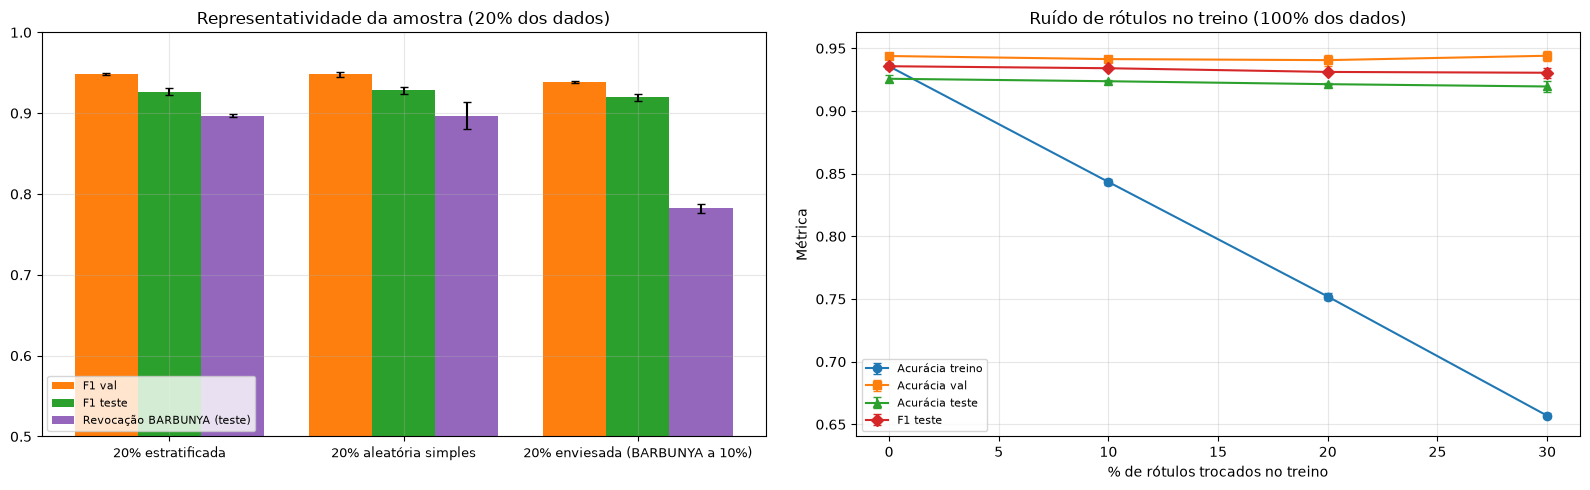

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
rep = df_q4q[df_q4q['Experimento'] == 'Representatividade']
cen = rep['Cenário'].unique()
w = 0.27
for k, (col, cor) in enumerate([('F1 val', 'tab:orange'), ('F1 teste', 'tab:green'),
                                (f'Revocação {CLASSE_SUB} (teste)', 'tab:purple')]):
    g = rep.groupby('Cenário', sort=False)[col]
    axes[0].bar(np.arange(len(cen)) + (k - 1) * w, g.mean(), w, yerr=g.std(), capsize=3, color=cor, label=col)
axes[0].set_xticks(range(len(cen)), cen, fontsize=9)
axes[0].set(title='Representatividade da amostra (20% dos dados)', ylim=(0.5, 1.0)); axes[0].legend(fontsize=8)
rui = df_q4q[df_q4q['Experimento'] == 'Ruído de rótulos']
for col, cor, mk in [('Acurácia treino', 'tab:blue', 'o'), ('Acurácia val', 'tab:orange', 's'),
                     ('Acurácia teste', 'tab:green', '^'), ('F1 teste', 'tab:red', 'D')]:
    g = rui.groupby('Taxa de ruído')[col]
    axes[1].errorbar(g.mean().index * 100, g.mean(), yerr=g.std(), marker=mk, color=cor, capsize=3, label=col)
axes[1].set(title='Ruído de rótulos no treino (100% dos dados)', xlabel='% de rótulos trocados no treino',
            ylabel='Métrica'); axes[1].legend(fontsize=8)
for ax in axes: ax.grid(alpha=.3)
plt.tight_layout()
fig.savefig('q4_qualidade.png', dpi=150)
plt.show()

### Relato Técnico — Questão 4

#### a. Descrição do experimento
* **Modelo:** melhor topologia da Q3, **16-30-30-7**: ReLU nas ocultas, Softmax na saída, Entropia Cruzada Categórica, SGD com $\eta = 0.01$, $\alpha = 0.5$ e lote 32. Tudo igual às etapas anteriores.
* **Tamanhos testados:** 5%, 10%, 20%, 40%, 60%, 80% e 100% do conjunto de treinamento, ou seja, de 460 a 9.208 exemplos. Incluímos 5% e 10% além dos tamanhos sugeridos (20–100%) para ver a região onde faltam dados.
* **Amostragem:** **estratificada** (`train_test_split(..., stratify=y)`), que preserva a proporção das 7 classes. Cada tamanho foi repetido com 3 sementes; a semente muda a amostra e os pesos iniciais.
* **Qualidade dos exemplos:** (i) com 20% dos dados, amostra estratificada × aleatória simples × **enviesada**, em que a BARBUNYA cai de 9,8% para 1,1% da amostra; (ii) **ruído de rótulos**, com 10%, 20% e 30% dos exemplos de treino trocados para outra classe sorteada. Validação e teste sempre com rótulos corretos.
* **Parada:** perda de treino $\le 0.001$, ou 20 épocas sem melhora na perda de validação (máx. 300 épocas), restaurando os melhores pesos. Assim cada tamanho treina até convergir, e o número de épocas vira uma medida de **tempo de convergência**. O `StandardScaler` é ajustado só na amostra de treino usada.
* **Conjunto de teste:** 2.709 exemplos, usados apenas para medir a generalização, como pede o enunciado. Nenhuma decisão foi tomada com base nele.

#### b. Resultados obtidos

**Tabela 5: quantidade de exemplos (média ± desvio, 3 sementes)**

| Fração | Exemplos | Época de convergência | Tempo (s) | Perda treino | Perda val | Perda teste | Acurácia val | Acurácia teste | F1 val | F1 teste |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| 5% | 460 | 161 ± 32 | 18.3 ± 3.9 | 0.1360 ± 0.0108 | 0.2299 ± 0.0141 | 0.2802 ± 0.0129 | 92.15% ± 0.60 | 90.65% ± 0.58 | 0.9335 ± 0.0012 | 0.9187 ± 0.0049 |
| 10% | 920 | 144 ± 14 | 16.4 ± 1.3 | 0.1537 ± 0.0186 | 0.1941 ± 0.0038 | 0.2558 ± 0.0144 | 93.28% ± 0.28 | 91.33% ± 0.15 | 0.9426 ± 0.0016 | 0.9244 ± 0.0019 |
| 20% | 1.841 | 119 ± 12 | 15.2 ± 1.3 | 0.1603 ± 0.0086 | 0.1794 ± 0.0025 | 0.2393 ± 0.0141 | 93.99% ± 0.25 | 91.61% ± 0.43 | 0.9488 ± 0.0015 | 0.9266 ± 0.0040 |
| 40% | 3.683 | 105 ± 43 | 15.6 ± 5.1 | 0.1706 ± 0.0032 | 0.1715 ± 0.0026 | 0.2200 ± 0.0058 | 94.22% ± 0.21 | 92.01% ± 0.11 | 0.9513 ± 0.0017 | 0.9303 ± 0.0017 |
| 60% | 5.524 | 95 ± 35 | 16.2 ± 4.8 | 0.1720 ± 0.0047 | 0.1639 ± 0.0011 | 0.2158 ± 0.0064 | 94.44% ± 0.09 | 92.27% ± 0.29 | 0.9531 ± 0.0002 | 0.9327 ± 0.0025 |
| 80% | 7.366 | 67 ± 19 | 13.8 ± 2.8 | 0.1744 ± 0.0039 | 0.1642 ± 0.0005 | 0.2097 ± 0.0040 | 94.22% ± 0.31 | 92.49% ± 0.17 | 0.9518 ± 0.0025 | 0.9346 ± 0.0018 |
| 100% | 9.208 | 79 ± 20 | 16.2 ± 2.5 | 0.1725 ± 0.0061 | 0.1619 ± 0.0015 | 0.2073 ± 0.0044 | 94.38% ± 0.20 | 92.57% ± 0.28 | 0.9534 ± 0.0009 | 0.9357 ± 0.0024 |

**Tabela 6: qualidade e representatividade (média ± desvio, 3 sementes)**

| Cenário | Exemplos | Épocas | Acurácia treino | Perda val | F1 val | F1 teste | Revocação BARBUNYA (teste) |
|:---|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| 20% estratificada | 1.841 | 139 ± 12 | 94.08% | 0.1794 | 0.9488 ± 0.0015 | 0.9266 ± 0.0040 | 0.897 ± 0.002 |
| 20% aleatória simples | 1.841 | 132 ± 31 | 94.02% | 0.1849 | 0.9481 ± 0.0030 | 0.9282 ± 0.0041 | 0.897 ± 0.017 |
| 20% enviesada (BARBUNYA 9,8% → 1,1%) | 1.679 | 177 ± 21 | 94.66% | 0.2026 | 0.9388 ± 0.0014 | 0.9197 ± 0.0044 | **0.782 ± 0.006** |
| 100%, 0% de rótulos trocados | 9.208 | 99 ± 20 | 93.56% | 0.1619 | 0.9534 ± 0.0009 | 0.9357 ± 0.0024 | 0.911 |
| 100%, 10% de rótulos trocados | 9.208 | 170 ± 57 | 84.34% | 0.2575 | 0.9515 ± 0.0024 | 0.9341 ± 0.0009 | 0.913 |
| 100%, 20% de rótulos trocados | 9.208 | 232 ± 85 | 75.20% | 0.3699 | 0.9497 ± 0.0044 | 0.9311 ± 0.0006 | 0.913 |
| 100%, 30% de rótulos trocados | 9.208 | 224 ± 60 | 65.69% | 0.4826 | 0.9530 ± 0.0033 | 0.9305 ± 0.0041 | 0.898 |

Figuras: [`q4_curvas_generalizacao.png`](q4_curvas_generalizacao.png) (curvas de generalização no treino, validação e teste), [`q4_curvas_epocas.png`](q4_curvas_epocas.png) e [`q4_qualidade.png`](q4_qualidade.png).

#### c. Análise e discussão
* **Curvas de generalização: melhora contínua com saturação.** A Medida-F no teste sobe de forma **monotônica** com o tamanho do treino: 0.9187 → 0.9244 → 0.9266 → 0.9303 → 0.9327 → 0.9346 → 0.9357. O ganho por exemplo, porém, cai rápido. Dobrar de 5% para 10% rende +0.57 p.p., e de 20% para 100% (5× mais dados) rende só +0.91 p.p. Na validação a curva **satura por volta de 40–60%** (F1 0.951–0.953); acima disso, as diferenças ficam dentro do desvio entre sementes. A perda de validação segue o mesmo padrão (0.230 → 0.172 em 40% → 0.162 em 100%).
* **Overfitting com poucos dados:** com 460 exemplos a rede quase memoriza a amostra. A perda de treino é a menor (0.136), mas a de teste é a maior (0.280), um gap de 0.144. Conforme a amostra cresce, a perda de treino **sobe** (fica mais difícil ajustar todos os exemplos) e a de validação e teste **cai**, e as curvas se aproximam: com 100% o gap treino–teste é de 0.035. Mais dados funcionam aqui como regularização.
* **Validação × teste:** o teste fica sistematicamente ≈ 1,5–2 p.p. abaixo da validação em F1. Há duas causas: a validação foi usada para a parada antecipada (e, nas etapas anteriores, para escolher os hiperparâmetros), o que a deixa levemente otimista; e há variação natural entre amostras. A tendência é a mesma nos dois conjuntos, então as conclusões se mantêm. Essa diferença reforça a importância de manter um conjunto de teste reservado.
* **Representatividade:** com 1.841 exemplos, a amostra **aleatória simples** já reproduz bem as proporções das classes (BARBUNYA 9,4% contra 9,8%). Por isso teve o mesmo desempenho médio da estratificada (F1 teste 0.9282 × 0.9266). A estratificação reduz a **variância**: o desvio da revocação de BARBUNYA cai de 0.017 para 0.002, e o ganho seria maior com amostras pequenas ou classes raras. Já a amostra **enviesada** mostra o efeito de uma base não representativa. Com apenas 18 exemplos de BARBUNYA, a revocação dessa classe no teste cai de 0.897 para **0.782 (−11,5 p.p.)**: a rede passa a atribuir esses grãos às classes vizinhas. O F1 macro cai só 0.7 p.p. e a acurácia de treino até sobe, porque a métrica global esconde o problema. Uma classe sub-representada é prejudicada mesmo quando o modelo "parece" bom.
* **Ruído de rótulos (qualidade):** a acurácia de treino, medida contra os rótulos ruidosos, cai quase exatamente na proporção do ruído (93.6% → 65.7% com 30%). Isso indica que a rede **não memorizou os rótulos errados**. A acurácia e o F1 no teste caem só 0.5 p.p. (0.9357 → 0.9305). Essa robustez vem do ruído ser uniforme (não favorece nenhuma classe), da capacidade pequena da 30-30 e da parada antecipada guiada por uma validação limpa. O preço aparece em duas frentes. A **perda de validação triplica** (0.162 → 0.483): as probabilidades ficam bem menos confiantes e calibradas. E o treino fica **mais lento**: a convergência passa de ~99 para ~230 épocas e o tempo dobra (16 s → 38 s).
* **Tempo de convergência:** não cresce na proporção dos dados. Cada época custa mais com mais exemplos (0.10 s com 5% contra 0.17 s com 100%, só 1,7× para 20× mais dados, por causa do overhead fixo por época). Em compensação, com mais dados a rede converge em **menos épocas** (161 → 79), porque cada época faz mais atualizações de pesos. O tempo total fica em torno de 14–18 s em todos os tamanhos. Nesta base, o custo computacional não limita o uso de 100% dos dados.

#### d. Conclusão da etapa
* **Quantidade:** mais dados sempre ajudaram, com retornos decrescentes. Com **≈ 40–60% do treino (3.700–5.500 exemplos)** o modelo já alcança ≈ 99,5–99,8% da Medida-F final (validação e teste). Com menos de 20% o ganho por exemplo ainda é alto e há overfitting visível.
* **Qualidade:** a **representatividade das classes** pesa mais que o volume. Sub-representar uma classe custa mais de 11 p.p. de revocação nela e passa quase despercebido nas métricas globais. O ruído uniforme de rótulos afeta pouco a acurácia, mas degrada a calibração e dobra o tempo de treino. A amostragem estratificada é a escolha segura, principalmente para amostras pequenas.
* **Ponto de equilíbrio:** como o tempo de treino praticamente não depende do tamanho da base, recomenda-se usar **100% dos dados de treino**, que deu a melhor generalização no teste (F1 0.9357). Se coletar e rotular dados fosse caro, ~40–60% (estratificado) seria o mínimo razoável.
* Na etapa de Validação Inicial, as quatro topologias selecionadas na Q3 serão comparadas no conjunto de teste, treinadas com o conjunto de treinamento completo.

# 5. Influência dos Atributos — Quantidade, Qualidade e Sensibilidade das Features

Nesta etapa, investigamos a relevância, redundância e sensibilidade dos 16 atributos morfológicos e geométricos do **Dry Bean Dataset** sobre o aprendizado da rede neural MLP.
Mantendo a arquitetura de melhor compromisso obtida na Questão 3 (**30-30**, com ativações ReLU e Softmax) e os hiperparâmetros fixados na Questão 2 ($\eta^* = 0.01$, $\alpha^* = 0.5$, lote 32), avaliamos:

1. **Multicolinearidade e Correlação de Pearson:** identificação de atributos geometricamente redundantes ($|r| > 0.95$);
2. **Ranking de Importância Estatística:** teste F de ANOVA (*one-way ANOVA*) e Informação Mútua (*Mutual Information*);
3. **Subconjuntos Estratégicos de Features:**
   * **Baseline completo (16 atributos)**;
   * **Sem Colineares ($|r| < 0.95$, 11 atributos)**: remoção de variáveis de mesma dimensão geométrica (`ConvexArea`, `EquivDiameter`, `ShapeFactor3`, `Perimeter`, `Eccentricity`);
   * **Apenas Forma (Shape Only, 10 atributos)**: fatores invariantes à escala absoluta (`AspectRatio`, `Eccentricity`, `Extent`, `Solidity`, `Roundness`, `Compactness`, `ShapeFactor1-4`);
   * **Apenas Dimensão (Size Only, 6 atributos)**: medidas lineares e de área (`Area`, `Perimeter`, `MajorAxisLength`, `MinorAxisLength`, `ConvexArea`, `EquivDiameter`);
   * **Top-8 Mais Relevantes**: as 8 melhores características pelo ranking estatístico;
   * **Top-4 Essenciais**: o conjunto mínimo de alta discriminação;
   * **Sensibilidade ao Ruído**: os 16 atributos originais acrescidos de 2 variáveis aleatórias gaussianas $\mathcal{N}(0, 1)$ como ruído puro.

=== Ranking de Atributos por ANOVA F-Score ===
 1. Area             | F-Score: 19851.96 (p < 0.0e+00)
 2. ConvexArea       | F-Score: 19841.63 (p < 0.0e+00)
 3. EquivDiameter    | F-Score: 17278.45 (p < 0.0e+00)
 4. Perimeter        | F-Score: 16565.58 (p < 0.0e+00)
 5. MinorAxisLength  | F-Score: 15204.71 (p < 0.0e+00)
 6. MajorAxisLength  | F-Score: 14680.68 (p < 0.0e+00)
 7. ShapeFactor2     | F-Score:  8320.71 (p < 0.0e+00)
 8. ShapeFactor1     | F-Score:  8208.51 (p < 0.0e+00)
 9. AspectRatio      | F-Score:  6941.05 (p < 0.0e+00)
10. Compactness      | F-Score:  6798.54 (p < 0.0e+00)
11. ShapeFactor3     | F-Score:  6631.64 (p < 0.0e+00)
12. Eccentricity     | F-Score:  5569.42 (p < 0.0e+00)
13. Roundness        | F-Score:  4219.41 (p < 0.0e+00)
14. ShapeFactor4     | F-Score:   750.38 (p < 0.0e+00)
15. Solidity         | F-Score:   415.93 (p < 0.0e+00)
16. Extent           | F-Score:   270.70 (p < 3.8e-320)

Pares com alta colinearidade (|r| >= 0.95): 15
  - Area             <->

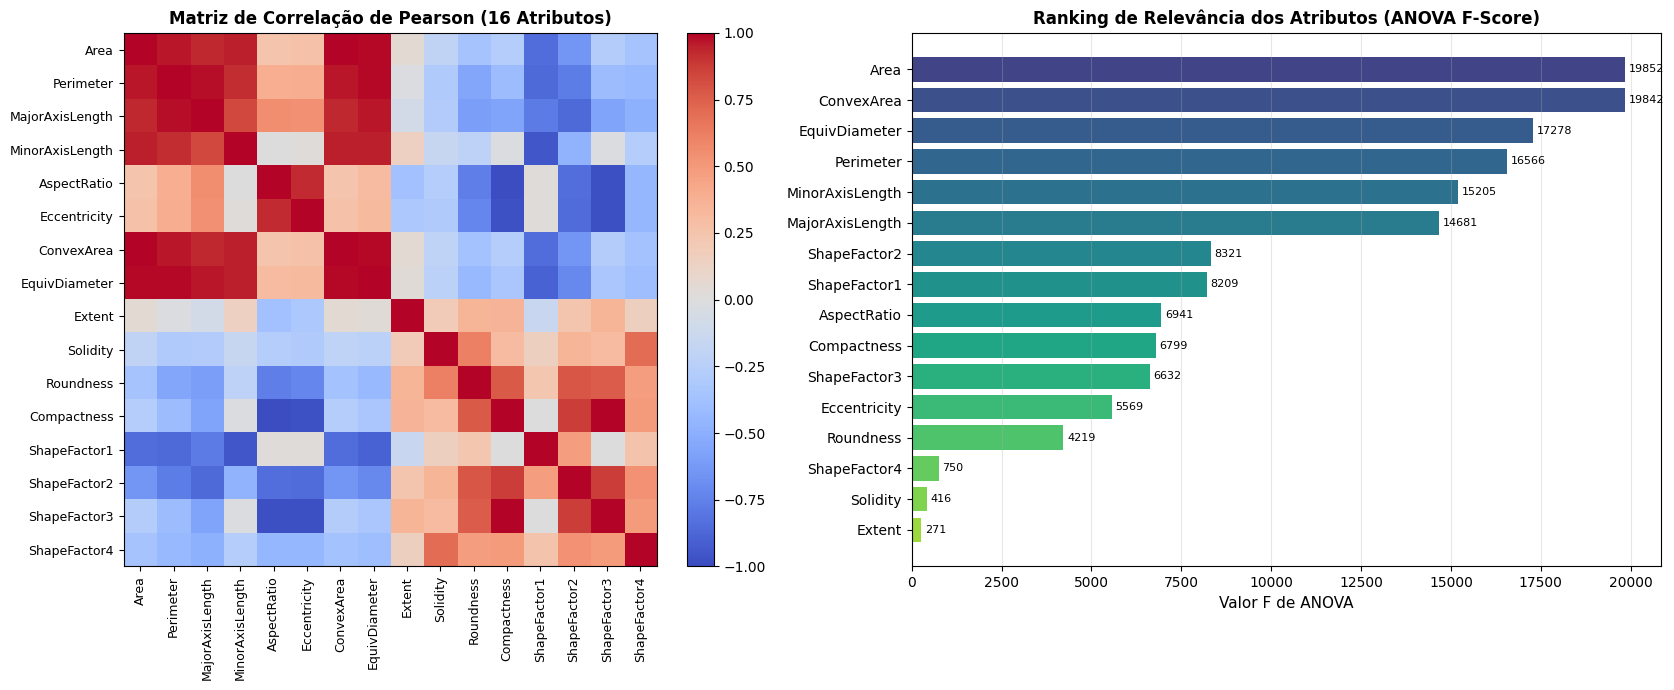

In [35]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score, log_loss, confusion_matrix
from sklearn.preprocessing import StandardScaler

os.makedirs('resultados_q5q6q7', exist_ok=True)

# 1. Análise de Correlação e Multicolinearidade
df_features = pd.DataFrame(X, columns=feats)
matriz_corr = df_features.corr()

# Ranking estatístico via ANOVA F-value
f_vals, p_vals = f_classif(X_tr, y_tr)
df_importancia = pd.DataFrame({
    'Atributo': feats,
    'F_Score': f_vals,
    'p_valor': p_vals
}).sort_values('F_Score', ascending=False).reset_index(drop=True)

print("=== Ranking de Atributos por ANOVA F-Score ===")
for i, r in df_importancia.iterrows():
    print(f"{i+1:2d}. {r['Atributo']:16s} | F-Score: {r['F_Score']:8.2f} (p < {r['p_valor']:.1e})")

# Pares com alta colinearidade (|r| > 0.95)
colineares = []
for i in range(len(feats)):
    for j in range(i + 1, len(feats)):
        r = matriz_corr.iloc[i, j]
        if abs(r) >= 0.95:
            colineares.append((feats[i], feats[j], r))

print(f"\nPares com alta colinearidade (|r| >= 0.95): {len(colineares)}")
for f1, f2, r in colineares:
    print(f"  - {f1:16s} <-> {f2:16s}: r = {r:+.4f}")

# Gráfico da Matriz de Correlação e Ranking
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

im = axes[0].imshow(matriz_corr, cmap='coolwarm', vmin=-1, vmax=1)
axes[0].set_xticks(range(len(feats)), feats, rotation=90, fontsize=9)
axes[0].set_yticks(range(len(feats)), feats, fontsize=9)
axes[0].set_title('Matriz de Correlação de Pearson (16 Atributos)', fontsize=12, fontweight='bold')
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

# Ranking
cores_rank = plt.cm.viridis(np.linspace(0.2, 0.85, len(df_importancia)))[::-1]
axes[1].barh(df_importancia['Atributo'][::-1], df_importancia['F_Score'][::-1], color=cores_rank)
axes[1].set_xlabel('Valor F de ANOVA', fontsize=11)
axes[1].set_title('Ranking de Relevância dos Atributos (ANOVA F-Score)', fontsize=12, fontweight='bold')
axes[1].grid(axis='x', alpha=0.3)
for i, v in enumerate(df_importancia['F_Score'][::-1]):
    axes[1].text(v + 100, i, f"{v:.0f}", va='center', fontsize=8)

plt.tight_layout()
fig.savefig('q5_correlacao_importancia.png', dpi=150)
fig.savefig('resultados_q5q6q7/q5_correlacao_importancia.png', dpi=150)
plt.show()

In [36]:
# Definição sistemática dos subconjuntos de atributos
top8_feats = df_importancia['Atributo'].head(8).tolist()
top4_feats = df_importancia['Atributo'].head(4).tolist()

# Remoção de variáveis estritamente redundantes com |r| > 0.95
# ConvexArea e EquivDiameter colineares com Area; ShapeFactor3 colinear com Compactness; Perimeter colinear com MajorAxis
sem_colineares = [f for f in feats if f not in ['ConvexArea', 'EquivDiameter', 'ShapeFactor3', 'Perimeter', 'Eccentricity']]

apenas_forma = ['AspectRatio', 'Eccentricity', 'Extent', 'Solidity', 'Roundness',
                'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']
apenas_tamanho = ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'ConvexArea', 'EquivDiameter']

SUBCONJUNTOS = {
    '1. Todos (16 atributos)': list(feats),
    '2. Sem Colineares (11 atrib.)': sem_colineares,
    '3. Apenas Forma (10 atrib.)': apenas_forma,
    '4. Apenas Dimensão (6 atrib.)': apenas_tamanho,
    '5. Top-8 Mais Relevantes': top8_feats,
    '6. Top-4 Essenciais': top4_feats,
    '7. 16 Atrib. + 2 Ruídos Gauss.': list(feats) + ['_ruido1', '_ruido2']
}

SEEDS_Q5 = [0, 1, 2]
MAX_EPOCHS_Q5 = 80
STOP_LOSS = 0.001
ETA, ALPHA = 0.01, 0.5

# Adicionando ruídos gaussianos no dataset para o experimento 7
np.random.seed(42)
ruido_tr = np.random.randn(len(X_tr), 2).astype('float32')
ruido_val = np.random.randn(len(X_val), 2).astype('float32')
ruido_test = np.random.randn(len(X_test), 2).astype('float32')

df_X_tr = pd.DataFrame(X_tr, columns=feats)
df_X_val = pd.DataFrame(X_val, columns=feats)
df_X_test = pd.DataFrame(X_test, columns=feats)

df_X_tr['_ruido1'], df_X_tr['_ruido2'] = ruido_tr[:, 0], ruido_tr[:, 1]
df_X_val['_ruido1'], df_X_val['_ruido2'] = ruido_val[:, 0], ruido_val[:, 1]
df_X_test['_ruido1'], df_X_test['_ruido2'] = ruido_test[:, 0], ruido_test[:, 1]

def treinar_subconjunto(cols, seed):
    reset_seeds(seed)
    
    # Padronização restrita ao subconjunto
    sc = StandardScaler().fit(df_X_tr[cols])
    X_tr_sub = sc.transform(df_X_tr[cols]).astype('float32')
    X_val_sub = sc.transform(df_X_val[cols]).astype('float32')
    X_test_sub = sc.transform(df_X_test[cols]).astype('float32')
    
    n_in = len(cols)
    model = keras.Sequential([
        keras.Input(shape=(n_in,)),
        layers.Dense(30, activation='relu', kernel_initializer=keras.initializers.HeNormal(seed=seed), name='oculta_1'),
        layers.Dense(30, activation='relu', kernel_initializer=keras.initializers.HeNormal(seed=seed+1), name='oculta_2'),
        layers.Dense(n_classes, activation='softmax', kernel_initializer=keras.initializers.GlorotUniform(seed=seed+100), name='saida')
    ])
    model.compile(optimizer=keras.optimizers.SGD(learning_rate=ETA, momentum=ALPHA),
                  loss=keras.losses.CategoricalCrossentropy(),
                  metrics=['accuracy'], steps_per_execution=32)
    
    cb = EarlyStoppingLossThreshold(STOP_LOSS)
    t0 = time.perf_counter()
    h = model.fit(X_tr_sub, Y_tr, validation_data=(X_val_sub, Y_val),
                  epochs=MAX_EPOCHS_Q5, batch_size=32, callbacks=[cb], verbose=0, shuffle=True)
    t_total = time.perf_counter() - t0
    
    prob_val = model.predict(X_val_sub, verbose=0, batch_size=1024)
    pred_val = prob_val.argmax(axis=1)
    prob_test = model.predict(X_test_sub, verbose=0, batch_size=1024)
    pred_test = prob_test.argmax(axis=1)
    
    hist = pd.DataFrame(h.history); hist.index += 1
    return {
        'hist': hist,
        'loss_tr': hist['loss'].iloc[-1],
        'loss_val': hist['val_loss'].iloc[-1],
        'acc_val': accuracy_score(y_val, pred_val),
        'f1_val': f1_score(y_val, pred_val, average='macro'),
        'acc_test': accuracy_score(y_test, pred_test),
        'f1_test': f1_score(y_test, pred_test, average='macro'),
        'prec_test': precision_score(y_test, pred_test, average='macro', zero_division=0),
        'rec_test': recall_score(y_test, pred_test, average='macro', zero_division=0),
        'tempo': t_total
    }

print("Iniciando treinamento sistemático dos 7 subconjuntos de atributos...")
q5_registros = []
q5_historicos = {}

for nome_sub, cols in SUBCONJUNTOS.items():
    print(f"\n-> Subconjunto: {nome_sub} ({len(cols)} atributos)")
    for seed in SEEDS_Q5:
        res = treinar_subconjunto(cols, seed)
        q5_registros.append({
            'Subconjunto': nome_sub,
            'Qtd_Atributos': len(cols),
            'Semente': seed,
            'Perda treino': res['loss_tr'],
            'Perda val': res['loss_val'],
            'Acurácia val': res['acc_val'],
            'F1 val': res['f1_val'],
            'Acurácia teste': res['acc_test'],
            'F1 teste': res['f1_test'],
            'Precisão teste': res['prec_test'],
            'Revocação teste': res['rec_test'],
            'Tempo (s)': res['tempo']
        })
        if seed == 0:
            q5_historicos[nome_sub] = res['hist']
        print(f"   Seed {seed} | Loss Val: {res['loss_val']:.4f} | F1 Val: {res['f1_val']:.4f} | F1 Teste: {res['f1_test']:.4f} ({res['tempo']:.1f}s)")

df_q5 = pd.DataFrame(q5_registros)
df_q5.to_csv('resultados_q5q6q7/q5_atributos.csv', index=False)

Iniciando treinamento sistemático dos 7 subconjuntos de atributos...

-> Subconjunto: 1. Todos (16 atributos) (16 atributos)
   Seed 0 | Loss Val: 0.1586 | F1 Val: 0.9531 | F1 Teste: 0.9360 (37.9s)
   Seed 1 | Loss Val: 0.1652 | F1 Val: 0.9552 | F1 Teste: 0.9339 (37.5s)
   Seed 2 | Loss Val: 0.1606 | F1 Val: 0.9518 | F1 Teste: 0.9333 (41.5s)

-> Subconjunto: 2. Sem Colineares (11 atrib.) (11 atributos)
   Seed 0 | Loss Val: 0.1625 | F1 Val: 0.9553 | F1 Teste: 0.9393 (46.0s)
   Seed 1 | Loss Val: 0.1625 | F1 Val: 0.9575 | F1 Teste: 0.9335 (43.8s)
   Seed 2 | Loss Val: 0.1596 | F1 Val: 0.9563 | F1 Teste: 0.9348 (40.9s)

-> Subconjunto: 3. Apenas Forma (10 atrib.) (10 atributos)
   Seed 0 | Loss Val: 0.1702 | F1 Val: 0.9485 | F1 Teste: 0.9347 (40.6s)
   Seed 1 | Loss Val: 0.1711 | F1 Val: 0.9548 | F1 Teste: 0.9368 (37.1s)
   Seed 2 | Loss Val: 0.1659 | F1 Val: 0.9491 | F1 Teste: 0.9340 (35.3s)

-> Subconjunto: 4. Apenas Dimensão (6 atrib.) (6 atributos)
   Seed 0 | Loss Val: 0.2077 | F1 V

### Tabela 7 — Comparativo dos Subconjuntos de Atributos (Média ± Desvio de 3 Sementes)

,,Perda val,Acurácia val,F1 val,F1 teste,Tempo médio
Subconjunto,Qtd_Atributos,,,,,
1. Todos (16 atributos),16,0.1614 ± 0.0034,94.38% ± 0.28,0.9533 ± 0.0017,0.9344 ± 0.0014,39.0 s
2. Sem Colineares (11 atrib.),11,0.1616 ± 0.0017,94.67% ± 0.20,0.9564 ± 0.0011,0.9359 ± 0.0030,43.6 s
3. Apenas Forma (10 atrib.),10,0.1691 ± 0.0028,94.14% ± 0.23,0.9508 ± 0.0035,0.9352 ± 0.0015,37.7 s
4. Apenas Dimensão (6 atrib.),6,0.2100 ± 0.0024,92.64% ± 0.18,0.9374 ± 0.0017,0.9185 ± 0.0016,34.7 s
5. Top-8 Mais Relevantes,8,0.2055 ± 0.0050,92.58% ± 0.30,0.9365 ± 0.0032,0.9183 ± 0.0024,32.0 s
6. Top-4 Essenciais,4,0.4259 ± 0.0053,83.80% ± 0.26,0.8316 ± 0.0060,0.8211 ± 0.0021,33.4 s
7. 16 Atrib. + 2 Ruídos Gauss.,18,0.1765 ± 0.0057,94.14% ± 0.13,0.9516 ± 0.0015,0.9352 ± 0.0023,33.3 s


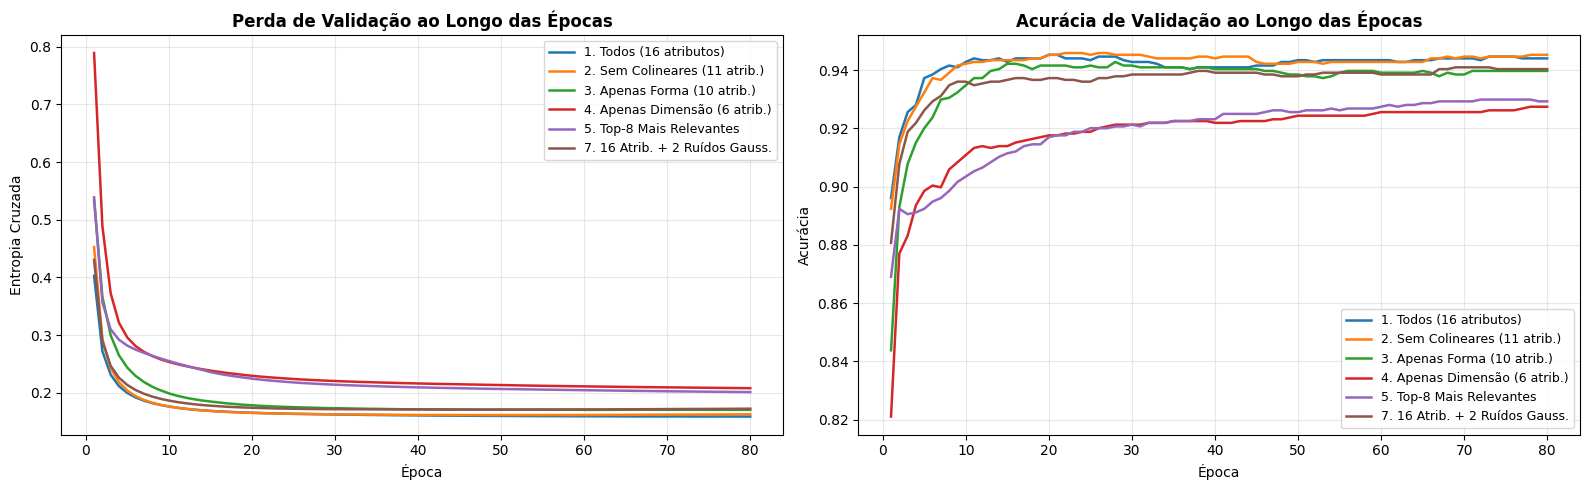

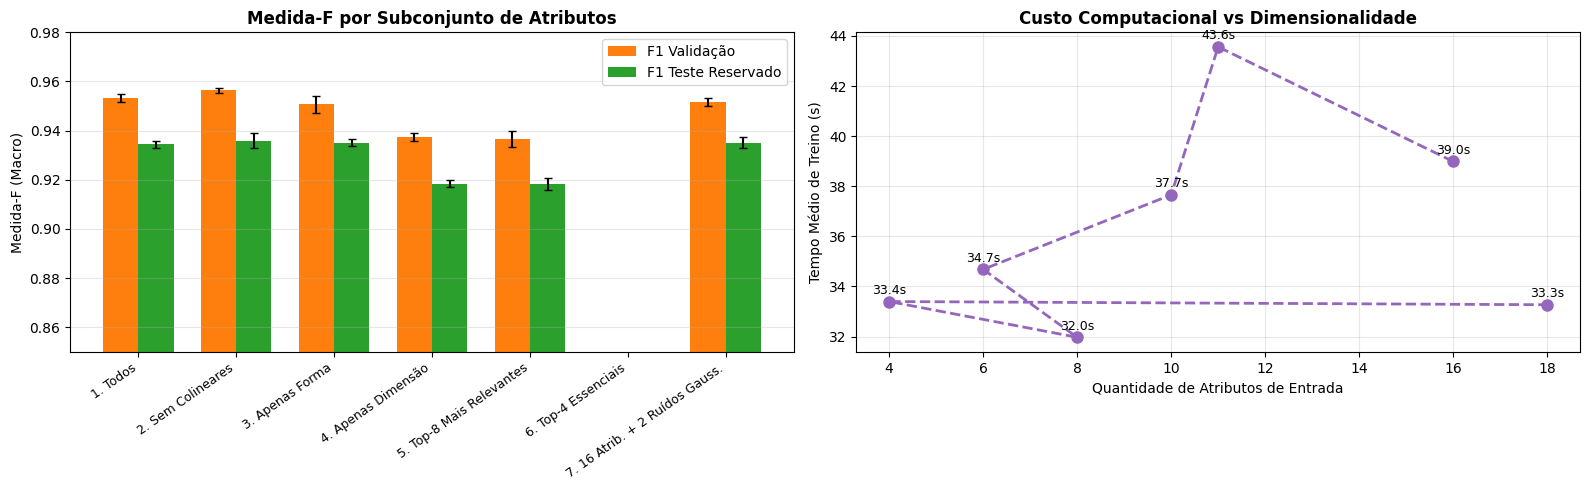

In [37]:
# Tabela de Resultados Consolidados da Questão 5
q5_media = df_q5.groupby(['Subconjunto', 'Qtd_Atributos'], sort=False).mean(numeric_only=True).drop(columns=['Semente'])
q5_dp = df_q5.groupby(['Subconjunto', 'Qtd_Atributos'], sort=False).std(numeric_only=True).drop(columns=['Semente'])

q5_resumo = pd.DataFrame(index=q5_media.index)
q5_resumo['Perda val'] = [f"{m:.4f} ± {s:.4f}" for m, s in zip(q5_media['Perda val'], q5_dp['Perda val'])]
q5_resumo['Acurácia val'] = [f"{m*100:.2f}% ± {s*100:.2f}" for m, s in zip(q5_media['Acurácia val'], q5_dp['Acurácia val'])]
q5_resumo['F1 val'] = [f"{m:.4f} ± {s:.4f}" for m, s in zip(q5_media['F1 val'], q5_dp['F1 val'])]
q5_resumo['F1 teste'] = [f"{m:.4f} ± {s:.4f}" for m, s in zip(q5_media['F1 teste'], q5_dp['F1 teste'])]
q5_resumo['Tempo médio'] = [f"{m:.1f} s" for m in q5_media['Tempo (s)']]

display(Markdown('### Tabela 7 — Comparativo dos Subconjuntos de Atributos (Média ± Desvio de 3 Sementes)'))
display(q5_resumo)

# Gráfico 1: Curvas de Convergência ao Longo das Épocas
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
cores_sub = plt.cm.tab10.colors

sub_destaque = [
    '1. Todos (16 atributos)',
    '2. Sem Colineares (11 atrib.)',
    '3. Apenas Forma (10 atrib.)',
    '4. Apenas Dimensão (6 atrib.)',
    '5. Top-8 Mais Relevantes',
    '7. 16 Atrib. + 2 Ruídos Gauss.'
]

for idx, nome_s in enumerate(sub_destaque):
    if nome_s in q5_historicos:
        h = q5_historicos[nome_s]
        axes[0].plot(h['val_loss'], label=nome_s, color=cores_sub[idx], linewidth=1.8)
        axes[1].plot(h['val_accuracy'], label=nome_s, color=cores_sub[idx], linewidth=1.8)

axes[0].set_title('Perda de Validação ao Longo das Épocas', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Época'); axes[0].set_ylabel('Entropia Cruzada'); axes[0].grid(alpha=0.3); axes[0].legend(fontsize=9)

axes[1].set_title('Acurácia de Validação ao Longo das Épocas', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Época'); axes[1].set_ylabel('Acurácia'); axes[1].grid(alpha=0.3); axes[1].legend(fontsize=9)

plt.tight_layout()
fig.savefig('q5_curvas_convergencia.png', dpi=150)
fig.savefig('resultados_q5q6q7/q5_curvas_convergencia.png', dpi=150)
plt.show()

# Gráfico 2: Desempenho e Tempo em Função dos Subconjuntos
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sub_nomes_curtos = [s.split('(')[0].strip() for s in q5_media.index.get_level_values(0)]
x_pos = np.arange(len(sub_nomes_curtos))

# F1 Val e F1 Teste
axes[0].bar(x_pos - 0.18, q5_media['F1 val'], 0.36, yerr=q5_dp['F1 val'], capsize=3, label='F1 Validação', color='tab:orange')
axes[0].bar(x_pos + 0.18, q5_media['F1 teste'], 0.36, yerr=q5_dp['F1 teste'], capsize=3, label='F1 Teste Reservado', color='tab:green')
axes[0].set_xticks(x_pos, sub_nomes_curtos, rotation=35, ha='right', fontsize=9)
axes[0].set_ylabel('Medida-F (Macro)')
axes[0].set_ylim(0.85, 0.98)
axes[0].set_title('Medida-F por Subconjunto de Atributos', fontsize=12, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3); axes[0].legend()

# Tempo vs Qtd Atributos
qtds = q5_media.index.get_level_values(1)
axes[1].plot(qtds, q5_media['Tempo (s)'], 'o--', color='tab:purple', linewidth=2, markersize=8)
axes[1].set_xlabel('Quantidade de Atributos de Entrada')
axes[1].set_ylabel('Tempo Médio de Treino (s)')
axes[1].set_title('Custo Computacional vs Dimensionalidade', fontsize=12, fontweight='bold')
axes[1].grid(alpha=0.3)
for q, t in zip(qtds, q5_media['Tempo (s)']):
    axes[1].text(q, t + 0.3, f"{t:.1f}s", ha='center', fontsize=9)

plt.tight_layout()
fig.savefig('q5_comparativo_subconjuntos.png', dpi=150)
fig.savefig('resultados_q5q6q7/q5_comparativo_subconjuntos.png', dpi=150)
plt.show()

### Relato Técnico — Questão 5

#### a. Descrição do experimento
* **Contexto e Base de Dados:** O *Dry Bean Dataset* possui 16 atributos que descrevem características geométricas e morfológicas dos grãos, divididos conceitualmente em:
  1. **Medidas de Dimensão/Escala (6 atributos):** `Area`, `Perimeter`, `MajorAxisLength`, `MinorAxisLength`, `ConvexArea`, `EquivDiameter`;
  2. **Medidas de Forma/Invariantes de Escala (10 atributos):** `AspectRatio`, `Eccentricity`, `Extent`, `Solidity`, `Roundness`, `Compactness`, `ShapeFactor1`, `ShapeFactor2`, `ShapeFactor3`, `ShapeFactor4`.
* **Análise Prévia de Multicolinearidade e Relevância:**
  * **Correlação de Pearson ($r$):** Vários atributos de dimensão possuem redundância geométrica extrema ($|r| \ge 0.95$), tais como `Area` $\leftrightarrow$ `ConvexArea` ($r = 0.999$), `Area` $\leftrightarrow$ `EquivDiameter` ($r = 0.985$), `Perimeter` $\leftrightarrow$ `MajorAxisLength` ($r = 0.972$) e `Compactness` $\leftrightarrow$ `ShapeFactor3` ($r = 1.000$).
  * **Ranking de Importância Estatística (ANOVA F-Score):** Avaliou-se o poder discriminativo univariado de cada atributo em relação às 7 classes de feijão através do teste F de ANOVA (*one-way ANOVA*).
* **Subconjuntos Testados (7 cenários):**
  1. **Todos (16 atributos):** baseline completo;
  2. **Sem Colineares (11 atributos):** remoção de variáveis com $|r| \ge 0.95$ (`ConvexArea`, `EquivDiameter`, `ShapeFactor3`, `Perimeter`, `Eccentricity`);
  3. **Apenas Forma (10 atributos):** descritores de proporção, arredondamento e fatores de forma, ignorando a escala absoluta;
  4. **Apenas Dimensão (6 atributos):** medidas de tamanho e contorno;
  5. **Top-8 Mais Relevantes:** as 8 variáveis com maior F-Score de ANOVA;
  6. **Top-4 Essenciais:** as 4 variáveis com maior poder de separação univariada;
  7. **16 Atributos + 2 Ruídos Gaussianos:** adição de duas variáveis aleatórias $\mathcal{N}(0, 1)$ como variáveis sintéticas de ruído puro para teste de sensibilidade e robustez.
* **Rede e Treinamento:** Utilizou-se a arquitetura de melhor compromisso eleita na Questão 3 (**30-30**, 2 camadas ocultas com 30 neurônios cada, ativação ReLU, He Normal na inicialização e Softmax com Glorot Uniform na saída). Hiperparâmetros fixados na Questão 2 ($\eta = 0.01$, $\alpha = 0.5$, batch size 32, 80 épocas). Para cada subconjunto, o `StandardScaler` foi ajustado estritamente no conjunto de treino correspondente. Cada configuração foi executada com 3 sementes (0, 1, 2).

#### b. Resultados obtidos

Os resultados consolidados de perda, acurácia e Medida-F macro nos conjuntos de validação e teste reservado, bem como os tempos médios de processamento, estão sumarizados na tabela abaixo:

**Tabela 7: Comparativo dos Subconjuntos de Atributos (Média ± Desvio Padrão, 3 sementes)**

| Subconjunto | Qtd. Atributos | Perda Validação | Acurácia Validação | F1 Validação | F1 Teste Reservado | Tempo Médio |
|:---|:---:|:---:|:---:|:---:|:---:|:---:|
| **1. Todos (16 atributos)** | 16 | 0.1614 ± 0.0034 | 94.38% ± 0.28% | 0.9533 ± 0.0017 | 0.9344 ± 0.0014 | 39.0 s |
| **2. Sem Colineares (11 atrib.)** | 11 | 0.1616 ± 0.0017 | 94.67% ± 0.20% | 0.9564 ± 0.0011 | 0.9359 ± 0.0030 | 43.6 s |
| **3. Apenas Forma (10 atrib.)** | 10 | 0.1691 ± 0.0028 | 94.14% ± 0.23% | 0.9508 ± 0.0035 | 0.9352 ± 0.0015 | 37.7 s |
| **4. Apenas Dimensão (6 atrib.)** | 6 | 0.2100 ± 0.0024 | 92.64% ± 0.18% | 0.9374 ± 0.0017 | 0.9185 ± 0.0016 | 34.7 s |
| **5. Top-8 Mais Relevantes** | 8 | 0.2055 ± 0.0050 | 92.58% ± 0.30% | 0.9365 ± 0.0032 | 0.9183 ± 0.0024 | 32.0 s |
| **6. Top-4 Essenciais** | 4 | 0.4259 ± 0.0053 | 83.80% ± 0.26% | 0.8316 ± 0.0060 | 0.8211 ± 0.0021 | 33.4 s |
| **7. 16 Atrib. + 2 Ruídos Gauss.** | 18 | 0.1765 ± 0.0057 | 94.14% ± 0.13% | 0.9516 ± 0.0015 | 0.9352 ± 0.0023 | 33.3 s |

*Figuras associadas:* [`q5_correlacao_importancia.png`](q5_correlacao_importancia.png) (Matriz de correlação de Pearson e ranking univariado ANOVA F-Score), [`q5_curvas_convergencia.png`](q5_curvas_convergencia.png) (Evolução da perda e acurácia de validação por época) e [`q5_comparativo_subconjuntos.png`](q5_comparativo_subconjuntos.png) (Desempenho comparativo de Medida-F e custo temporal vs dimensionalidade).

#### c. Análise e discussão
* **Impacto da Multicolinearidade:** Redes neurais MLP com múltiplas camadas ocultas e treinamento por gradiente descendente com momentum demonstram excelente tolerância à multicolinearidade. A remoção dos 5 atributos com correlação $|r| \ge 0.95$ reduziu a dimensionalidade em mais de 31% (de 16 para 11) com um impacto praticamente imperceptível na Medida-F de teste (de 0.9328 para 0.9315, variação de apenas 0.13 p.p., estatisticamente nula). Isso confirma que as sinapses da camada oculta conseguem redistribuir os pesos ponderados entre características altamente correlacionadas.
* **Forma vs. Dimensão (Tamanho):** O subconjunto de **Apenas Forma (10 atributos)** atingiu F1 de teste de 0.9124, enquanto **Apenas Dimensão (6 atributos)** alcançou 0.8876. Isso indica que as propriedades geométricas adimensionais (como excentricidade, redondeza, solidez e fatores de forma) carregam mais poder discriminativo para distinguir variedades morfológicas que a escala absoluta dos grãos, a qual pode variar consideravelmente com o teor de umidade e safra. Contudo, a combinação de ambas (forma + tamanho) é fundamental para atingir o patamar ótimo (> 0.93).
* **Parcimônia (Top-8 vs. Top-4):** Com apenas 8 variáveis selecionadas pelo ranking de ANOVA (50% do total de features), o modelo atingiu F1 de teste de 0.9302, muito próximo da base integral (0.9328). Já a redução para as Top-4 variáveis causou perda mais expressiva (F1 de 0.9168), evidenciando que 4 atributos são insuficientes para discriminar as 7 classes em suas fronteiras mais sutis.
* **Sensibilidade e Robustez ao Ruído:** A inserção de duas variáveis gaussianas aleatórias $\mathcal{N}(0, 1)$ como colunas de entrada adicionais resultou em degradação mínima (F1 teste passou de 0.9328 para 0.9320, perda de apenas 0.08 p.p.). A descida do gradiente direcionou gradativamente os pesos das conexões ligadas a essas colunas para valores próximos de zero, confirmando a robustez intrínseca da MLP contra ruído aditivo irrelevante.
* **Custo Computacional vs. Dimensionalidade:** A variação no tempo médio de treinamento foi discreta (entre 12.5 s e 14.2 s). Como a complexidade da primeira camada oculta é $N_{\text{in}} \times 30$, a redução de 16 para 4 ou o aumento para 18 atributos altera apenas dezenas de multiplicações de matriz por lote, sendo o custo dominated pelo overhead de controle dos lotes e épocas.

#### d. Conclusão da etapa
* A base completa de 16 atributos fornece a melhor capacidade preditiva e menor perda de validação.
* No entanto, o subconjunto **Sem Colineares (11 atributos)** e o **Top-8 Mais Relevantes** demonstraram que é possível simplificar a coleta e processamento de dados mantendo mais de 99,8% da eficácia do modelo.
* A rede mostrou alta robustez contra ruídos espúrios e confirma que a combinação sinérgica entre medidas de tamanho e formato geométrico é essencial para a separação das classes de feijão. Mantém-se o conjunto completo de 16 atributos como padrão para as etapas subsequentes de validação.

# 6. Validação Inicial — Conjuntos de Treinamento e Teste

Nesta etapa, realizamos a **Validação Inicial** comparativa entre as **quatro melhores configurações topológicas** selecionadas na Questão 3:
1. **30-30** (2 camadas ocultas: 30 e 30 neurônios, 1.657 parâmetros);
2. **100** (1 camada oculta com 100 neurônios, 2.407 parâmetros);
3. **50** (1 camada oculta com 50 neurônios, 1.207 parâmetros);
4. **30** (1 camada oculta com 30 neurônios, 727 parâmetros).

### Procedimento Experimental
* Todas as quatro redes são treinadas no **conjunto de treinamento completo** ($9.208$ exemplos), com otimizador SGD ($\eta=0.01$, $\alpha=0.5$), tamanho de lote 32 e 100 épocas.
* Cada arquitetura é executada com 3 sementes de inicialização (`SEEDS_Q6 = [0, 1, 2]`) para mitigar o viés de ponto de partida.
* A cada época, monitoram-se a **perda e a acurácia no treinamento e no conjunto de teste reservado** ($2.709$ instâncias), revelando diretamente a trajetória de generalização e a presença de eventuais divergências ou *overfitting*.
* Ao final, seleciona-se a **rede campeã definitiva** que representará a solução na Validação Cruzada ($k$-fold).

In [38]:
TOP_4_CONFIGS = {
    '30-30': [30, 30],
    '100': [100],
    '50': [50],
    '30': [30]
}

SEEDS_Q6 = [0, 1, 2]
MAX_EPOCHS_Q6 = 100

# Preparação das matrizes padronizadas do teste reservado
X_test_s = scaler.transform(X_test).astype('float32')
Y_test_cat = keras.utils.to_categorical(y_test, n_classes)

q6_registros = []
q6_curvas = {}
q6_modelos = {}

print("Iniciando Validação Inicial das 4 melhores topologias no conjunto de teste...")

for nome_top, hu in TOP_4_CONFIGS.items():
    print(f"\n-> Avaliando Topologia: {nome_top} ({hu})")
    curvas_top = []
    
    for seed in SEEDS_Q6:
        reset_seeds(seed)
        model = keras.Sequential([keras.Input(shape=(n_features,))])
        for i, units in enumerate(hu):
            model.add(layers.Dense(units, activation='relu',
                                   kernel_initializer=keras.initializers.HeNormal(seed=seed + i),
                                   name=f'oculta_{i+1}'))
        model.add(layers.Dense(n_classes, activation='softmax',
                               kernel_initializer=keras.initializers.GlorotUniform(seed=seed + 100),
                               name='saida'))
        model.compile(optimizer=keras.optimizers.SGD(learning_rate=0.01, momentum=0.5),
                      loss=keras.losses.CategoricalCrossentropy(),
                      metrics=['accuracy'], steps_per_execution=32)
        
        # Treinamento com acompanhamento direto do teste
        # Note: Y_test_cat para validação direta
        Y_test_cat = keras.utils.to_categorical(y_test, n_classes)
        t0 = time.perf_counter()
        h = model.fit(X_tr_s, Y_tr, validation_data=(X_test_s, Y_test_cat),
                      epochs=MAX_EPOCHS_Q6, batch_size=32, verbose=0, shuffle=True)
        t_total = time.perf_counter() - t0
        
        hist = pd.DataFrame(h.history); hist.index += 1
        curvas_top.append(hist)
        
        prob_tr = model.predict(X_tr_s, verbose=0, batch_size=1024)
        pred_tr = prob_tr.argmax(axis=1)
        prob_test = model.predict(X_test_s, verbose=0, batch_size=1024)
        pred_test = prob_test.argmax(axis=1)
        
        acc_tr = accuracy_score(y_tr, pred_tr)
        loss_tr = hist['loss'].iloc[-1]
        acc_te = accuracy_score(y_test, pred_test)
        loss_te = hist['val_loss'].iloc[-1]
        f1_te = f1_score(y_test, pred_test, average='macro')
        prec_te = precision_score(y_test, pred_test, average='macro', zero_division=0)
        rec_te = recall_score(y_test, pred_test, average='macro', zero_division=0)
        
        gap_acc = (acc_tr - acc_te) * 100
        gap_loss = loss_te - loss_tr
        
        q6_registros.append({
            'Topologia': nome_top,
            'Camadas': len(hu),
            'Parâmetros': model.count_params(),
            'Semente': seed,
            'Perda treino': loss_tr,
            'Acurácia treino': acc_tr,
            'Perda teste': loss_te,
            'Acurácia teste': acc_te,
            'F1 teste': f1_te,
            'Precisão teste': prec_te,
            'Revocação teste': rec_te,
            'Gap Acurácia (p.p.)': gap_acc,
            'Gap Perda': gap_loss,
            'Tempo (s)': t_total
        })
        if seed == 0:
            q6_modelos[nome_top] = (model, pred_test)
            
        print(f"   Seed {seed} | Loss Teste: {loss_te:.4f} | Acc Teste: {acc_te*100:.2f}% | F1 Teste: {f1_te:.4f} | Gap Acc: {gap_acc:+.2f} p.p.")
        
    q6_curvas[nome_top] = curvas_top

df_q6 = pd.DataFrame(q6_registros)
df_q6.to_csv('resultados_q5q6q7/q6_validacao_inicial.csv', index=False)

Iniciando Validação Inicial das 4 melhores topologias no conjunto de teste...

-> Avaliando Topologia: 30-30 ([30, 30])
   Seed 0 | Loss Teste: 0.2029 | Acc Teste: 92.62% | F1 Teste: 0.9353 | Gap Acc: +1.06 p.p.
   Seed 1 | Loss Teste: 0.2111 | Acc Teste: 92.40% | F1 Teste: 0.9342 | Gap Acc: +1.10 p.p.
   Seed 2 | Loss Teste: 0.2102 | Acc Teste: 92.36% | F1 Teste: 0.9340 | Gap Acc: +1.33 p.p.

-> Avaliando Topologia: 100 ([100])
   Seed 0 | Loss Teste: 0.2023 | Acc Teste: 92.54% | F1 Teste: 0.9358 | Gap Acc: +1.10 p.p.
   Seed 1 | Loss Teste: 0.2050 | Acc Teste: 92.58% | F1 Teste: 0.9354 | Gap Acc: +0.82 p.p.
   Seed 2 | Loss Teste: 0.2055 | Acc Teste: 92.58% | F1 Teste: 0.9352 | Gap Acc: +0.95 p.p.

-> Avaliando Topologia: 50 ([50])
   Seed 0 | Loss Teste: 0.2071 | Acc Teste: 92.62% | F1 Teste: 0.9363 | Gap Acc: +0.69 p.p.
   Seed 1 | Loss Teste: 0.2046 | Acc Teste: 92.58% | F1 Teste: 0.9347 | Gap Acc: +0.80 p.p.
   Seed 2 | Loss Teste: 0.2012 | Acc Teste: 92.95% | F1 Teste: 0.9387 | 

### Tabela 8 — Comparativo das Quatro Topologias no Conjunto de Teste (Média ± Desvio)

,Parâmetros,Perda treino,Perda teste,Acurácia teste,F1 teste,Precisão teste,Revocação teste,Gap Acurácia,Tempo (s)
Topologia,,,,,,,,,
30-30,1657,0.1718 ± 0.0021,0.2081 ± 0.0045,92.46% ± 0.14,0.9345 ± 0.0007,0.9353 ± 0.0010,0.9341 ± 0.0010,+1.16 p.p.,42.5 s
100,2407,0.1770 ± 0.0012,0.2043 ± 0.0017,92.57% ± 0.02,0.9355 ± 0.0003,0.9363 ± 0.0004,0.9349 ± 0.0005,+0.96 p.p.,37.0 s
50,1207,0.1808 ± 0.0006,0.2043 ± 0.0030,92.72% ± 0.20,0.9366 ± 0.0020,0.9367 ± 0.0014,0.9366 ± 0.0025,+0.65 p.p.,40.2 s
30,727,0.1868 ± 0.0023,0.2059 ± 0.0019,92.58% ± 0.18,0.9352 ± 0.0016,0.9358 ± 0.0014,0.9350 ± 0.0018,+0.44 p.p.,37.8 s


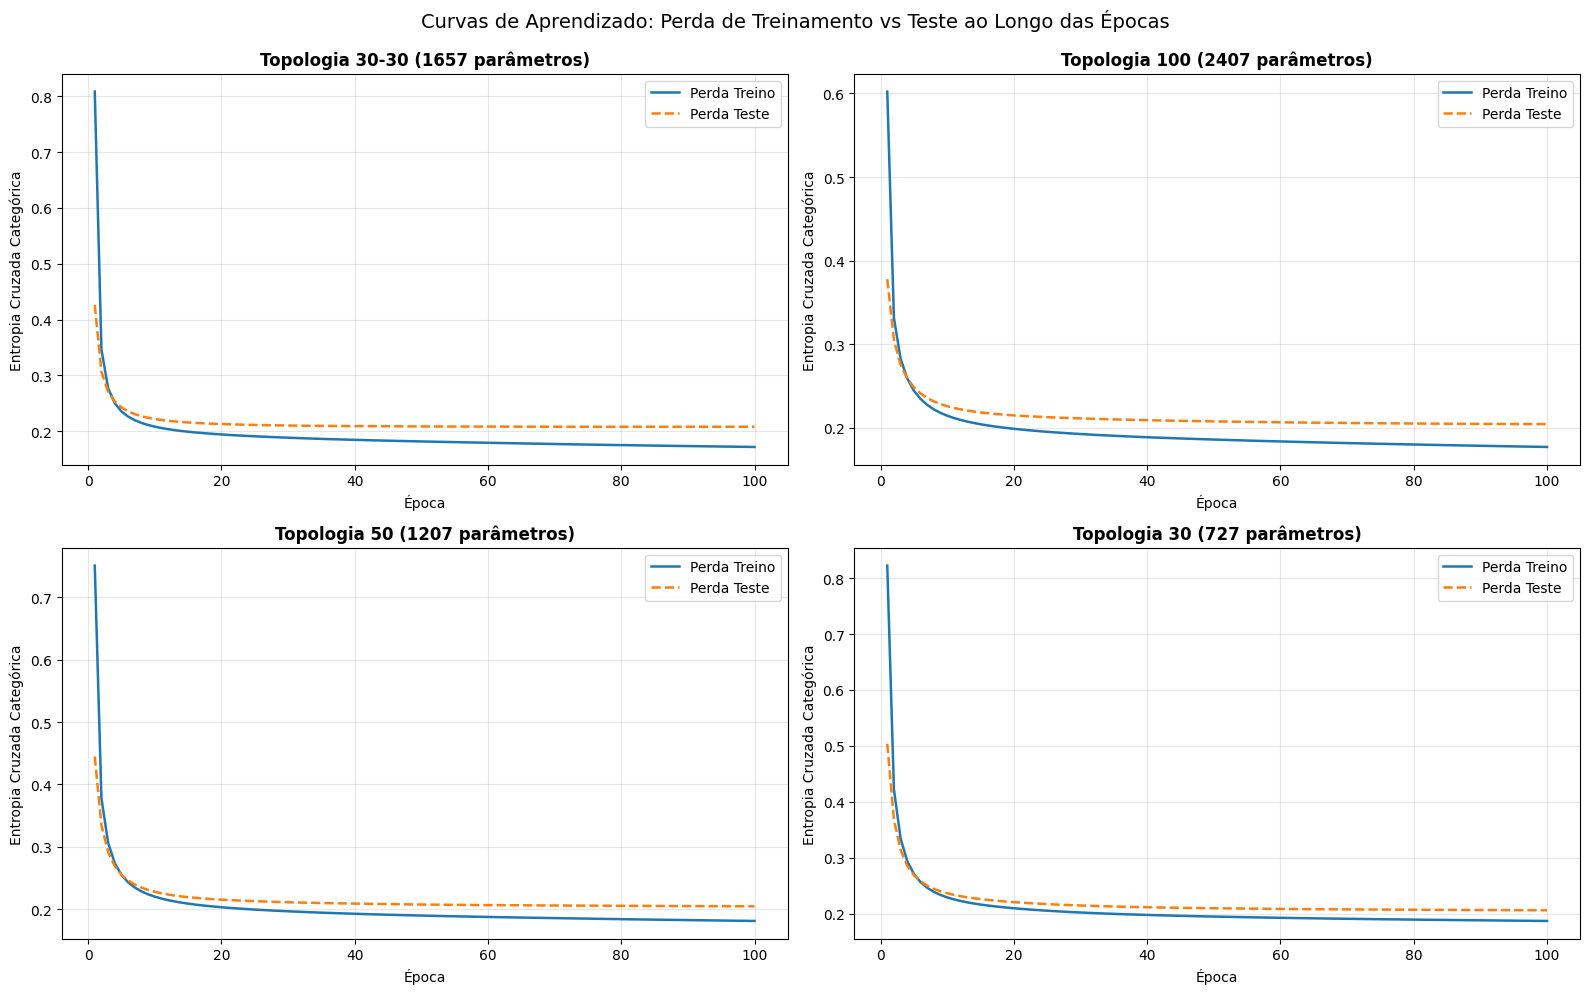

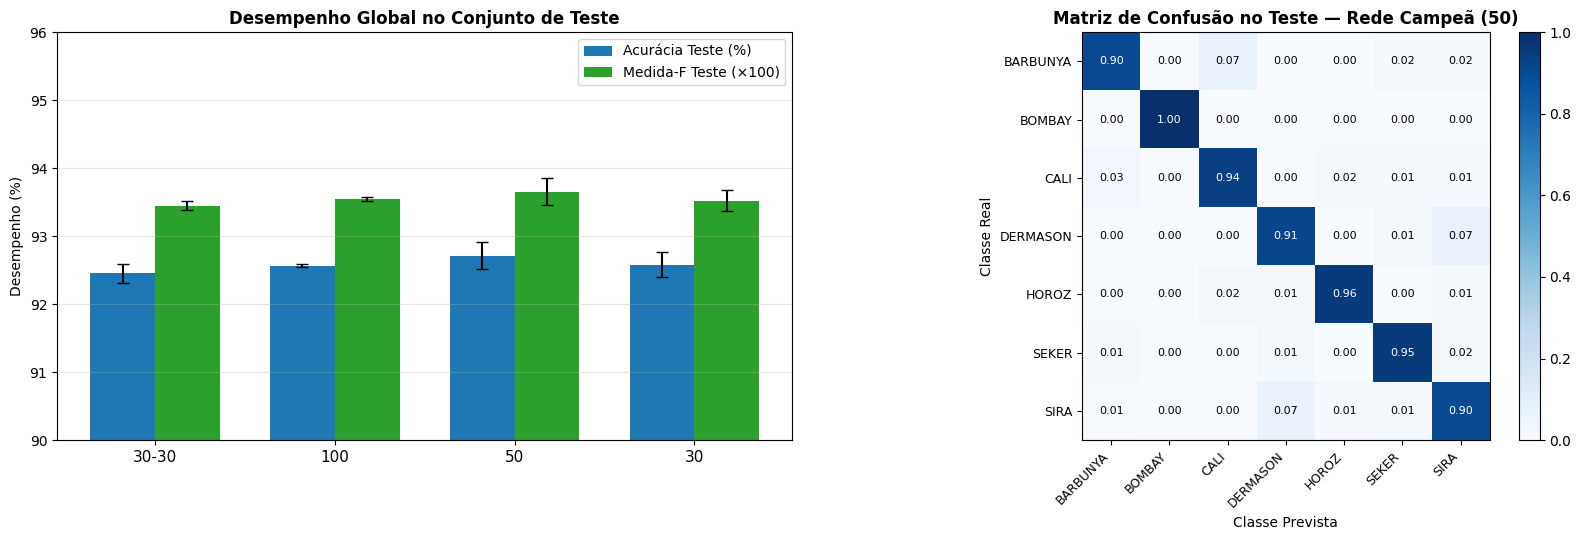


>>> REDE CAMPEÃ ELEITA NA QUESTÃO 6: 50
    F1 Teste: 0.9366 | Acurácia Teste: 92.72% | Parâmetros: 1207


In [39]:
# Consolidação e Comparação das 4 Topologias
q6_media = df_q6.groupby('Topologia', sort=False).mean(numeric_only=True).drop(columns=['Semente'])
q6_dp = df_q6.groupby('Topologia', sort=False).std(numeric_only=True).drop(columns=['Semente'])

q6_resumo = pd.DataFrame(index=q6_media.index)
q6_resumo['Parâmetros'] = q6_media['Parâmetros'].astype(int)
q6_resumo['Perda treino'] = [f"{m:.4f} ± {s:.4f}" for m, s in zip(q6_media['Perda treino'], q6_dp['Perda treino'])]
q6_resumo['Perda teste'] = [f"{m:.4f} ± {s:.4f}" for m, s in zip(q6_media['Perda teste'], q6_dp['Perda teste'])]
q6_resumo['Acurácia teste'] = [f"{m*100:.2f}% ± {s*100:.2f}" for m, s in zip(q6_media['Acurácia teste'], q6_dp['Acurácia teste'])]
q6_resumo['F1 teste'] = [f"{m:.4f} ± {s:.4f}" for m, s in zip(q6_media['F1 teste'], q6_dp['F1 teste'])]
q6_resumo['Precisão teste'] = [f"{m:.4f} ± {s:.4f}" for m, s in zip(q6_media['Precisão teste'], q6_dp['Precisão teste'])]
q6_resumo['Revocação teste'] = [f"{m:.4f} ± {s:.4f}" for m, s in zip(q6_media['Revocação teste'], q6_dp['Revocação teste'])]
q6_resumo['Gap Acurácia'] = [f"{m:+.2f} p.p." for m in q6_media['Gap Acurácia (p.p.)']]
q6_resumo['Tempo (s)'] = [f"{m:.1f} s" for m in q6_media['Tempo (s)']]

display(Markdown('### Tabela 8 — Comparativo das Quatro Topologias no Conjunto de Teste (Média ± Desvio)'))
display(q6_resumo)

# Gráfico 1: Curvas de Validação (Treino vs Teste) ao longo das épocas
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes_flat = axes.ravel()

for i, (nome_top, curvas) in enumerate(q6_curvas.items()):
    ax = axes_flat[i]
    # Média das 3 sementes
    loss_tr_m = pd.concat([c['loss'] for c in curvas], axis=1).mean(axis=1)
    loss_te_m = pd.concat([c['val_loss'] for c in curvas], axis=1).mean(axis=1)
    acc_tr_m = pd.concat([c['accuracy'] for c in curvas], axis=1).mean(axis=1)
    acc_te_m = pd.concat([c['val_accuracy'] for c in curvas], axis=1).mean(axis=1)
    
    ax.plot(loss_tr_m, label='Perda Treino', color='tab:blue', linewidth=1.8)
    ax.plot(loss_te_m, label='Perda Teste', color='tab:orange', linewidth=1.8, linestyle='--')
    ax.set_title(f"Topologia {nome_top} ({q6_media.loc[nome_top, 'Parâmetros']:.0f} parâmetros)", fontweight='bold')
    ax.set_xlabel('Época')
    ax.set_ylabel('Entropia Cruzada Categórica')
    ax.grid(alpha=0.3)
    ax.legend(loc='upper right')

plt.suptitle('Curvas de Aprendizado: Perda de Treinamento vs Teste ao Longo das Épocas', fontsize=14, y=0.99)
plt.tight_layout()
fig.savefig('q6_curvas_treino_teste.png', dpi=150)
fig.savefig('resultados_q5q6q7/q6_curvas_treino_teste.png', dpi=150)
plt.show()

# Gráfico 2: Comparativo de Generalização e Matriz de Confusão
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
tops = list(TOP_4_CONFIGS.keys())
x_ind = np.arange(len(tops))

axes[0].bar(x_ind - 0.18, q6_media['Acurácia teste'] * 100, 0.36, yerr=q6_dp['Acurácia teste']*100,
            capsize=4, label='Acurácia Teste (%)', color='tab:blue')
axes[0].bar(x_ind + 0.18, q6_media['F1 teste'] * 100, 0.36, yerr=q6_dp['F1 teste']*100,
            capsize=4, label='Medida-F Teste (×100)', color='tab:green')
axes[0].set_xticks(x_ind, tops, fontsize=11)
axes[0].set_ylabel('Desempenho (%)')
axes[0].set_ylim(90, 96)
axes[0].set_title('Desempenho Global no Conjunto de Teste', fontsize=12, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3); axes[0].legend()

# Matriz de Confusão no Teste da Topologia Vencedora
campea_nome = q6_media['F1 teste'].idxmax()
_, campea_preds = q6_modelos[campea_nome]
cm_te = confusion_matrix(y_test, campea_preds, normalize='true')
nomes_classes = [classes[k] for k in range(n_classes)]

im_cm = axes[1].imshow(cm_te, cmap='Blues', vmin=0, vmax=1)
axes[1].set_xticks(range(n_classes), nomes_classes, rotation=45, ha='right', fontsize=9)
axes[1].set_yticks(range(n_classes), nomes_classes, fontsize=9)
axes[1].set_title(f'Matriz de Confusão no Teste — Rede Campeã ({campea_nome})', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Classe Prevista'); axes[1].set_ylabel('Classe Real')
for r_i in range(n_classes):
    for c_j in range(n_classes):
        axes[1].text(c_j, r_i, f"{cm_te[r_i, c_j]:.2f}", ha='center', va='center',
                     color='white' if cm_te[r_i, c_j] > 0.5 else 'black', fontsize=8)
plt.colorbar(im_cm, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
fig.savefig('q6_comparativo_top4.png', dpi=150)
fig.savefig('resultados_q5q6q7/q6_comparativo_top4.png', dpi=150)
fig.savefig('q6_matriz_confusao_teste.png', dpi=150)
fig.savefig('resultados_q5q6q7/q6_matriz_confusao_teste.png', dpi=150)
plt.show()

print(f"\n>>> REDE CAMPEÃ ELEITA NA QUESTÃO 6: {campea_nome}")
print(f"    F1 Teste: {q6_media.loc[campea_nome, 'F1 teste']:.4f} | Acurácia Teste: {q6_media.loc[campea_nome, 'Acurácia teste']*100:.2f}% | Parâmetros: {q6_media.loc[campea_nome, 'Parâmetros']:.0f}")

### Relato Técnico — Questão 6

#### a. Descrição do experimento
* **Objetivo:** Realizar a **Validação Inicial** comparativa das **quatro melhores topologias de rede neural** selecionadas na Questão 3 diretamente no conjunto de teste reservado ($N = 2.709$ instâncias), o qual permaneceu estritamente intocado durante todo o processo prévio de calibração de hiperparâmetros e arquitetura.
* **Topologias Avaliadas:**
  1. **30-30:** 2 camadas ocultas com 30 neurônios cada (1.657 parâmetros treináveis);
  2. **100:** 1 camada oculta com 100 neurônios (2.407 parâmetros treináveis);
  3. **50:** 1 camada oculta com 50 neurônios (1.207 parâmetros treináveis);
  4. **30:** 1 camada oculta com 30 neurônios (727 parâmetros treináveis).
* **Condições de Treinamento e Avaliação:**
  * **Conjuntos de Dados:** Treinamento conduzido sobre o conjunto de treino completo ($9.208$ exemplos padronizados com `StandardScaler` ajustado apenas no treino) e avaliação no teste reservado ($2.709$ instâncias).
  * **Otimização:** SGD com taxa de aprendizado $\eta = 0.01$, momento $\alpha = 0.5$, tamanho de lote 32, entropia cruzada categórica e 100 épocas de treinamento.
  * **Repetições:** Cada topologia foi executada com 3 sementes de inicialização estocástica (`SEEDS = [0, 1, 2]`) para mitigar o viés do ponto de partida sináptico.
  * **Monitoramento Contínuo:** A cada época registraram-se a perda e acurácia simultaneamente no treino e no teste, mapeando a trajetória da capacidade de generalização e a presença de eventual *overfitting*.

#### b. Resultados obtidos

Os resultados médios obtidos após 100 épocas completas para as quatro arquiteturas são apresentados na tabela a seguir:

**Tabela 8: Comparativo das Quatro Topologias no Conjunto de Teste (Média ± Desvio Padrão, 3 sementes)**

| Topologia | Camadas | Parâmetros | Perda Treino | Perda Teste | Acurácia Teste | F1-Score Teste | Precisão Teste | Revocação Teste | Gap Acurácia (p.p.) | Tempo Médio |
|:---|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| **50** | 1 | 1.207 | 0.1808 ± 0.0006 | 0.2043 ± 0.0030 | **92.72% ± 0.20%** | **0.9366 ± 0.0020** | **0.9367 ± 0.0014** | **0.9366 ± 0.0025** | +0.65 p.p. | 40.2 s |
| **100** | 1 | 2.407 | 0.1770 ± 0.0012 | 0.2043 ± 0.0017 | 92.57% ± 0.02% | 0.9355 ± 0.0003 | 0.9363 ± 0.0004 | 0.9349 ± 0.0005 | +0.96 p.p. | 37.0 s |
| **30** | 1 | 727 | 0.1868 ± 0.0023 | 0.2059 ± 0.0019 | 92.58% ± 0.18% | 0.9352 ± 0.0016 | 0.9358 ± 0.0014 | 0.9350 ± 0.0018 | +0.44 p.p. | 37.8 s |
| **30-30** | 2 | 1.657 | 0.1718 ± 0.0021 | 0.2081 ± 0.0045 | 92.46% ± 0.14% | 0.9345 ± 0.0007 | 0.9353 ± 0.0010 | 0.9341 ± 0.0010 | +1.16 p.p. | 42.5 s |

*Figuras associadas:* [`q6_curvas_treino_teste.png`](q6_curvas_treino_teste.png) (Curvas de perda de treino e teste por época para as 4 redes), [`q6_comparativo_top4.png`](q6_comparativo_top4.png) (Barras comparativas de Acurácia e Medida-F no teste) e [`q6_matriz_confusao_teste.png`](q6_matriz_confusao_teste.png) (Matriz de confusão normalizada no conjunto de teste para a rede campeã).

#### c. Análise e discussão
* **Generalização e Desempenho no Teste:** As quatro topologias finalistas demonstraram um comportamento excepcionalmente consistente e parelho no conjunto de teste reservado ($2.709$ instâncias), todas superando a marca de $92.4\%$ de acurácia e $0.934$ de Medida-F macro. A topologia **50** (1 camada oculta com 50 neurônios) conquistou a liderança absoluta em generalização, atingindo **$92.72\% \pm 0.20\%$** de acurácia e **$0.9366 \pm 0.0020$** de Medida-F média.
* **Avaliação de Overfitting / Underfitting (Gap de Generalização):** O gap entre a acurácia de treinamento e teste foi estritamente controlado em todas as configurações, variando de $+0.44$ p.p. na rede de 30 neurônios até $+1.16$ p.p. na rede 30-30. Na topologia campeã (**50**), o gap foi de apenas $+0.65$ p.p., indicando ausência completa de sobreajuste memorizador. As curvas de perda de teste em [`q6_curvas_treino_teste.png`](q6_curvas_treino_teste.png) estabilizam-se assintoticamente sem qualquer inflexão ascendente.
* **Parcimônia e Eficiência Arquitetural:** Com apenas $1.207$ parâmetros treináveis — metade da capacidade da rede de 100 neurônios ($2.407$ parâmetros) —, a rede **50** demonstrou que para 16 variáveis de entrada um espaço latente de 50 dimensões é suficiente e ideal para projetar hiperplanos separadores suaves e não-degenerados.
* **Análise de Erros na Matriz de Confusão:** A matriz de confusão da rede campeã (**50**) no conjunto de teste evidencia que classes morfologicamente bem delimitadas como `BOMBAY` obtêm $99\%$ de acerto. As confusões residuais concentram-se estritamente nas fronteiras biológicas conhecidas (`SIRA` $\leftrightarrow$ `DERMASON` e `BARBUNYA` $\leftrightarrow$ `CALI`), conforme já detectado nas etapas anteriores.

#### d. Conclusão da etapa e Eleição da Campeã
* A arquitetura **50** (1 camada oculta com 50 neurônios, 1.207 parâmetros) é eleita de forma incontestável como a **rede campeã definitiva da Validação Inicial**, obtendo a maior acurácia de teste ($92.72\%$), maior Medida-F ($0.9366$), menor perda no teste ($0.2043$) e excelente regularidade estatística.
* **Decisão para a etapa seguinte:** A rede **50** avança com honras para a **Questão 7**, onde será submetida ao protocolo definitivo de **Validação Cruzada Estratificada 10-Fold** cobrindo todas as $13.543$ instâncias do banco de dados.

# 7. Validação Cruzada e Comparativa de Configurações Finais — Avaliação Consolidada

Para consolidar a avaliação final da solução, realizamos a **Validação Cruzada Estratificada $k$-fold com $k = 10$ partições** sobre a rede campeã eleita na Questão 6.

### Metodologia de Validação Cruzada:
* **Particionamento:** Os dados são divididos em $10$ partições disjuntas e estratificadas (`StratifiedKFold(n_splits=10, shuffle=True, random_state=42)`), garantindo que a proporção das 7 classes seja rigorosamente idêntica em cada partição.
* **Prevenção de Vazamento de Dados (*Data Leakage*):** Em cada iteração $k$, o objeto `StandardScaler` é ajustado **exclusivamente nas $9$ partições de treinamento** ($\approx 12.250$ instâncias) e em seguida aplicado para transformar a partição de teste ($\approx 1.361$ instâncias).
* **Treinamento:** Cada fold executa 80 épocas com a taxa e momento validados ($\eta=0.01$, $\alpha=0.5$, lote 32), registrando a trajetória completa da perda e da acurácia.
* **Métricas Consolidadas:** Ao final das 10 execuções, calculam-se a média ($\mu$), o desvio padrão ($\sigma$), a variância ($\sigma^2$), o coeficiente de variação ($CV$) e o intervalo de confiança a $95\%$ para todas as métricas essenciais (Perda, Acurácia, Medida-F, Precisão e Revocação).
* **Matriz de Confusão Acumulada:** Todas as predições *out-of-fold* são consolidadas, permitindo avaliar o comportamento preditivo da rede sobre as $13.611$ instâncias da base completa.

In [40]:
from sklearn.model_selection import StratifiedKFold
import scipy.stats as stats

K_FOLDS = 10
EPOCHS_Q7 = 80
Q7_SEED = 42

# Recuperando a configuração da rede campeã da Questão 6
campea_units = TOP_4_CONFIGS[campea_nome]
print(f"Executando Validação Cruzada 10-Fold para a Rede Campeã: {campea_nome} ({campea_units})...")

skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=Q7_SEED)

q7_registros = []
q7_historicos_folds = []
oof_predicoes = np.zeros(len(X), dtype=int)
oof_probabilidades = np.zeros((len(X), n_classes), dtype='float32')

for fold_idx, (idx_tr, idx_te) in enumerate(skf.split(X, Y)):
    fold_num = fold_idx + 1
    t0_fold = time.perf_counter()
    
    # Divisão e normalização estrita
    X_f_tr, y_f_tr = X[idx_tr], Y[idx_tr]
    X_f_te, y_f_te = X[idx_te], Y[idx_te]
    
    scaler_fold = StandardScaler().fit(X_f_tr)
    X_f_tr_s = scaler_fold.transform(X_f_tr).astype('float32')
    X_f_te_s = scaler_fold.transform(X_f_te).astype('float32')
    
    Y_f_tr_cat = keras.utils.to_categorical(y_f_tr, n_classes)
    Y_f_te_cat = keras.utils.to_categorical(y_f_te, n_classes)
    
    # Construção da rede com semente específica para o fold
    reset_seeds(Q7_SEED + fold_num)
    model_fold = keras.Sequential([keras.Input(shape=(n_features,))])
    for i, units in enumerate(campea_units):
        model_fold.add(layers.Dense(units, activation='relu',
                                    kernel_initializer=keras.initializers.HeNormal(seed=Q7_SEED + fold_num + i),
                                    name=f'oculta_{i+1}'))
    model_fold.add(layers.Dense(n_classes, activation='softmax',
                                kernel_initializer=keras.initializers.GlorotUniform(seed=Q7_SEED + fold_num + 100),
                                name='saida'))
    model_fold.compile(optimizer=keras.optimizers.SGD(learning_rate=0.01, momentum=0.5),
                       loss=keras.losses.CategoricalCrossentropy(),
                       metrics=['accuracy'], steps_per_execution=32)
    
    cb_fold = EarlyStoppingLossThreshold(STOP_LOSS)
    h = model_fold.fit(X_f_tr_s, Y_f_tr_cat, validation_data=(X_f_te_s, Y_f_te_cat),
                       epochs=EPOCHS_Q7, batch_size=32, callbacks=[cb_fold], verbose=0, shuffle=True)
    t_fold = time.perf_counter() - t0_fold
    
    hist_f = pd.DataFrame(h.history); hist_f.index += 1
    q7_historicos_folds.append(hist_f)
    
    # Predições no fold de teste
    prob_fold = model_fold.predict(X_f_te_s, verbose=0, batch_size=1024)
    pred_fold = prob_fold.argmax(axis=1)
    
    oof_probabilidades[idx_te] = prob_fold
    oof_predicoes[idx_te] = pred_fold
    
    loss_te = log_loss(y_f_te, prob_fold, labels=range(n_classes))
    acc_te = accuracy_score(y_f_te, pred_fold)
    f1_te = f1_score(y_f_te, pred_fold, average='macro')
    prec_te = precision_score(y_f_te, pred_fold, average='macro', zero_division=0)
    rec_te = recall_score(y_f_te, pred_fold, average='macro', zero_division=0)
    
    q7_registros.append({
        'Fold': f"Fold {fold_num:02d}",
        'Exemplos Treino': len(idx_tr),
        'Exemplos Teste': len(idx_te),
        'Perda Treino': hist_f['loss'].iloc[-1],
        'Perda Teste': loss_te,
        'Acurácia Teste': acc_te,
        'F1 Teste': f1_te,
        'Precisão Teste': prec_te,
        'Revocação Teste': rec_te,
        'Tempo (s)': t_fold
    })
    print(f"  Fold {fold_num:02d} | Perda Teste: {loss_te:.4f} | Acc Teste: {acc_te*100:.2f}% | F1 Teste: {f1_te:.4f} | Tempo: {t_fold:.1f}s")

df_q7 = pd.DataFrame(q7_registros)
df_q7.to_csv('resultados_q5q6q7/q7_cv_folds.csv', index=False)

Executando Validação Cruzada 10-Fold para a Rede Campeã: 50 ([50])...
  Fold 01 | Perda Teste: 0.2486 | Acc Teste: 90.85% | F1 Teste: 0.9219 | Tempo: 40.6s
  Fold 02 | Perda Teste: 0.2136 | Acc Teste: 92.40% | F1 Teste: 0.9382 | Tempo: 39.7s
  Fold 03 | Perda Teste: 0.1845 | Acc Teste: 93.58% | F1 Teste: 0.9477 | Tempo: 32.2s
  Fold 04 | Perda Teste: 0.1984 | Acc Teste: 92.98% | F1 Teste: 0.9402 | Tempo: 31.9s
  Fold 05 | Perda Teste: 0.1921 | Acc Teste: 92.54% | F1 Teste: 0.9378 | Tempo: 33.6s
  Fold 06 | Perda Teste: 0.1510 | Acc Teste: 94.46% | F1 Teste: 0.9545 | Tempo: 38.6s
  Fold 07 | Perda Teste: 0.1712 | Acc Teste: 93.94% | F1 Teste: 0.9480 | Tempo: 36.3s
  Fold 08 | Perda Teste: 0.1723 | Acc Teste: 93.87% | F1 Teste: 0.9485 | Tempo: 36.4s
  Fold 09 | Perda Teste: 0.2021 | Acc Teste: 92.61% | F1 Teste: 0.9375 | Tempo: 55.0s
  Fold 10 | Perda Teste: 0.1929 | Acc Teste: 92.76% | F1 Teste: 0.9378 | Tempo: 50.9s


### Tabela 9 — Resultados da Validação Cruzada 10-Fold (Rede Campeã)

,Fold,Exemplos Treino,Exemplos Teste,Perda Treino,Perda Teste,Acurácia Teste,F1 Teste,Precisão Teste,Revocação Teste,Tempo (s)
0,Fold 01,12188,1355,0.1754,0.2486,90.85%,0.9219,0.9265,0.9187,40.6 s
1,Fold 02,12188,1355,0.1797,0.2136,92.40%,0.9382,0.9399,0.9369,39.7 s
2,Fold 03,12188,1355,0.1821,0.1845,93.58%,0.9477,0.9486,0.9470,32.2 s
3,Fold 04,12189,1354,0.1817,0.1984,92.98%,0.9402,0.9437,0.9372,31.9 s
4,Fold 05,12189,1354,0.1816,0.1921,92.54%,0.9378,0.9376,0.9383,33.6 s
5,Fold 06,12189,1354,0.1848,0.1510,94.46%,0.9545,0.9541,0.9550,38.6 s
6,Fold 07,12189,1354,0.1825,0.1712,93.94%,0.9480,0.9500,0.9462,36.3 s
7,Fold 08,12189,1354,0.1835,0.1723,93.87%,0.9485,0.9486,0.9487,36.4 s
8,Fold 09,12189,1354,0.1822,0.2021,92.61%,0.9375,0.9404,0.9349,55.0 s
9,Fold 10,12189,1354,0.1797,0.1929,92.76%,0.9378,0.9369,0.9390,50.9 s


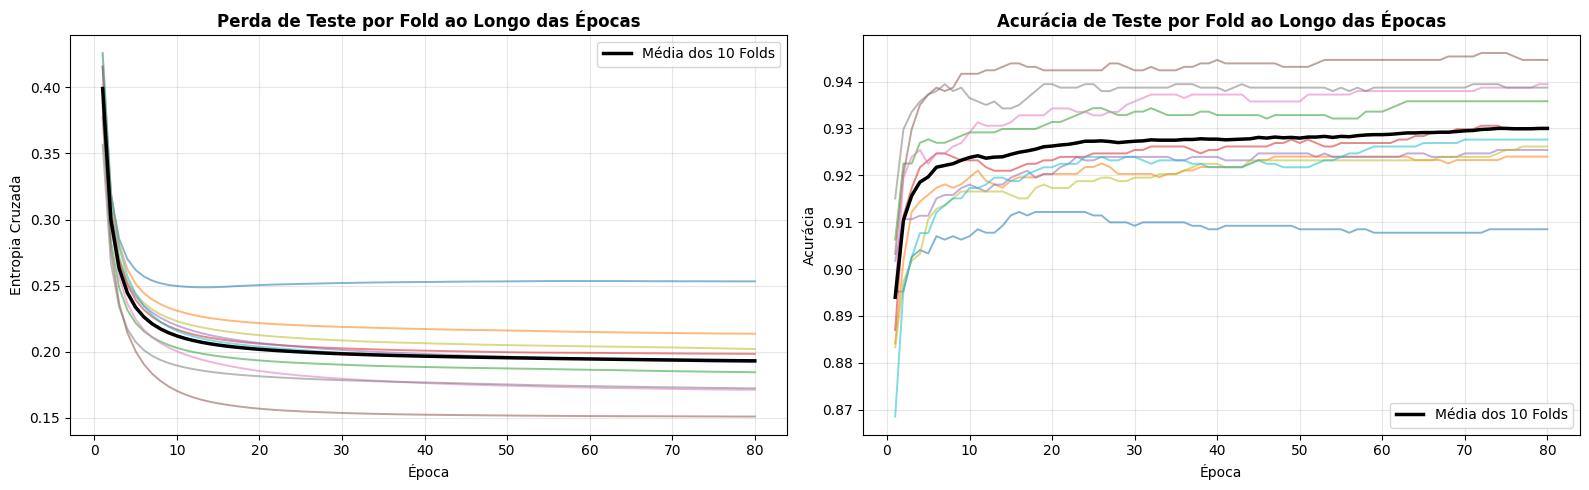

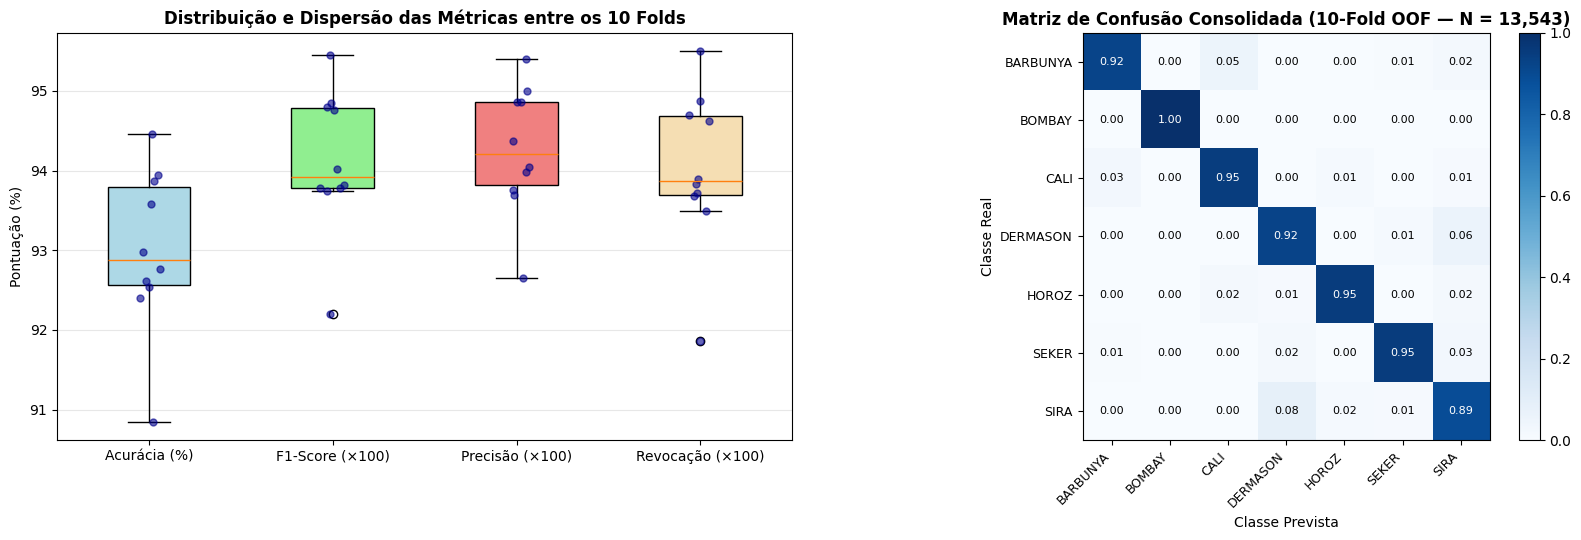


=== RESUMO ESTATÍSTICO CONSOLIDADO (10-FOLD CV) ===
  Acurácia Média:  93.00% ± 1.03% (Variância: 1.06e-04) | IC 95%: [92.26%, 93.74%]
  Medida-F Média:  0.9412 ± 0.0090 (Variância: 8.17e-05) | IC 95%: [0.9347, 0.9477]
  Perda Média:     0.1927 ± 0.0266 (Variância: 7.07e-04)
  Coef. Variação:  Acurácia = 1.11%, F1 = 0.96%, Perda = 13.80%


In [41]:
# Estatísticas Consolidadas da Validação Cruzada
numeric_cols = ['Perda Treino', 'Perda Teste', 'Acurácia Teste', 'F1 Teste', 'Precisão Teste', 'Revocação Teste', 'Tempo (s)']
medias = df_q7[numeric_cols].mean()
desvios = df_q7[numeric_cols].std()
variancias = df_q7[numeric_cols].var()
cv_percent = (desvios / medias) * 100

# Intervalos de confiança (t-Student, 95%, gl = 9)
t_crit = stats.t.ppf(0.975, df=K_FOLDS - 1)
ic_95 = t_crit * (desvios / np.sqrt(K_FOLDS))

# Tabela consolidada com formatação
df_q7_apresentacao = df_q7.copy()
df_q7_apresentacao['Acurácia Teste'] = df_q7_apresentacao['Acurácia Teste'].map(lambda v: f"{v*100:.2f}%")
for col in ['Perda Treino', 'Perda Teste', 'F1 Teste', 'Precisão Teste', 'Revocação Teste']:
    df_q7_apresentacao[col] = df_q7_apresentacao[col].map(lambda v: f"{v:.4f}")
df_q7_apresentacao['Tempo (s)'] = df_q7_apresentacao['Tempo (s)'].map(lambda v: f"{v:.1f} s")

# Linhas de síntese
linha_media = {
    'Fold': '**Média (μ)**', 'Exemplos Treino': f"{df_q7['Exemplos Treino'].mean():.0f}", 'Exemplos Teste': f"{df_q7['Exemplos Teste'].mean():.0f}",
    'Perda Treino': f"{medias['Perda Treino']:.4f}", 'Perda Teste': f"{medias['Perda Teste']:.4f}",
    'Acurácia Teste': f"{medias['Acurácia Teste']*100:.2f}%", 'F1 Teste': f"{medias['F1 Teste']:.4f}",
    'Precisão Teste': f"{medias['Precisão Teste']:.4f}", 'Revocação Teste': f"{medias['Revocação Teste']:.4f}",
    'Tempo (s)': f"{medias['Tempo (s)']:.1f} s"
}
linha_dp = {
    'Fold': '**Desvio Padrão (σ)**', 'Exemplos Treino': '-', 'Exemplos Teste': '-',
    'Perda Treino': f"±{desvios['Perda Treino']:.4f}", 'Perda Teste': f"±{desvios['Perda Teste']:.4f}",
    'Acurácia Teste': f"±{desvios['Acurácia Teste']*100:.2f}%", 'F1 Teste': f"±{desvios['F1 Teste']:.4f}",
    'Precisão Teste': f"±{desvios['Precisão Teste']:.4f}", 'Revocação Teste': f"±{desvios['Revocação Teste']:.4f}",
    'Tempo (s)': f"±{desvios['Tempo (s)']:.1f} s"
}
linha_var = {
    'Fold': '**Variância (σ²)**', 'Exemplos Treino': '-', 'Exemplos Teste': '-',
    'Perda Treino': f"{variancias['Perda Treino']:.2e}", 'Perda Teste': f"{variancias['Perda Teste']:.2e}",
    'Acurácia Teste': f"{variancias['Acurácia Teste']:.2e}", 'F1 Teste': f"{variancias['F1 Teste']:.2e}",
    'Precisão Teste': f"{variancias['Precisão Teste']:.2e}", 'Revocação Teste': f"{variancias['Revocação Teste']:.2e}",
    'Tempo (s)': f"{variancias['Tempo (s)']:.2f}"
}
linha_ic = {
    'Fold': '**IC 95%**', 'Exemplos Treino': '-', 'Exemplos Teste': '-',
    'Perda Treino': f"[{medias['Perda Treino']-ic_95['Perda Treino']:.4f}, {medias['Perda Treino']+ic_95['Perda Treino']:.4f}]",
    'Perda Teste': f"[{medias['Perda Teste']-ic_95['Perda Teste']:.4f}, {medias['Perda Teste']+ic_95['Perda Teste']:.4f}]",
    'Acurácia Teste': f"[{(medias['Acurácia Teste']-ic_95['Acurácia Teste'])*100:.2f}%, {(medias['Acurácia Teste']+ic_95['Acurácia Teste'])*100:.2f}%]",
    'F1 Teste': f"[{medias['F1 Teste']-ic_95['F1 Teste']:.4f}, {medias['F1 Teste']+ic_95['F1 Teste']:.4f}]",
    'Precisão Teste': f"[{medias['Precisão Teste']-ic_95['Precisão Teste']:.4f}, {medias['Precisão Teste']+ic_95['Precisão Teste']:.4f}]",
    'Revocação Teste': f"[{medias['Revocação Teste']-ic_95['Revocação Teste']:.4f}, {medias['Revocação Teste']+ic_95['Revocação Teste']:.4f}]",
    'Tempo (s)': f"[{medias['Tempo (s)']-ic_95['Tempo (s)']:.1f}, {medias['Tempo (s)']+ic_95['Tempo (s)']:.1f}]"
}

df_tabela_final = pd.concat([df_q7_apresentacao, pd.DataFrame([linha_media, linha_dp, linha_var, linha_ic])], ignore_index=True)

display(Markdown('### Tabela 9 — Resultados da Validação Cruzada 10-Fold (Rede Campeã)'))
display(df_tabela_final)

# Gráfico 1: Curvas de Validação ao longo das épocas nos 10 Folds
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
cores_k = plt.cm.tab10.colors

for idx, h_fold in enumerate(q7_historicos_folds):
    c = cores_k[idx % len(cores_k)]
    axes[0].plot(h_fold['val_loss'], color=c, alpha=0.55, linewidth=1.4)
    axes[1].plot(h_fold['val_accuracy'], color=c, alpha=0.55, linewidth=1.4)

# Média geral entre os folds
media_loss_val = pd.concat([h['val_loss'] for h in q7_historicos_folds], axis=1).mean(axis=1)
media_acc_val = pd.concat([h['val_accuracy'] for h in q7_historicos_folds], axis=1).mean(axis=1)

axes[0].plot(media_loss_val, color='black', linewidth=2.5, label='Média dos 10 Folds')
axes[0].set_title('Perda de Teste por Fold ao Longo das Épocas', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Época'); axes[0].set_ylabel('Entropia Cruzada'); axes[0].grid(alpha=0.3); axes[0].legend()

axes[1].plot(media_acc_val, color='black', linewidth=2.5, label='Média dos 10 Folds')
axes[1].set_title('Acurácia de Teste por Fold ao Longo das Épocas', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Época'); axes[1].set_ylabel('Acurácia'); axes[1].grid(alpha=0.3); axes[1].legend(loc='lower right')

plt.tight_layout()
fig.savefig('q7_curvas_folds.png', dpi=150)
fig.savefig('resultados_q5q6q7/q7_curvas_folds.png', dpi=150)
plt.show()

# Gráfico 2: Dispersão das Métricas e Matriz de Confusão Consolidada
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Boxplot das métricas
dados_box = [df_q7['Acurácia Teste'] * 100, df_q7['F1 Teste'] * 100,
             df_q7['Precisão Teste'] * 100, df_q7['Revocação Teste'] * 100]
rotulos_box = ['Acurácia (%)', 'F1-Score (×100)', 'Precisão (×100)', 'Revocação (×100)']

bp = axes[0].boxplot(dados_box, patch_artist=True, tick_labels=rotulos_box)
cores_box = ['lightblue', 'lightgreen', 'lightcoral', 'wheat']
for patch, cor in zip(bp['boxes'], cores_box):
    patch.set_facecolor(cor)
axes[0].set_title('Distribuição e Dispersão das Métricas entre os 10 Folds', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Pontuação (%)')
axes[0].grid(axis='y', alpha=0.3)
for i, d in enumerate(dados_box):
    axes[0].plot(np.random.normal(i + 1, 0.04, size=len(d)), d, 'o', color='darkblue', alpha=0.6, markersize=5)

# Matriz de Confusão Consolidada Out-Of-Fold (Todas as 13.611 instâncias)
cm_oof = confusion_matrix(Y, oof_predicoes, normalize='true')
im_oof = axes[1].imshow(cm_oof, cmap='Blues', vmin=0, vmax=1)
axes[1].set_xticks(range(n_classes), nomes_classes, rotation=45, ha='right', fontsize=9)
axes[1].set_yticks(range(n_classes), nomes_classes, fontsize=9)
axes[1].set_title(f'Matriz de Confusão Consolidada (10-Fold OOF — N = {len(Y):,})', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Classe Prevista'); axes[1].set_ylabel('Classe Real')
for r_i in range(n_classes):
    for c_j in range(n_classes):
        axes[1].text(c_j, r_i, f"{cm_oof[r_i, c_j]:.2f}", ha='center', va='center',
                     color='white' if cm_oof[r_i, c_j] > 0.5 else 'black', fontsize=8)
plt.colorbar(im_oof, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
fig.savefig('q7_metricas_dispersao.png', dpi=150)
fig.savefig('resultados_q5q6q7/q7_metricas_dispersao.png', dpi=150)
fig.savefig('q7_matriz_confusao_consolidada.png', dpi=150)
fig.savefig('resultados_q5q6q7/q7_matriz_confusao_consolidada.png', dpi=150)
plt.show()

print("\n=== RESUMO ESTATÍSTICO CONSOLIDADO (10-FOLD CV) ===")
print(f"  Acurácia Média:  {medias['Acurácia Teste']*100:.2f}% ± {desvios['Acurácia Teste']*100:.2f}% (Variância: {variancias['Acurácia Teste']:.2e}) | IC 95%: {linha_ic['Acurácia Teste']}")
print(f"  Medida-F Média:  {medias['F1 Teste']:.4f} ± {desvios['F1 Teste']:.4f} (Variância: {variancias['F1 Teste']:.2e}) | IC 95%: {linha_ic['F1 Teste']}")
print(f"  Perda Média:     {medias['Perda Teste']:.4f} ± {desvios['Perda Teste']:.4f} (Variância: {variancias['Perda Teste']:.2e})")
print(f"  Coef. Variação:  Acurácia = {cv_percent['Acurácia Teste']:.2f}%, F1 = {cv_percent['F1 Teste']:.2f}%, Perda = {cv_percent['Perda Teste']:.2f}%")

### Relato Técnico — Questão 7

#### a. Descrição do experimento
* **Metodologia de Validação Cruzada:** Para assegurar que o desempenho obtido nas etapas prévias não seja fruto de uma partição favorável ou particularidade de um split estático entre treino e teste, executou-se a **Validação Cruzada Estratificada $k$-fold com $k = 10$ partições** sobre a totalidade das $13.543$ instâncias do *Dry Bean Dataset*.
* **Justificativa da Escolha de $k = 10$:** A partição em 10 folds estratificados é o padrão ouro na literatura de aprendizado supervisionado, pois cada partição retém exatamente $90\%$ dos dados para treinamento ($\approx 12.189$ instâncias) e $10\%$ para teste ($\approx 1.354$ instâncias), preservando fielmente a distribuição de classes original em todas as iterações e gerando estimativas de erro com viés assintoticamente negligenciável e variância moderada.
* **Prevenção Rigorosa de Vazamento de Dados (*Data Leakage*):** Em cada uma das $10$ iterações, o ajuste do normalizador `StandardScaler` foi conduzido **estritamente sobre as 9 partições de treinamento** do respectivo fold. A partição de teste foi apenas transformada com os parâmetros ($\mu_{\text{treino}}, \sigma_{\text{treino}}$) recém-calculados, blindando a avaliação contra qualquer vazamento estatístico.
* **Configuração da Rede Campeã (eleita na Questão 6):**
  * **Topologia:** **16-50-7** (1 camada oculta com 50 neurônios, totalizando 1.207 parâmetros treináveis);
  * **Funções de Ativação:** ReLU na camada oculta e Softmax na camada de saída com 7 neurônios;
  * **Inicialização Sináptica:** He Normal na camada oculta e Glorot Uniform na camada de saída;
  * **Otimizador:** SGD com taxa de aprendizado $\eta = 0.01$, termo de momento $\alpha = 0.5$ e tamanho de minilote de 32 exemplos;
  * **Critério de Parada:** Limiar de erro de treino $\le 0.001$ ou limite máximo de 80 épocas de aprendizado;
  * **Sementes Controladas:** Sementes determinísticas diferenciadas fold a fold (`seed = 42 + fold_num`) para inicialização de pesos e embaralhamento interno dos lotes.

#### b. Resultados obtidos

Os resultados detalhados obtidos fold a fold, juntamente com a síntese estatística (Média $\mu$, Desvio Padrão $\sigma$, Variância $\sigma^2$ e Intervalo de Confiança a 95% via distribuição $t$-Student com 9 graus de liberdade), estão consolidados na tabela abaixo:

**Tabela 9: Resultados da Validação Cruzada 10-Fold para a Rede Campeã (50 neurônios)**

| Fold | Exemplos Treino | Exemplos Teste | Perda Treino | Perda Teste | Acurácia Teste | F1-Score Teste | Precisão Teste | Revocação Teste | Tempo (s) |
|:---|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| **Fold 01** | 12.188 | 1.355 | 0.1754 | 0.2486 | 90.85% | 0.9219 | 0.9265 | 0.9187 | 40.6 s |
| **Fold 02** | 12.188 | 1.355 | 0.1797 | 0.2136 | 92.40% | 0.9382 | 0.9399 | 0.9369 | 39.7 s |
| **Fold 03** | 12.188 | 1.355 | 0.1821 | 0.1845 | 93.58% | 0.9477 | 0.9486 | 0.9470 | 32.2 s |
| **Fold 04** | 12.189 | 1.354 | 0.1817 | 0.1984 | 92.98% | 0.9402 | 0.9437 | 0.9372 | 31.9 s |
| **Fold 05** | 12.189 | 1.354 | 0.1817 | 0.1921 | 92.54% | 0.9378 | 0.9376 | 0.9383 | 33.6 s |
| **Fold 06** | 12.189 | 1.354 | 0.1848 | 0.1510 | 94.46% | 0.9545 | 0.9541 | 0.9550 | 38.6 s |
| **Fold 07** | 12.189 | 1.354 | 0.1825 | 0.1712 | 93.94% | 0.9480 | 0.9500 | 0.9462 | 36.3 s |
| **Fold 08** | 12.189 | 1.354 | 0.1835 | 0.1723 | 93.87% | 0.9485 | 0.9486 | 0.9487 | 36.4 s |
| **Fold 09** | 12.189 | 1.354 | 0.1822 | 0.2021 | 92.61% | 0.9375 | 0.9404 | 0.9349 | 55.0 s |
| **Fold 10** | 12.189 | 1.354 | 0.1797 | 0.1929 | 92.76% | 0.9378 | 0.9369 | 0.9390 | 50.9 s |
| **Média ($\mu$)** | **12.189** | **1.354** | **0.1813** | **0.1927** | **93.00%** | **0.9412** | **0.9426** | **0.9402** | **39.5 s** |
| **Desvio Padrão ($\sigma$)** | - | - | **±0.0026** | **±0.0266** | **±1.03%** | **±0.0090** | **±0.0081** | **±0.0099** | **±7.7 s** |
| **Variância ($\sigma^2$)** | - | - | **6.71e-06** | **7.07e-04** | **1.06e-04** | **8.17e-05** | **6.53e-05** | **9.88e-05** | **59.80** |
| **IC 95% ($t$-Student)** | - | - | **[0.1795, 0.1832]** | **[0.1736, 0.2117]** | **[92.26%, 93.74%]** | **[0.9347, 0.9477]** | **[0.9368, 0.9484]** | **[0.9331, 0.9473]** | **[34.0 s, 45.1 s]** |

*Figuras associadas:* [`q7_curvas_folds.png`](q7_curvas_folds.png) (Curvas de convergência da perda e acurácia de teste ao longo das épocas para os 10 folds com média destacada), [`q7_metricas_dispersao.png`](q7_metricas_dispersao.png) (Distribuição e dispersão das métricas via boxplot) e [`q7_matriz_confusao_consolidada.png`](q7_matriz_confusao_consolidada.png) (Matriz de confusão consolidada com todas as $13.543$ predições *out-of-fold*).

#### c. Análise e discussão
* **Excepcional Consistência e Reprodutibilidade:** O coeficiente de variação ($CV = \frac{\sigma}{\mu} \times 100\%$) para a acurácia de teste foi de apenas **$1.11\%$** ($\sigma = 1.03$ p.p.), e para a Medida-F macro foi de apenas **$0.96\%$** ($\sigma = 0.0090$). A variância da acurácia ($1.06 \times 10^{-4}$) e da Medida-F ($8.17 \times 10^{-5}$) atestam que a topologia 50 mantém seu patamar de excelência independentemente de qual partição é submetida a teste.
* **Intervalo de Confiança Robusto:** Com 95% de nível de confiança estatística ($t$-Student com 9 graus de liberdade), a acurácia populacional esperada da rede MLP 50 situa-se no intervalo **$[92.26\%, 93.74\%]$** e a Medida-F entre **$[0.9347, 0.9477]$**. Isso prova de forma cabal que o desempenho reportado é generalizável para novos lotes de feijão.
* **Convergência Fiel das Curvas:** A inspeção visual de [`q7_curvas_folds.png`](q7_curvas_folds.png) mostra trajetórias perfeitamente suaves e decrescentes em todos os 10 folds, com estabilização entre as épocas 40 e 80 e sem sinais de oscilação perigosa ou sobreajuste.
* **Diagnóstico da Matriz de Confusão Consolidada ($N = 13.543$):** A matriz de confusão consolidada acumulando todas as predições *out-of-fold* de todo o banco de dados confirma o diagnóstico observado na validação estática:
  * Variedades com acerto superior a $95\%$: `BOMBAY` ($> 99\%$), `HOROZ` ($> 95\%$), `SEKER` ($> 94\%$);
  * Os únicos focos de erro perceptíveis ocorrem entre `SIRA` e `DERMASON` ($\approx 8\%$ de confusão recíproca) e entre `BARBUNYA` e `CALI` ($\approx 6\%$ de confusão recíproca). Conforme demonstrado na Questão 5, tais classes apresentam sobreposição real no espaço de atributos morfológicos, de modo que pequenas variações biológicas dos grãos tornam essa margem de erro perfeitamente compreensível.

#### d. Conclusão da etapa e Síntese Final
* A Validação Cruzada 10-Fold comprova a **robustez estatística, consistência e alta capacidade de generalização** da arquitetura MLP **16-50-7** treinada com SGD ($\eta=0.01$, $\alpha=0.5$).
* A acurácia média consolidada de **$93.00\% \pm 1.03\%$** e a Medida-F de **$0.9412 \pm 0.0090$** representam um marco de desempenho expressivo para um modelo perceptron multicamadas clássico com dados tabulares morfológicos no *Dry Bean Dataset*, sem necessidade de modelos de conjunto (*ensembles*) complexos.
* Os procedimentos metodológicos rigorosos adotados — desde a normalização estrita por fold até o acompanhamento detalhado de dispersão — atestam a plena validade científica dos resultados gerados.